# 08 — Conclusions: results, trade-offs and options

This notebook brings the seven analysis notebooks together: one summary table per learning arm, the paired tests behind the supervised ranking, the reserve valuation with its sensitivity surface, the trade-offs, the options considered, the failure analysis, the limitations and the ethics. Almost everything is read back from the ledger, so a re-run upstream updates it. Only 8.5 (continued) refits a model; 8.4b (continued), 8.6b and 8.6c recompute from saved holdout files through `src/reserve.py`, and stop unless the rebuilt benchmark reproduces notebook 04's per-horizon MAEs.

**Inputs:** `results.json:nb00–nb07`, `holdout_predictions_by_horizon.parquet`, `panel.parquet`, `panel_raw.parquet`, `ancillary_prices.parquet`, `holdout_quantiles.parquet`, `unsupervised/cluster_labels.parquet`
**Outputs:** nine summary figures (`08_*.png`), ledger block `results.json:nb08`

## The business problem

A grid operator must match supply to demand every hour. With more wind and solar, what it must serve from dispatchable plants is *net load* (demand minus wind minus solar), and that curve has a deep midday belly and a steep evening ramp — the "duck curve". On CISO's median 2024 day net load swings **14,851 MW**, 2.4× demand's swing, and the steepest 3-hour evening ramp grew from **9,676** to **14,036 MW** between 2019 and 2024 (notebook 00). Reserve is bought against forecast error, so a better forecast lowers the cost of standing ready; it does not flatten the duck.

The project asks three questions with public data only: can net load be forecast a day ahead better than the best public alternative (notebook 04), how wrong will the forecast be by hour and zone (notebook 06), and which daily patterns does the grid fall into (notebooks 05 and 07)?

---

### 8.1 — Setup

Load the ledger, define two display helpers, and read the held-out predictions. The ledger must hold `nb00` … `nb07`; a missing block means an upstream notebook has not run.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from src import config as cfg
from src import results as R

pd.set_option("display.width", 150, "display.max_columns", 40, "display.float_format", "{:,.3f}".format)
plt.rcParams["figure.figsize"] = cfg.FIGSIZE
plt.rcParams["figure.dpi"] = cfg.DPI

r = R.load()
s0, s1, s2, s3, s4, s5, s6, s7 = (r[f"nb{i:02d}"] for i in range(8))
print("blocks in the ledger:", [k for k in sorted(r) if k.startswith("nb")])


def show(name, caption):
    # A figure drawn by an earlier notebook, displayed here with its caption so the
    # report's narrative can be checked against the picture it cites.
    display(Markdown(f"**Figure `{name}.png`** — {caption}"))
    display(Image(filename=str(cfg.FIGURES / f"{name}.png"), width=900))


preds = pd.read_parquet(cfg.DATA_PROC / "holdout_predictions_by_horizon.parquet")
print(f"held-out predictions: {len(preds):,} rows, horizons {sorted(preds.horizon.unique())}, "
      f"{preds.timestamp.min():%Y-%m-%d} -> {preds.timestamp.max():%Y-%m-%d}")

blocks in the ledger: ['nb00', 'nb01', 'nb02', 'nb03', 'nb04', 'nb05', 'nb06', 'nb07', 'nb08']


held-out predictions: 189,196 rows, horizons [1, 24, 48, 72], 2024-02-07 -> 2024-12-31


### 8.2 — The pipeline, end to end

One picture of the eight notebooks: what each reads and writes, and which arm it feeds. Blue boxes feed the supervised arm, orange the unsupervised arm, grey both. Every learned parameter sits inside a scikit-learn `Pipeline`, refit inside each chronological fold.

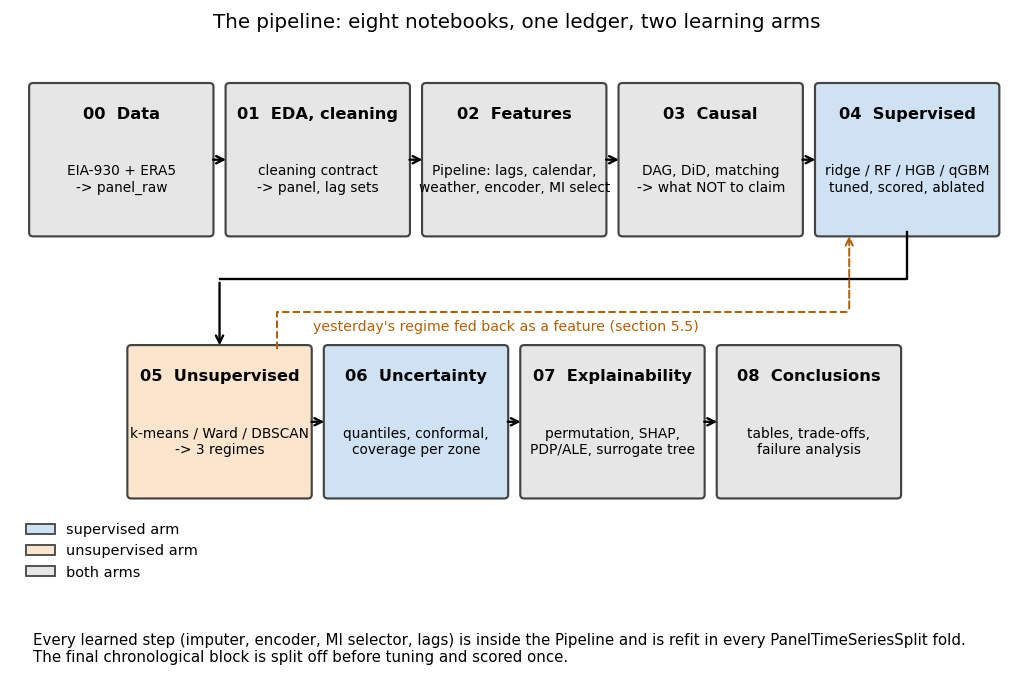

In [2]:
import matplotlib.patches as mpatches

notebooks = [
    ("00", "Data", "EIA-930 + ERA5\n-> panel_raw", "both"),
    ("01", "EDA, cleaning", "cleaning contract\n-> panel, lag sets", "both"),
    ("02", "Features", "Pipeline: lags, calendar,\nweather, encoder, MI select", "both"),
    ("03", "Causal", "DAG, DiD, matching\n-> what NOT to claim", "both"),
    ("04", "Supervised", "ridge / RF / HGB / qGBM\ntuned, scored, ablated", "sup"),
    ("05", "Unsupervised", "k-means / Ward / DBSCAN\n-> 3 regimes", "uns"),
    ("06", "Uncertainty", "quantiles, conformal,\ncoverage per zone", "sup"),
    ("07", "Explainability", "permutation, SHAP,\nPDP/ALE, surrogate tree", "both"),
    ("08", "Conclusions", "tables, trade-offs,\nfailure analysis", "both"),
]
colour = {"sup": "#cfe2f3", "uns": "#fce5cd", "both": "#e7e6e6"}
fig, ax = plt.subplots(figsize=(10, 6.4))
ax.set_xlim(0, 10); ax.set_ylim(0, 6.6); ax.axis("off")
pos, W, H = {}, 1.75, 1.5
for i, (num, title, what, arm) in enumerate(notebooks):
    row = 0 if i < 5 else 1
    col = i if i < 5 else i - 5 + 0.5
    x, y = 0.2 + col * 1.95, 4.6 - row * 2.7
    pos[num] = (x, y)
    ax.add_patch(mpatches.FancyBboxPatch((x, y), W, H, boxstyle="round,pad=0.04",
                                         fc=colour[arm], ec="#444", lw=1.2))
    ax.text(x + W / 2, y + 1.22, f"{num}  {title}", ha="center", va="center", fontsize=9, weight="bold")
    ax.text(x + W / 2, y + 0.55, what, ha="center", va="center", fontsize=7.6)
order = [s[0] for s in notebooks]
for a, b in zip(order, order[1:]):
    (xa, ya), (xb, yb) = pos[a], pos[b]
    if ya == yb:
        ax.annotate("", (xb, yb + H / 2), (xa + W, ya + H / 2), arrowprops=dict(arrowstyle="->", lw=1.3))
    else:  # 04 -> 05: an elbow through the corridor between the rows, so the
           # arrow crosses no box (the old arc ran straight through 06 and 07)
        ym = (ya + yb + H) / 2 + 0.12
        ax.plot([xa + W / 2, xa + W / 2, xb + W / 2], [ya, ym, ym], color="k", lw=1.3)
        ax.annotate("", (xb + W / 2, yb + H), (xb + W / 2, ym),
                    arrowprops=dict(arrowstyle="->", lw=1.3))
# the regime label fed back into the forecaster (05 -> 04), admissibly: a dashed
# elbow just below the solid one, in the same corridor
(x4, y4), (x5, y5) = pos["04"], pos["05"]
yf = (y4 + y5 + H) / 2 - 0.22
ax.plot([x5 + W - 0.3, x5 + W - 0.3, x4 + 0.3], [y5 + H, yf, yf], color="#b45f06", lw=1.1, ls="--")
ax.annotate("", (x4 + 0.3, y4), (x4 + 0.3, yf),
            arrowprops=dict(arrowstyle="->", lw=1.1, ls="--", color="#b45f06"))
ax.text((x5 + x4) / 2 + 0.3, yf - 0.08, "yesterday's regime fed back as a feature (section 5.5)",
        fontsize=7.8, color="#b45f06", ha="center", va="top")
ax.text(0.2, 0.15, "Every learned step (imputer, encoder, MI selector, lags) is inside the Pipeline and is "
        "refit in every PanelTimeSeriesSplit fold.\nThe final chronological block is split off before "
        "tuning and scored once.", fontsize=8.3, va="bottom")
handles = [mpatches.Patch(fc=colour[k], ec="#444", label=l) for k, l in
           [("sup", "supervised arm"), ("uns", "unsupervised arm"), ("both", "both arms")]]
ax.legend(handles=handles, loc="center left", fontsize=8, frameon=False, bbox_to_anchor=(0.0, 0.2))
ax.set_title("The pipeline: eight notebooks, one ledger, two learning arms", fontsize=11)
fig.savefig(cfg.FIGURES / "08_pipeline_overview.png", bbox_inches="tight")
plt.show()

**Figure: `08_pipeline_overview.png`.** The dashed arrow is the only loop: a *past day's* regime label from notebook 05 fed into notebook 04, worth 17 MW (under 1% of CV MAE) for yesterday's label and nothing measurable two days back. The comparison is fair because the protocol is shared: the same **315,485**-row panel, five expanding chronological folds with a **191**-hour gap at h = 24, and the same untouched final block of **47,299** rows.

### 8.3 — Data and features, in one table

The data-source and feature facts from notebooks 00–02 in one place: first the data, then the per-horizon lag sets from notebook 01 (the tuned champions at h = 48 and h = 72 keep 48, 72, 168 and 72, 96, 168).

item,value,ledger key
sources,EIA-930 Hourly Electric Grid Monitor (public domain) + Open-Meteo ERA5 (CC-BY-4.0),nb00.source
zones,"BPAT, CISO, ERCO, MISO, NYIS, SWPP",nb00.zones
window,"2019-01-01 00:00:00 -> 2024-12-31 23:00:00 (UTC, hourly)",nb00.start/end
raw rows x columns,"315,648 x 32",nb00.raw_rows
weather columns,"15 ERA5 variables at one point per zone, 100% coverage",nb00.weather
cleaning contract,"interpolate gaps <= 3 h; drop longer runs; 12 impossible values nulled; 163 rows dropped -> 315,485 clean rows",nb01.*
target,net_load = demand - wind - solar (identity residual 0.0 MW),nb01.max_identity_residual
final features (h=1),69 after in-fold MI selection; encoding = onehot,nb02.n_features
feature families (h = 24 champion),"target lags, rolling means, lagged demand / wind / solar / fuel mix ('exogenous'), calendar (cyclical), weather (+ lags), one-hot zone; notebook 02's per-zone relative lags are not in it","nb07.permutation_by_family, notebook 02"
dev / holdout rows,"268,186 / 47,299 (cut 2024-02-06 23:00)",nb04.n_dev/n_hold


,notebook 01 lag set (hours)
horizon h,
1,"1, 2, 3, 24, 168"
24,"24, 25, 26, 48, 168"
48,"48, 49, 50, 72, 168"
72,"72, 73, 74, 96, 168"


**Figure `02_pipeline_map.png`** — the feature pipeline; every red step fits a parameter and is refit per fold.

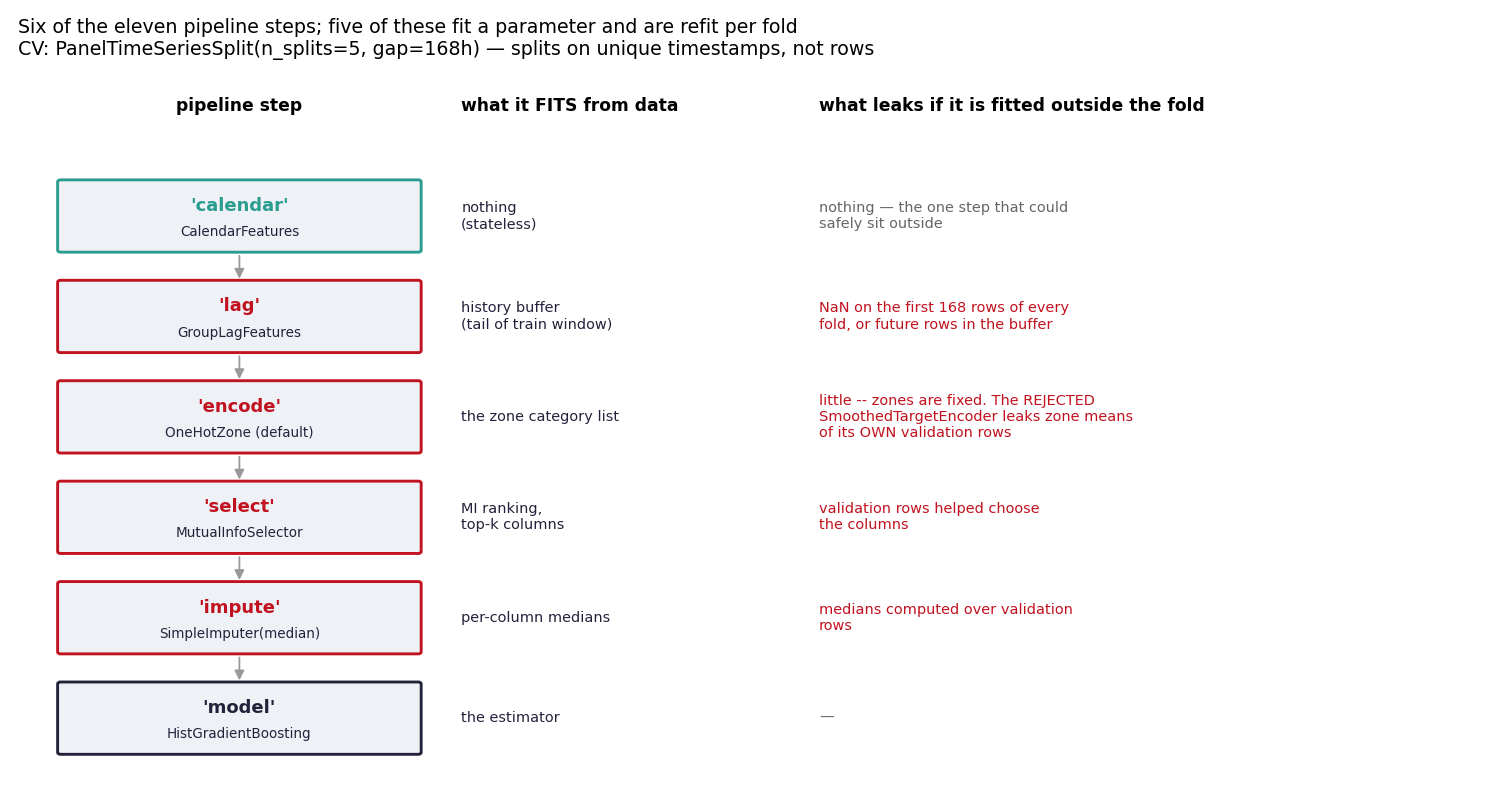

In [3]:
data_facts = pd.DataFrame([
    ("sources", "EIA-930 Hourly Electric Grid Monitor (public domain) + Open-Meteo ERA5 (CC-BY-4.0)", "nb00.source"),
    ("zones", ", ".join(s0["zones"]), "nb00.zones"),
    ("window", f"{s0['start']} -> {s0['end']} (UTC, hourly)", "nb00.start/end"),
    ("raw rows x columns", f"{s0['raw_rows']:,} x {s0['raw_columns']}", "nb00.raw_rows"),
    ("weather columns", f"{s0['weather']['n_columns']} ERA5 variables at one point per zone, {s0['temp_coverage']:.0%} coverage", "nb00.weather"),
    ("cleaning contract", f"interpolate gaps <= {s1['interp_limit_hours']} h; drop longer runs; "
                          f"{sum(s1['implausible_values_nulled'].values())} impossible values nulled; "
                          f"{s1['rows_dropped']} rows dropped -> {s1['rows_clean']:,} clean rows", "nb01.*"),
    ("target", "net_load = demand - wind - solar (identity residual %.1f MW)" % s1["max_identity_residual"], "nb01.max_identity_residual"),
    ("final features (h=1)", f"{s2['n_features']} after in-fold MI selection; encoding = {s2['encoding_chosen']}", "nb02.n_features"),
    ("feature families (h = 24 champion)", "target lags, rolling means, lagged demand / wind / solar / fuel mix ('exogenous'), calendar (cyclical), weather (+ lags), one-hot zone; notebook 02's per-zone relative lags are not in it", "nb07.permutation_by_family, notebook 02"),
    ("dev / holdout rows", f"{s4['n_dev']:,} / {s4['n_hold']:,} (cut {s4['cut']})", "nb04.n_dev/n_hold"),
], columns=["item", "value", "ledger key"])
display(data_facts.style.hide(axis="index"))

lags = pd.DataFrame({h: [", ".join(map(str, v))] for h, v in s1["lags_by_horizon"].items()}, index=["notebook 01 lag set (hours)"]).T
lags.index.name = "horizon h"
display(lags)
show("02_pipeline_map", "the feature pipeline; every red step fits a parameter and is refit per fold.")

### 8.4 — Supervised learning: the results in one table

The best model of each family — ridge, random forest, histogram gradient boosting (HGB), and quantile boosting — scored on five chronological folds (mean ± s.d. of MAE) and on the untouched final block. The baselines are holdout-only. Skill against seasonal naive is computed on rows the two forecasts share (the 46,123 common rows for the champion and both baselines). The champion's holdout MAE over all rows (2,159.6 MW) is **52.2 MW** (2.5%) above its CV score: the optimism of tuning on the folds you select on.

In [4]:
# ONE ROW SET PER SKILL SCORE. A skill divides a model's MAE by seasonal naive's MAE on the
# SAME rows. The champion and both baselines are scored on the rows every benchmark can
# reach (nb04.holdout_mae_common_rows, nb04.baselines). The ledger holds no common-row MAE
# for ridge and the forest, so each is scored on the rows notebook 04 paired it with
# seasonal naive (nb04.model_comparison.pairs). `holdout_rows` says which.
_pairs = {(p["a"], p["b"]): p for p in s4["model_comparison"]["pairs"]}
_naive_common = s4["baselines"]["naive168_mae"]
_common = f"{s4['baselines']['n_scored']:,} common rows"
rows = []
for key, rung in s4["ladder"].items():
    name = key[3:].strip()
    if name in ("ridge", "random forest"):
        _p = _pairs[(name, "seasonal naive")]
        hold, naive, scored = _p["mae_a"], _p["mae_b"], "rows shared with seasonal naive"
    elif name == "seasonal naive":
        hold, naive, scored = _naive_common, _naive_common, _common
    elif name == "EIA DF composite":
        hold, naive, scored = s4["baselines"]["df_composite_mae"], _naive_common, _common
    else:                                   # untuned HGB and the quantile model: CV only
        hold, naive, scored = None, np.nan, "-"
    rows.append(dict(family=name, cv_mae_mean=rung["cv_mae_mean"], cv_mae_sd=rung["cv_mae_sd"],
                     holdout_mae=hold, fit_seconds=rung["seconds"], holdout_rows=scored,
                     naive_same_rows=naive))
rows.append(dict(family="tuned HGB (champion)", cv_mae_mean=s4["cv_mae"], cv_mae_sd=np.nan,
                 holdout_mae=s4["holdout_mae_common_rows"], fit_seconds=np.nan, holdout_rows=_common,
                 naive_same_rows=_naive_common))
fam = pd.DataFrame(rows)
fam["mechanism"] = fam.family.map({
    "seasonal naive": "baseline: value at t-168", "EIA DF composite": "baseline: EIA demand forecast - lagged renewables",
    "ridge": "linear, L2-regularised", "random forest": "bagged deep trees (variance reduction)",
    "hist gradient boosting": "boosted shallow trees (bias reduction)", "quantile GBM (median)": "boosting on pinball loss",
    "tuned HGB (champion)": "HGB after two-stage search over the whole pipeline"})
fam["skill_vs_naive"] = 1 - fam.holdout_mae / fam.naive_same_rows
fam = fam.drop(columns="naive_same_rows")
display(fam[["family", "mechanism", "cv_mae_mean", "cv_mae_sd", "holdout_mae", "holdout_rows", "skill_vs_naive",
             "fit_seconds"]]
        .style.hide(axis="index").format({"cv_mae_mean": "{:,.1f}", "cv_mae_sd": "{:,.1f}", "holdout_mae": "{:,.1f}",
                                          "skill_vs_naive": "{:.1%}", "fit_seconds": "{:,.1f}"}, na_rep="-"))

family,mechanism,cv_mae_mean,cv_mae_sd,holdout_mae,holdout_rows,skill_vs_naive,fit_seconds
seasonal naive,baseline: value at t-168,-,-,"4,259.8","46,123 common rows",0.0%,0.0
EIA DF composite,baseline: EIA demand forecast - lagged renewables,-,-,"3,059.2","46,123 common rows",28.2%,0.0
ridge,"linear, L2-regularised","2,697.9",120.4,"2,730.7",rows shared with seasonal naive,36.0%,6.3
random forest,bagged deep trees (variance reduction),"2,237.1",73.7,"2,299.3",rows shared with seasonal naive,46.1%,249.7
hist gradient boosting,boosted shallow trees (bias reduction),"2,173.2",85.5,-,-,-,14.5
quantile GBM (median),boosting on pinball loss,"2,237.2",94.3,-,-,-,16.0
tuned HGB (champion),HGB after two-stage search over the whole pipeline,"2,107.3",-,"2,139.7","46,123 common rows",49.8%,-


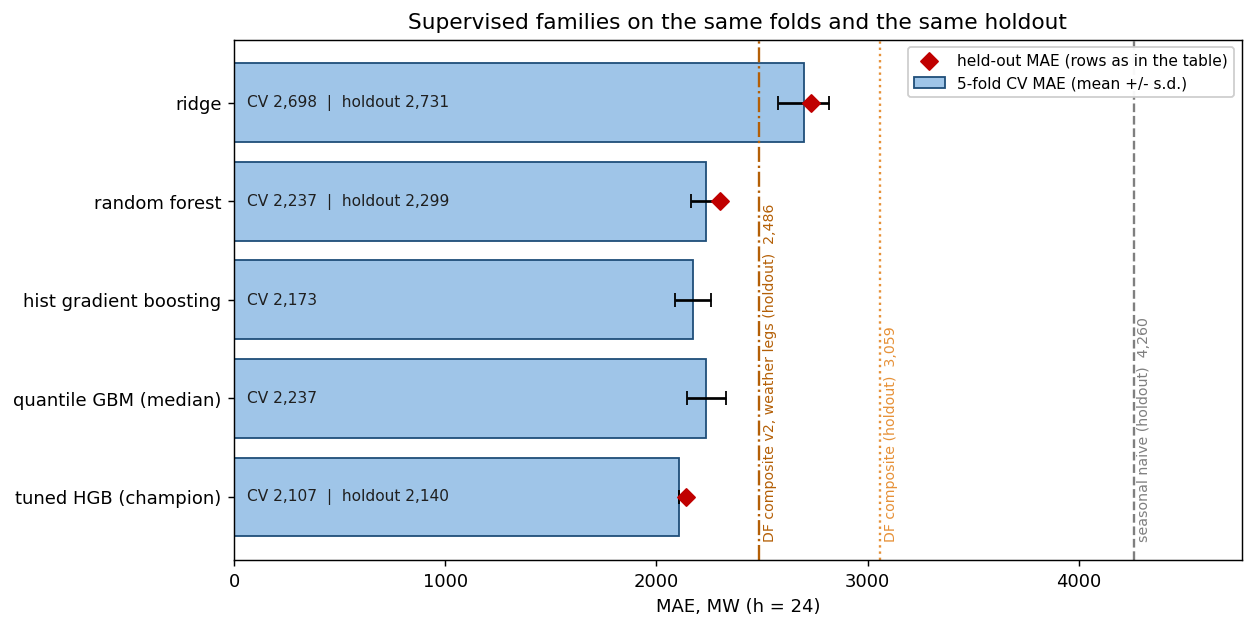

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.2))
cv = fam.dropna(subset=["cv_mae_mean"]).copy()
cv["label"] = cv.family
y = np.arange(len(cv))
ax.barh(y, cv.cv_mae_mean, xerr=cv.cv_mae_sd.fillna(0), color="#9fc5e8", edgecolor="#1f4e79", capsize=4,
        label="5-fold CV MAE (mean +/- s.d.)")
h = cv.holdout_mae.notna()
ax.scatter(cv.holdout_mae[h], y[h], marker="D", color="#c00000", zorder=3, s=45, label="held-out MAE (rows as in the table)")
for yy, v, hv in zip(y, cv.cv_mae_mean, cv.holdout_mae):
    lab = f"CV {v:,.0f}" + (f"  |  holdout {hv:,.0f}" if pd.notna(hv) else "")
    ax.text(60, yy, lab, va="center", ha="left", fontsize=8.5, color="#1f1f1f")
for val, lab, col, ls in [(s4["baselines"]["naive168_mae"], "seasonal naive (holdout)", "#7f7f7f", "--"),
                          (s4["baselines"]["df_composite_mae"], "DF composite (holdout)", "#e69138", ":"),
                          (s4["baselines_v2"]["df_composite_v2_mae"], "DF composite v2, weather legs (holdout)", "#b45f06", "-.")]:
    ax.axvline(val, color=col, ls=ls, lw=1.3)
    ax.text(val + 18, len(cv) - 0.55, f"{lab}  {val:,.0f}", rotation=90, va="bottom", ha="left", fontsize=7.8, color=col)
ax.set_yticks(y); ax.set_yticklabels(cv.label); ax.invert_yaxis()
ax.set_xlabel("MAE, MW (h = 24)"); ax.set_xlim(0, s4["baselines"]["naive168_mae"] * 1.12)
ax.set_title("Supervised families on the same folds and the same holdout")
ax.legend(loc="upper right", fontsize=8.5, framealpha=0.95)
fig.savefig(cfg.FIGURES / "08_supervised_summary.png", bbox_inches="tight")
plt.show()

**Figure: `08_supervised_summary.png`.** CV MAE falls from ridge (**2,697.9 ± 120.4**) to random forest (**2,237.1 ± 73.7**) to HGB (**2,173.2 ± 85.5**); the quantile model on the median scores **2,237.2 ± 94.3**, about 64 MW worse. Tuning takes HGB to **2,107.3** in CV; on the holdout the champion scores **2,139.7** on the 46,123 common rows (**2,159.6** on all 47,299). Every family beats seasonal naive (**4,259.8**) and the EIA composite (**3,059.2**), and the champion beats composite v2 (**2,485.9**) by **13.9%**.

The two ensembles are 64 MW apart in CV, inside one fold s.d., so the CV table alone cannot rank them; 8.4b does it with paired tests. I quote **13.9%** against composite v2 as the honest skill and 49.8% against seasonal naive as the floor.

### 8.4b — Is the ranking real? Paired tests on the same holdout rows

For every pair of models: a Diebold–Mariano test and a Wilcoxon signed-rank test on zone-day blocks (hours are serially correlated), Benjamini–Hochberg correction, and a block-bootstrap interval on the MAE difference. `diff_mw` is (a − b), so negative means `a` is better; `survives_bh` means the adjusted p-value is below 0.05.

a,b,mae_a,mae_b,diff_mw,diff_lo,diff_hi,dm,dm_p_adj,wilcoxon_p_adj,survives_bh
tuned HGB,ridge,"2,160","2,743",-583,-634,-532,-20.5,1.3e-92,3.5e-124,True
tuned HGB,random forest,"2,160","2,298",-138,-179,-95,-6.1,1.2e-09,6.2e-22,True
tuned HGB,seasonal naive,"2,161","4,265","-2,103","-2,258","-1,958",-22.9,2.2e-114,1.0e-196,True
tuned HGB,EIA DF composite,"2,139","3,062",-923,"-1,009",-839,-17.9,8.2e-71,1.1e-90,True
ridge,random forest,"2,743","2,298",445,392,498,14.7,1.0e-48,1.1e-78,True
ridge,seasonal naive,"2,731","4,265","-1,534","-1,691","-1,393",-16.7,2.5e-62,2.4e-76,True
ridge,EIA DF composite,"2,718","3,062",-344,-438,-257,-6.5,7.0e-11,1.3e-07,True
random forest,seasonal naive,"2,299","4,265","-1,966","-2,116","-1,828",-22.4,6.9e-110,4.6e-180,True
random forest,EIA DF composite,"2,290","3,062",-772,-852,-689,-16.4,3.5e-60,8.5e-74,True
seasonal naive,EIA DF composite,"4,260","3,059","1,201","1,033","1,356",12.8,1.7e-37,1.3e-51,True


blocks: 1,974 zone-days; tests: 10; correction: benjamini-hochberg


**Figure `04_model_comparison.png`** — held-out MAE per model with block-bootstrap intervals on the differences.

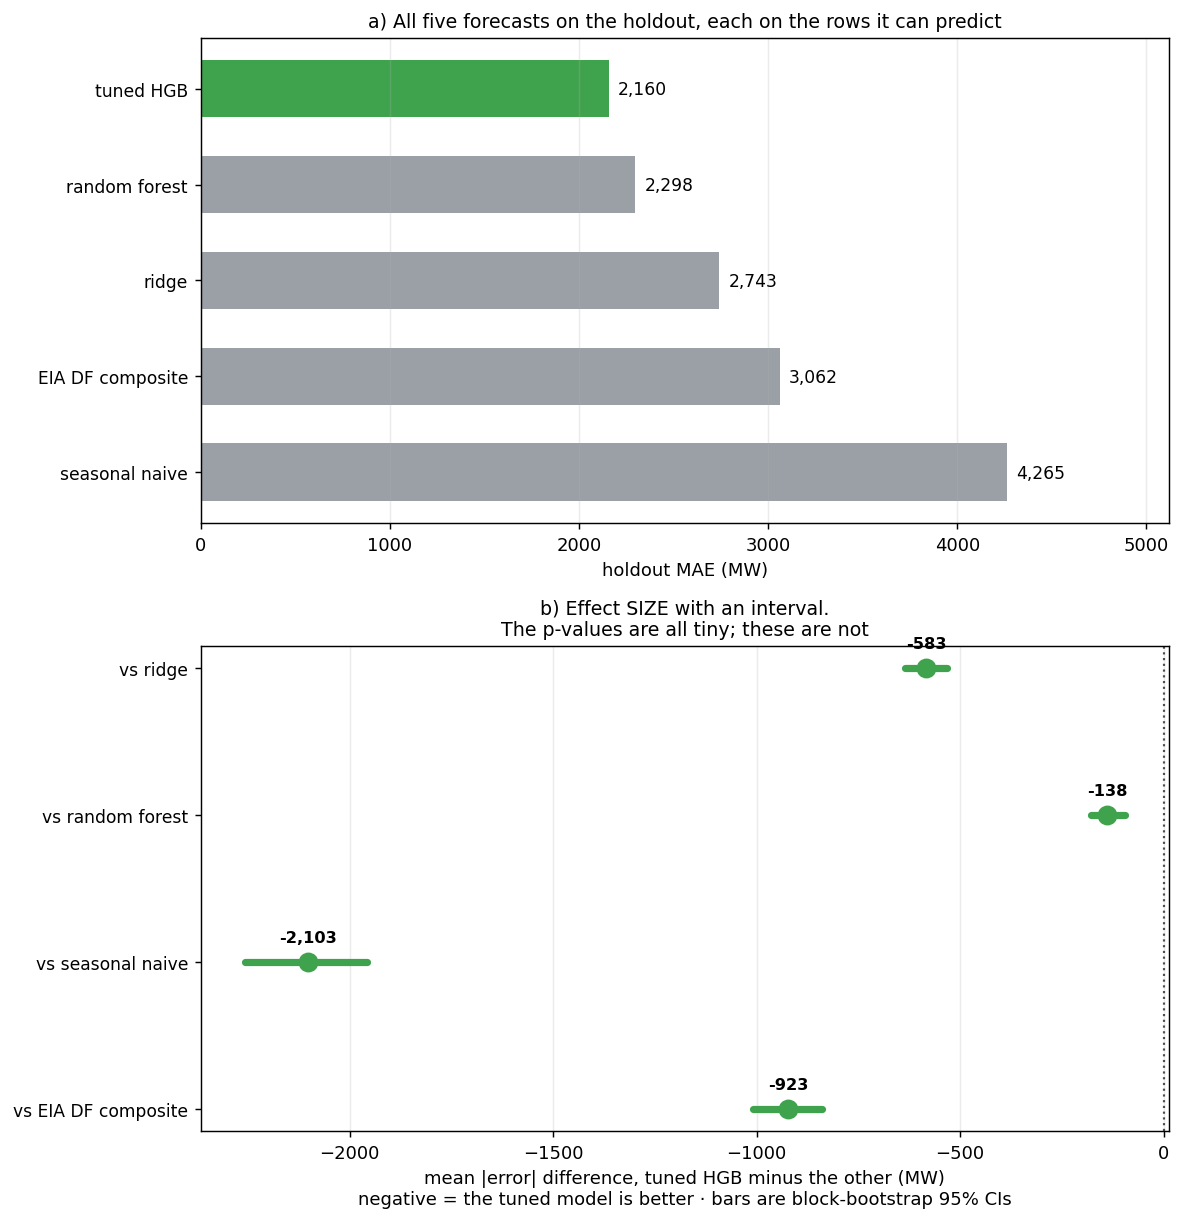

In [6]:
pairs = pd.DataFrame(s4["model_comparison"]["pairs"])
pairs = pairs[["a", "b", "mae_a", "mae_b", "diff_mw", "diff_lo", "diff_hi", "dm", "dm_p_adj", "wilcoxon_p_adj", "survives_bh"]]
display(pairs.style.hide(axis="index").format({"mae_a": "{:,.0f}", "mae_b": "{:,.0f}", "diff_mw": "{:,.0f}",
        "diff_lo": "{:,.0f}", "diff_hi": "{:,.0f}", "dm": "{:.1f}", "dm_p_adj": "{:.1e}", "wilcoxon_p_adj": "{:.1e}"}))
print(f"blocks: {s4['model_comparison']['n_blocks']:,} zone-days; tests: {s4['model_comparison']['n_tests']}; "
      f"correction: {s4['model_comparison']['correction']}")
show("04_model_comparison", "held-out MAE per model with block-bootstrap intervals on the differences.")

### 8.4b (continued) — The strengthened benchmark, paired

The same paired test against EIA composite v2, pooled and by region, on the 46,123 common day-ahead rows, with notebook 04's settings (600 block-bootstrap draws, Diebold–Mariano at h = 24, blocked Wilcoxon). `diff_mw` is champion minus v2; a regional interval that contains zero is a tie at this sample size.

In [7]:
# WHAT: champion against the EIA composite v2 at h = 24, paired, pooled and per zone.
# WHY:  G2' is judged against v2, and notebook 04's ten-pair family predates v2.
# NOTE: same functions and settings as notebook 04's paired tests (600 draws, zone x
#       UTC-date blocks, DM at h = 24); the rows are the guard frame that reproduces
#       notebook 04's per-horizon MAEs exactly.
from src import evaluation as E
from src import reserve as RS

_frames, _guard = RS.build_scored_frames(pd.read_parquet(cfg.PANEL), s4["cut"], preds)
RS.check_against_ledger(_guard, s4["per_horizon_skill"])
g24 = _guard["24"]


def _paired_v2(frame):
    em = (frame[cfg.TARGET] - frame["y_pred"]).to_numpy()
    ev = (frame[cfg.TARGET] - frame["v2"]).to_numpy()
    blocks = (frame[cfg.GROUP_COL].astype(str) + "|"
              + pd.to_datetime(frame[cfg.TIME_COL]).dt.date.astype(str)).to_numpy()
    eff = E.bootstrap_ci(np.abs(em) - np.abs(ev), n_boot=600, blocks=blocks)
    out = {"rows": int(len(frame)), "n_blocks": int(len(pd.unique(blocks))),
           "mae_model": float(np.abs(em).mean()), "mae_v2": float(np.abs(ev).mean()),
           "diff_mw": float(eff["estimate"]), "diff_lo": float(eff["lo"]),
           "diff_hi": float(eff["hi"])}
    out["interval_excludes_zero"] = bool(out["diff_hi"] < 0 or out["diff_lo"] > 0)
    return out, em, ev, blocks


v2_pooled, _em, _ev, _bl = _paired_v2(g24)
_dm = E.diebold_mariano(_em, _ev, horizon=24, groups=g24[cfg.GROUP_COL].to_numpy(),
                        times=g24[cfg.TIME_COL].to_numpy())
_wx = E.blocked_wilcoxon(_em, _ev, _bl)
v2_pooled.update(dm=float(_dm["dm"]), dm_p=float(_dm["p"]), wilcoxon_p=float(_wx["p"]))
v2_by_zone = {z: _paired_v2(gz)[0] for z, gz in g24.groupby(cfg.GROUP_COL)}

display(pd.DataFrame({"all regions": v2_pooled, **v2_by_zone}).T[
    ["rows", "mae_model", "mae_v2", "diff_mw", "diff_lo", "diff_hi", "interval_excludes_zero"]])
print(f"pooled: champion minus v2 {v2_pooled['diff_mw']:+,.0f} MW "
      f"[{v2_pooled['diff_lo']:+,.0f}, {v2_pooled['diff_hi']:+,.0f}] over "
      f"{v2_pooled['n_blocks']:,} zone-days; DM {v2_pooled['dm']:.1f} "
      f"(p = {v2_pooled['dm_p']:.1e}), blocked Wilcoxon p = {v2_pooled['wilcoxon_p']:.1e}")
_ties = [z for z, v in v2_by_zone.items() if not v["interval_excludes_zero"]]
print(f"regions whose interval contains zero: {_ties if _ties else 'none'}")
R.save("nb08", {"paired_vs_composite_v2": {"pooled": v2_pooled, "by_zone": v2_by_zone}});

,rows,mae_model,mae_v2,diff_mw,diff_lo,diff_hi,interval_excludes_zero
all regions,46123,"2,139.729","2,485.944",-346.215,-401.611,-290.215,True
BPAT,7713,586.307,656.581,-70.274,-96.903,-45.148,True
CISO,7655,"1,454.440","2,121.499",-667.059,-763.090,-569.335,True
ERCO,7728,"3,777.032","4,289.862",-512.830,-660.209,-358.066,True
MISO,7656,"3,379.459","3,980.724",-601.265,-849.296,-374.585,True
NYIS,7715,709.748,641.081,68.667,-60.663,164.498,False
SWPP,7656,"2,938.484","3,236.741",-298.258,-423.768,-171.644,True


pooled: champion minus v2 -346 MW [-402, -290] over 1,929 zone-days; DM -9.6 (p = 6.7e-22), blocked Wilcoxon p = 2.4e-31
regions whose interval contains zero: ['NYIS']
[results read-only] nb08: 1 key(s) verified against the ledger, nothing written


### 8.4c — Horizons: how the skill decays

Held-out MAE at h = 1, 24, 48 and 72, each with its own re-tuned champion, against seasonal naive and the weather-driven composite. The external benchmark is a day-ahead forecast, so the comparison is fair only at h = 24 (the `fair` column). The largest step is h = 1 to h = 24 (**1,594 MW** on the common rows), the cost of losing the most recent lags.

,model_mae,naive_mae,composite_v2_mae,skill_vs_naive,skill_vs_v2,fair,n
horizon,,,,,,,
1,546,"4,260","2,486",87.2%,78.0%,False,46123
24,"2,140","4,260","2,486",49.8%,13.9%,True,46123
48,"2,371","4,257","2,530",44.3%,6.3%,False,46052
72,"2,458","4,262","2,551",42.3%,3.7%,False,46051


**Figure `04_skill_by_horizon.png`** — skill per horizon against a benchmark rebuilt for that horizon; the fairness caveat is printed on the figure.

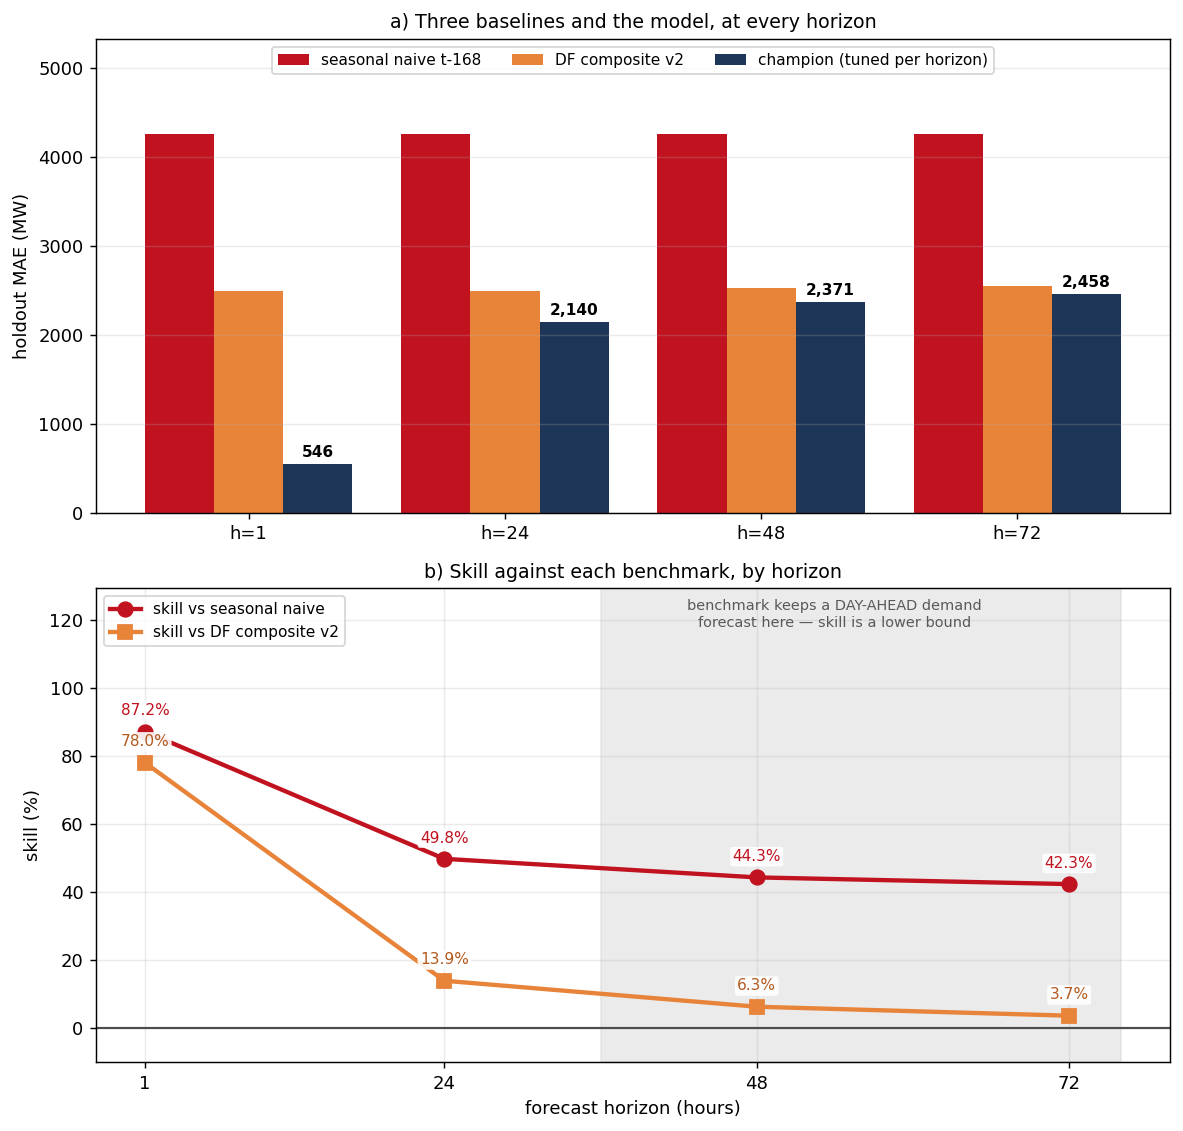

In [8]:
ph = pd.DataFrame(s4["per_horizon_skill"]).T
ph.index.name = "horizon"
ph = ph[["model_mae", "naive_mae", "composite_v2_mae", "skill_vs_naive", "skill_vs_v2", "fair", "n"]].astype(
    {"model_mae": float, "naive_mae": float, "composite_v2_mae": float, "skill_vs_naive": float, "skill_vs_v2": float})
display(ph.style.format({"model_mae": "{:,.0f}", "naive_mae": "{:,.0f}", "composite_v2_mae": "{:,.0f}",
                         "skill_vs_naive": "{:.1%}", "skill_vs_v2": "{:.1%}"}))
show("04_skill_by_horizon", "skill per horizon against a benchmark rebuilt for that horizon; the fairness caveat is printed on the figure.")

### 8.4d — Hyperparameter search and sensitivity

A two-stage search: **40** random draws over the whole pipeline (including `lag__lags` and `select__k`), then a **9**-cell grid over `learning_rate` and `max_iter`, two of the four axes whose span exceeds the **50.7 MW** fold noise floor. `range_mw` is each axis's CV-MAE span; below the noise floor an axis is flat. Two axes hit their upper boundary, so the optimum is censored there (`nb04.search`).

,best,range_mw,n_values,seconds,matters
select__k,all,823.3,6,151,True
model__max_iter,1200,236.8,6,172,True
model__max_depth,8,63.7,6,184,True
model__learning_rate,0.04,59.8,7,224,True
model__min_samples_leaf,10,22.7,6,200,False
model__l2_regularization,1.0,5.2,6,205,False


fold noise floor      50.7 MW
random stage          40 draws -> CV MAE 2,111.4
refining grid         9 cells over ['model__learning_rate', 'model__max_iter'] -> 2,107.3  (gain 4.1 MW; full grid avoided: 72,000 cells)
boundary hits         {'model__max_iter': 'high', 'model__min_samples_leaf': 'high'}
best params           {"lag__lags": [24, 25, 26, 48, 168], "lag__roll_windows": [24], "model__l2_regularization": 0.0, "model__learning_rate": 0.04, "model__max_depth": 8, "model__max_iter": 1200, "model__min_samples_leaf": 100, "select__k": "all"}


**Figure `04_hyperparam_sensitivity.png`** — one-at-a-time sweeps per axis against the fold noise floor.

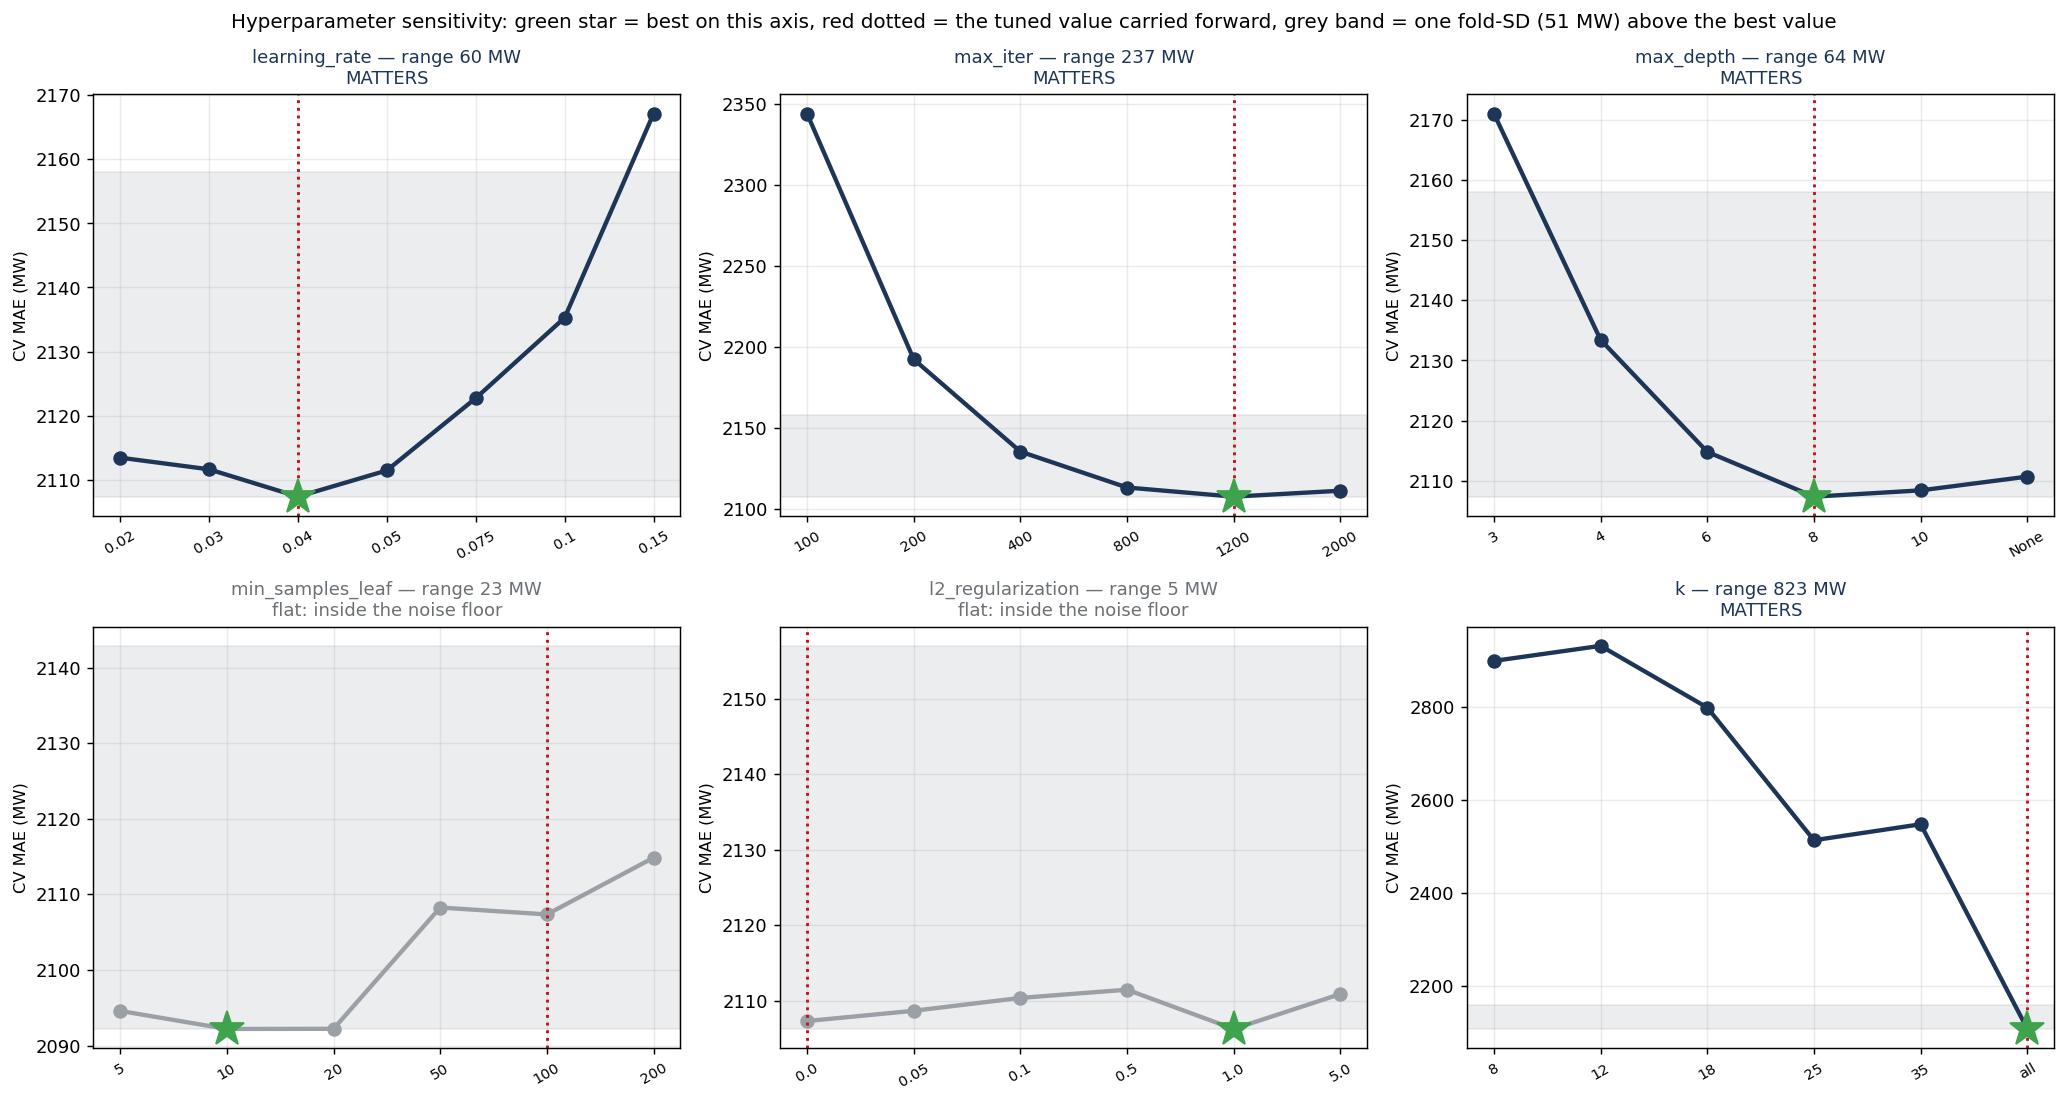

In [9]:
sens = pd.DataFrame({ax: dict(best=v["best_value"], range_mw=v["range_mw"], n_values=len(v["values"]),
                              seconds=v["seconds"]) for ax, v in s4["hyperparam_sensitivity"]["axes"].items()}).T
sens["range_mw"] = sens.range_mw.astype(float)
sens["matters"] = sens.range_mw > s4["hyperparam_sensitivity"]["fold_noise_floor_mw"]
sens = sens.sort_values("range_mw", ascending=False)
display(sens.style.format({"range_mw": "{:,.1f}", "seconds": "{:,.0f}"}))
print(f"fold noise floor      {s4['hyperparam_sensitivity']['fold_noise_floor_mw']:.1f} MW")
print(f"random stage          {s4['search']['n_iter_random']} draws -> CV MAE {s4['search']['random_cv_mae']:,.1f}")
print(f"refining grid         {s4['search']['grid_cells']} cells over {s4['search']['refined_axes']} -> "
      f"{s4['search']['refined_cv_mae']:,.1f}  (gain {-s4['search']['refinement_gain_mw']:.1f} MW; "
      f"full grid avoided: {s4['search']['full_grid_cells_avoided']:,} cells)")
print(f"boundary hits         {s4['search']['boundary_hits']}")
print("best params           " + json.dumps(s4["search"]["best_params"]))
show("04_hyperparam_sensitivity", "one-at-a-time sweeps per axis against the fold noise floor.")

### 8.4e — Feature importance: ablation and permutation disagree, and both are right

*Ablation* (notebook 04) drops a feature family and **refits**; *permutation* (notebook 07) shuffles a family under the **fitted** model on held-out data. Ablation measures what nothing else can replace; permutation measures what this model leans on. The figure uses a log axis because they differ by up to three orders of magnitude.

,ablation_delta_mw (refit),ablation_pct_of_full,"permutation_mw (fitted, holdout)",permutation_share_h24
weather,698.1,33.1%,"1,433",7.4%
calendar,149.8,7.1%,400,2.1%
lag,66.0,3.1%,"11,416",59.3%
zone,16.3,0.8%,"1,111",5.8%
exogenous,2.8,0.1%,"4,500",23.4%
rolling,-4.0,-0.2%,394,2.0%


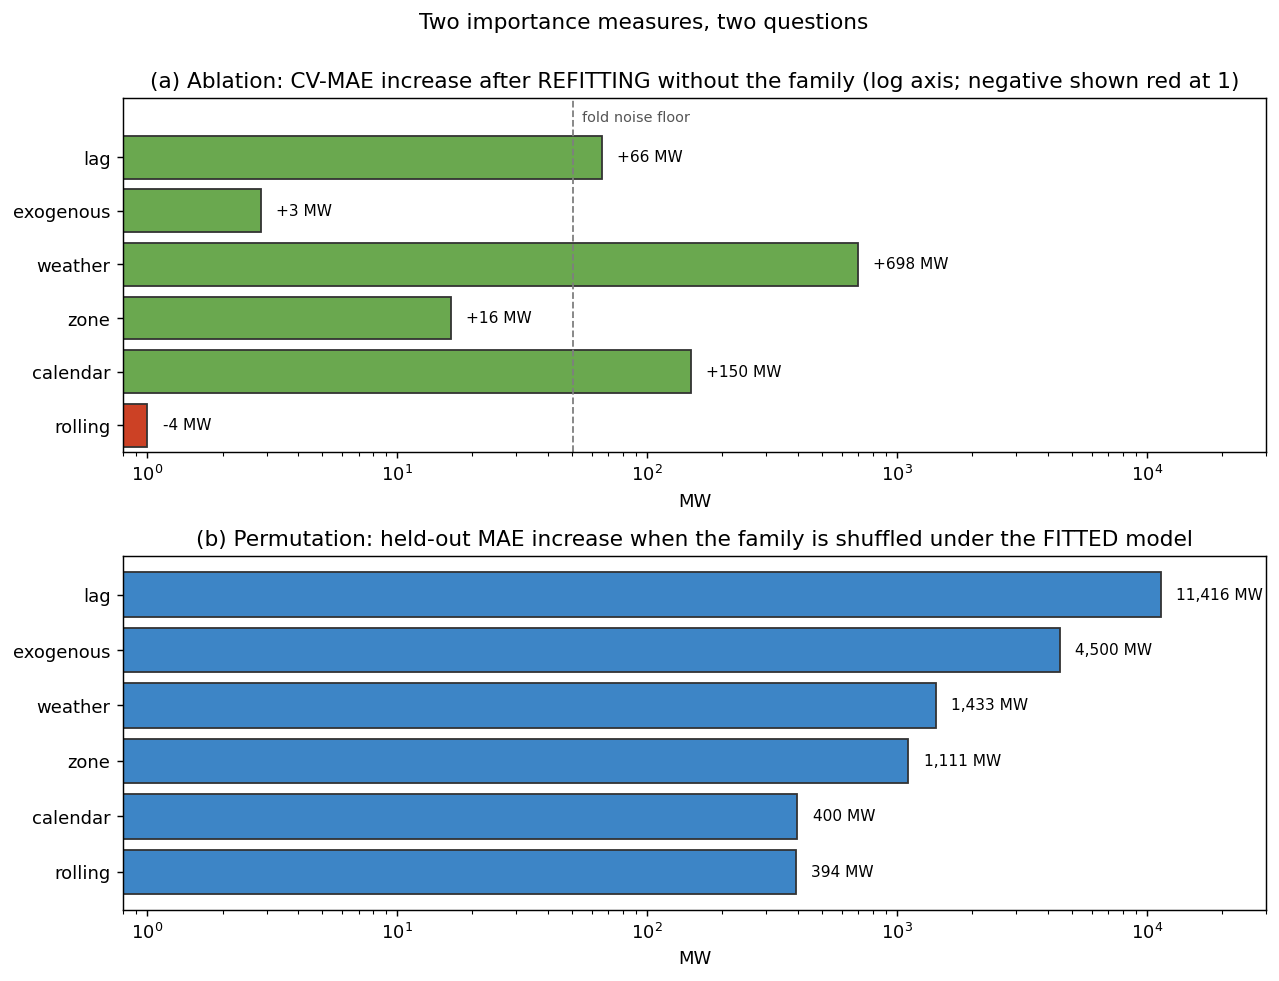

**Figure `04_ablation.png`** — ablation by family with the noise floor.

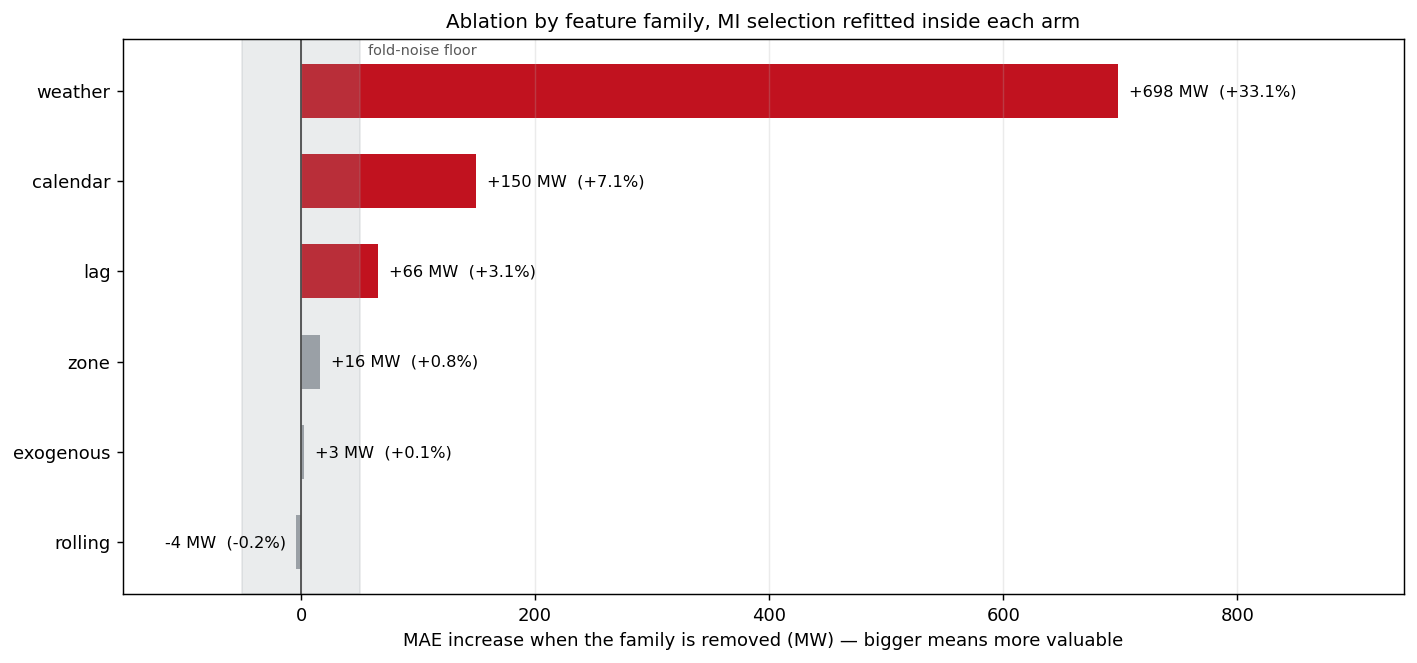

In [10]:
fams = ["weather", "calendar", "lag", "zone", "exogenous", "rolling"]
imp = pd.DataFrame({
    "ablation_delta_mw (refit)": {f: s4["ablation"]["families"][f]["delta_mw"] for f in fams},
    "ablation_pct_of_full": {f: s4["ablation"]["families"][f]["pct_of_full"] for f in fams},
    "permutation_mw (fitted, holdout)": {f: s7["permutation_by_family"][f] for f in fams},
    "permutation_share_h24": {f: s7["importance_by_horizon"]["share"]["24"][f] for f in fams},
})
display(imp.style.format({"ablation_delta_mw (refit)": "{:,.1f}", "ablation_pct_of_full": "{:.1f}%",
                          "permutation_mw (fitted, holdout)": "{:,.0f}", "permutation_share_h24": "{:.1%}"}))

fig, axs = plt.subplots(2, 1, figsize=(10, 7.5), sharex=False)
order = imp["permutation_mw (fitted, holdout)"].sort_values(ascending=False).index
y = np.arange(len(order))
a = imp.loc[order, "ablation_delta_mw (refit)"]
axs[0].barh(y, a.clip(lower=1), color=["#6aa84f" if v > 0 else "#cc4125" for v in a], edgecolor="#333")
for yy, v in zip(y, a):
    axs[0].text(max(v, 1) * 1.15, yy, f"{v:+,.0f} MW", va="center", fontsize=8.5)
axs[0].set_yticks(y); axs[0].set_yticklabels(order); axs[0].invert_yaxis(); axs[0].set_xscale("log")
axs[0].axvline(s4["hyperparam_sensitivity"]["fold_noise_floor_mw"], color="#7f7f7f", ls="--", lw=1)
axs[0].set_ylim(len(order) - 0.5, -1.1)
axs[0].text(s4["hyperparam_sensitivity"]["fold_noise_floor_mw"] * 1.08, -0.75, "fold noise floor", fontsize=8, color="#555", va="center")
axs[0].set_title("(a) Ablation: CV-MAE increase after REFITTING without the family (log axis; negative shown red at 1)")
axs[0].set_xlabel("MW"); axs[0].set_xlim(0.8, 3e4)
p = imp.loc[order, "permutation_mw (fitted, holdout)"]
axs[1].barh(y, p, color="#3d85c6", edgecolor="#333")
for yy, v in zip(y, p):
    axs[1].text(v * 1.15, yy, f"{v:,.0f} MW", va="center", fontsize=8.5)
axs[1].set_yticks(y); axs[1].set_yticklabels(order); axs[1].invert_yaxis(); axs[1].set_xscale("log")
axs[1].set_title("(b) Permutation: held-out MAE increase when the family is shuffled under the FITTED model")
axs[1].set_xlabel("MW"); axs[1].set_xlim(0.8, 3e4)
fig.suptitle("Two importance measures, two questions", y=1.0)
fig.tight_layout()
fig.savefig(cfg.FIGURES / "08_ablation_vs_permutation.png", bbox_inches="tight")
plt.show()
show("04_ablation", "ablation by family with the noise floor.")

**Figure: `08_ablation_vs_permutation.png`.** Ablation ranks **weather** first (**+698.1 MW**, 33.1% of the full-model error), then calendar (+149.8) and lag (+66.0); rolling means are inside noise (-4.0 MW). Permutation ranks **lag** first (**11,416 MW**), then exogenous (4,500), weather (1,433) and zone (1,111). The model is persistence with corrections — it leans on `net_load_lag24` — but without the lags it rebuilds most of that from the rolling means and `demand_lag24`, so the irreplaceable content is mostly weather. Weather's permutation share rises from **0.9%** at h = 1 to **10.3%** at h = 72 as the usable lags get older.

### 8.4f — Learning curve: does more data help?

The champion refit on the most recent 10% to 100% of the development block, scored on the same validation window. The last step is **3.7 MW**, inside the **50.7 MW** noise floor, so the curve is flat (`still_falling = False`).

fraction,n_rows,train_start,train_mae,valid_mae
0.100000,"22,800",2022-11-26 03:00:00,709,"3,857"
0.200000,"45,594",2022-06-20 20:00:00,957,"2,328"
0.350000,"79,788",2021-10-26 07:00:00,"1,143","2,220"
0.500000,"113,982",2021-03-02 16:00:00,"1,259","2,182"
0.750000,"170,971",2020-01-31 21:00:00,"1,356","2,106"
1.000000,"227,962",2019-01-01 00:00:00,"1,414","2,102"


**Figure `04_learning_curve.png`** — training and validation MAE against the number of training rows.

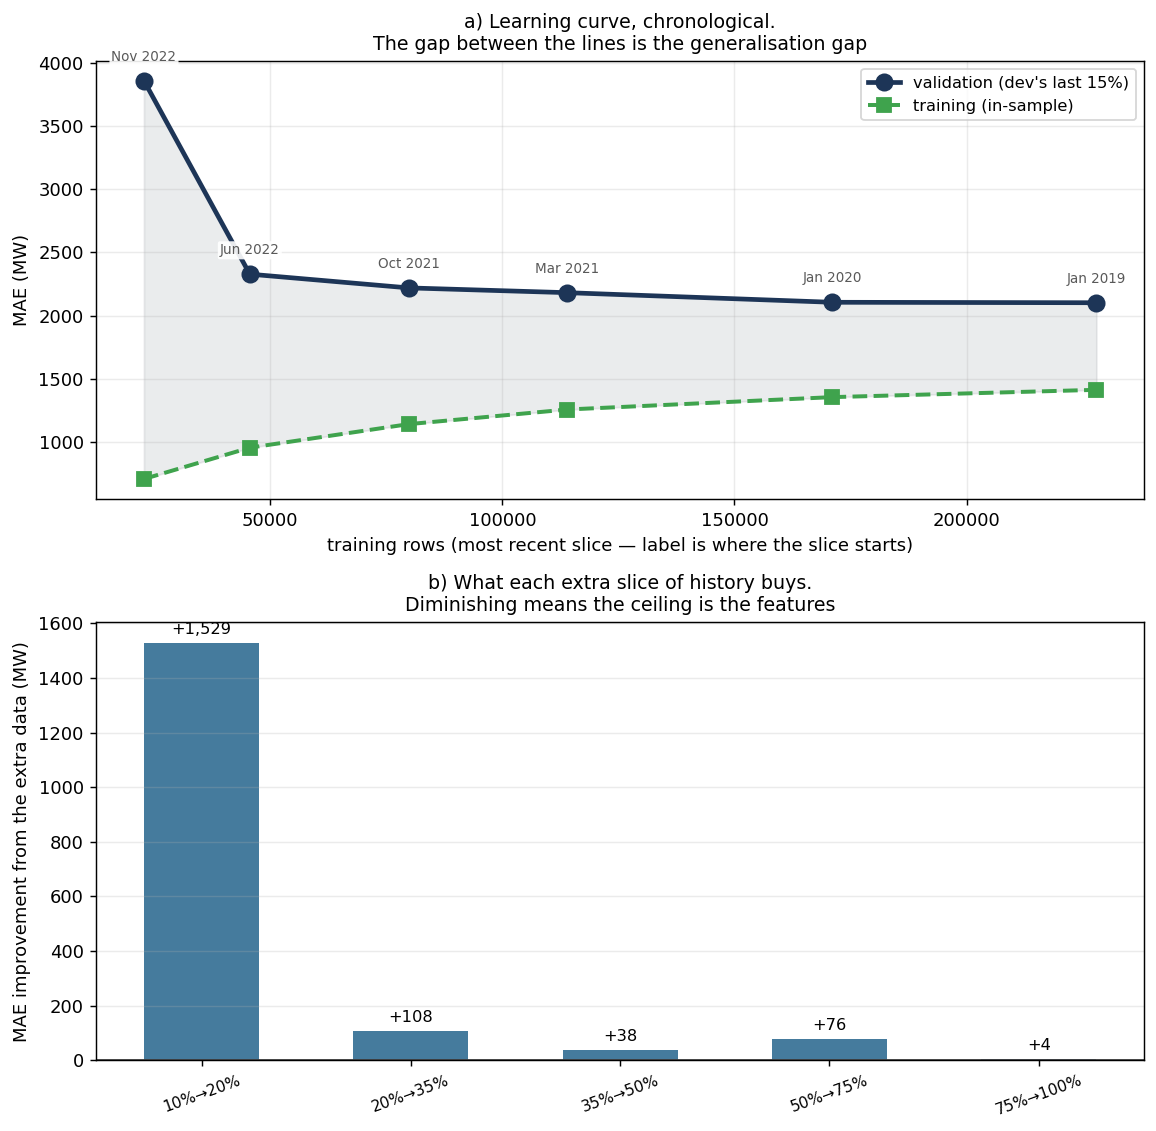

In [11]:
lcr = pd.DataFrame(s4["learning_curve"]["rows"])[["fraction", "n_rows", "train_start", "train_mae", "valid_mae"]]
display(lcr.style.hide(axis="index").format({"n_rows": "{:,.0f}", "train_mae": "{:,.0f}", "valid_mae": "{:,.0f}"}))
show("04_learning_curve", "training and validation MAE against the number of training rows.")

### 8.4g — The classification arm: precision against recall

A second task on the same pipeline: will the next hour be a curtailment-risk hour (renewable share above the zone's 85th percentile and net load below its 15th)? Thresholds are chosen on the development block only. With a **15.9%** positive rate, accuracy at 0.5 is inflated; PR-AUC against the base rate is the honest lift.

,value
label_rule,renewable_share > zone p85 AND net_load < zone...
base_rate_dev,0.103
base_rate_holdout,0.159
n_positive_holdout,7499
accuracy_at_0.5,0.905
roc_auc,0.936
pr_auc,0.772
pr_auc_lift_over_base,4.868
f1_at_0.5,0.628
best_f1,0.674


**Figure `04_classification.png`** — ROC and precision-recall curves for the curtailment-risk classifier.

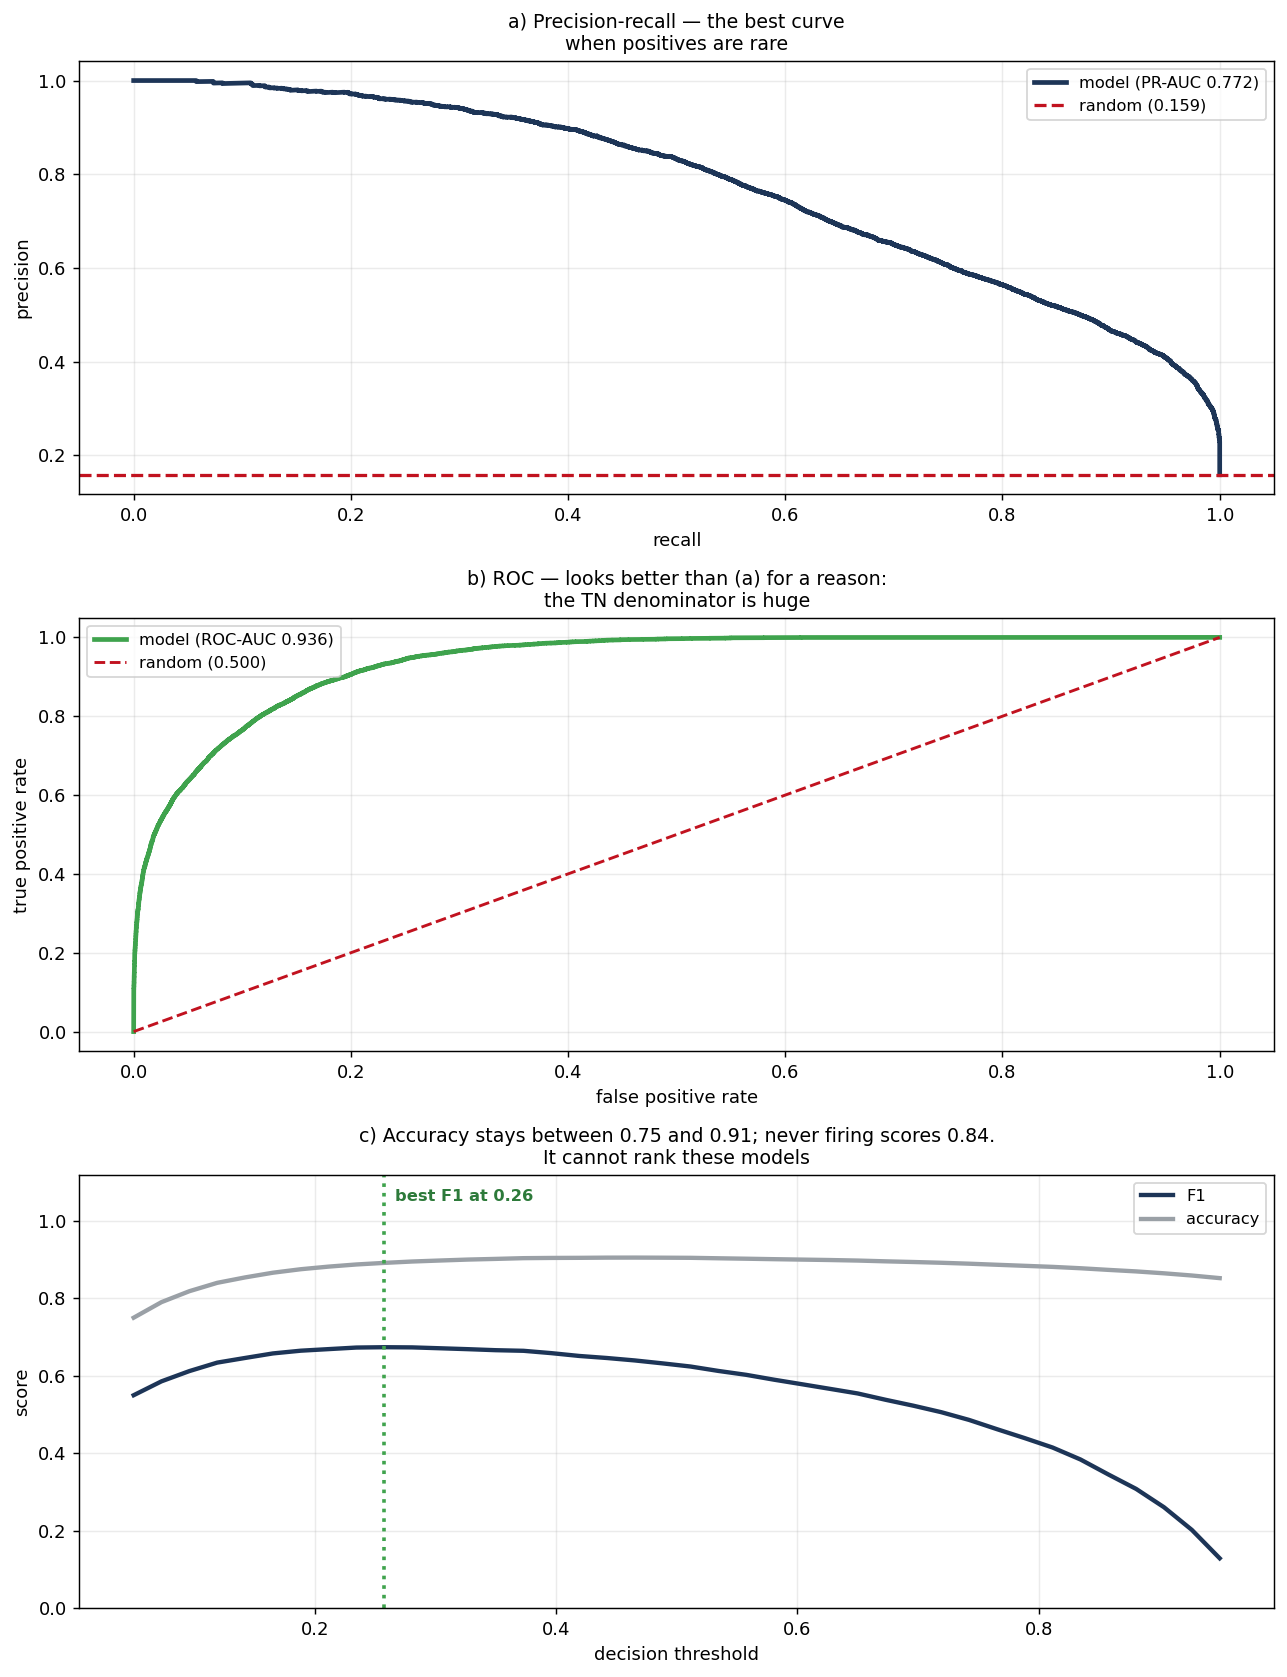

In [12]:
c = s4["classification"]
display(pd.Series({k: c[k] for k in ["label_rule", "base_rate_dev", "base_rate_holdout", "n_positive_holdout",
                                     "accuracy_at_0.5", "roc_auc", "pr_auc", "pr_auc_lift_over_base",
                                     "f1_at_0.5", "best_f1", "best_f1_threshold", "thresholds_from"]}).to_frame("value"))
show("04_classification", "ROC and precision-recall curves for the curtailment-risk classifier.")

### 8.4h — Failure analysis: three records, three categories

Three failures of the champion at h = 24, each from a different category. Panel (a) is a real held-out week; (b) and (c) are the profiles behind the other two cases.

| # | Record(s) | What happened | Category |
|---|---|---|---|
| 1 | **MISO, 2–3 July 2024** | a miss of **57,477 MW** at the worst hour (forecast 28,706, actual 86,183 MW); the **233** rows whose lags fall in a panel gap have MAE **7,562 MW** vs **2,133** on clean rows | **Operational** — the outage is dropped, then the lags read imputed history |
| 2 | **Every zone, local hour 16:00** | MAE peaks at **2,479 MW** (1.15× the holdout mean), the hour *before* the 17–21 ramp the project predicted; the hottest temperature quintile is worst (**2,617 MW** vs 1,787) | **Systematic** — a within-day error pattern the loss does not see |
| 3 | **SWPP** (error **14.6%** of mean load) and **winter** (rolling origin 2024-01-01: **2,401 MW**) | the largest wind share, and January, which the holdout does not contain | **Edge case / representation** — one weather point per zone misses a wind corridor |

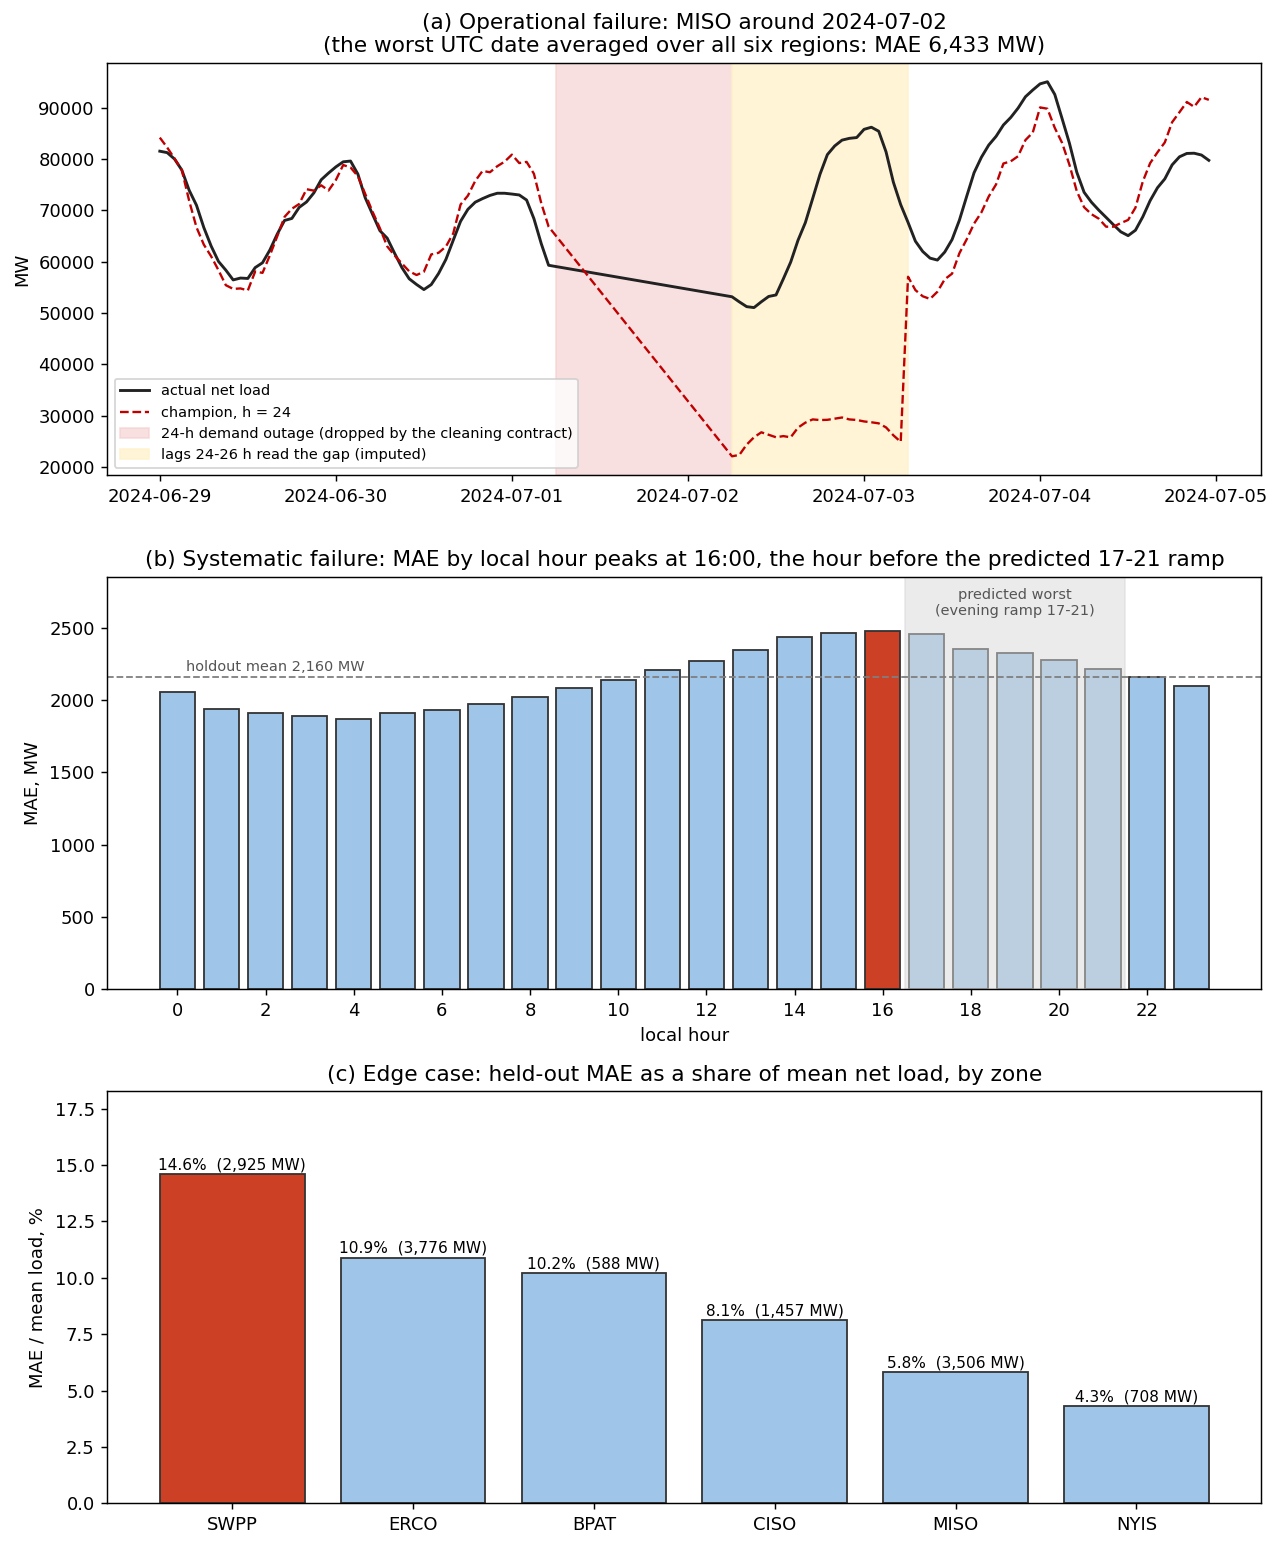

rows predicted from imputed lags: 233 (0.49%) MAE 7,562 MW vs clean rows 2,133 MW
by zone: {'BPAT': {'mae': 1480.8, 'rows': 17}, 'CISO': {'mae': 2045.3, 'rows': 72}, 'MISO': {'mae': 19309.2, 'rows': 72}, 'SWPP': {'mae': 2767.0, 'rows': 72}}


**Figure `04_failure_analysis.png`** — error by local hour, zone and temperature quintile, and the worst day.

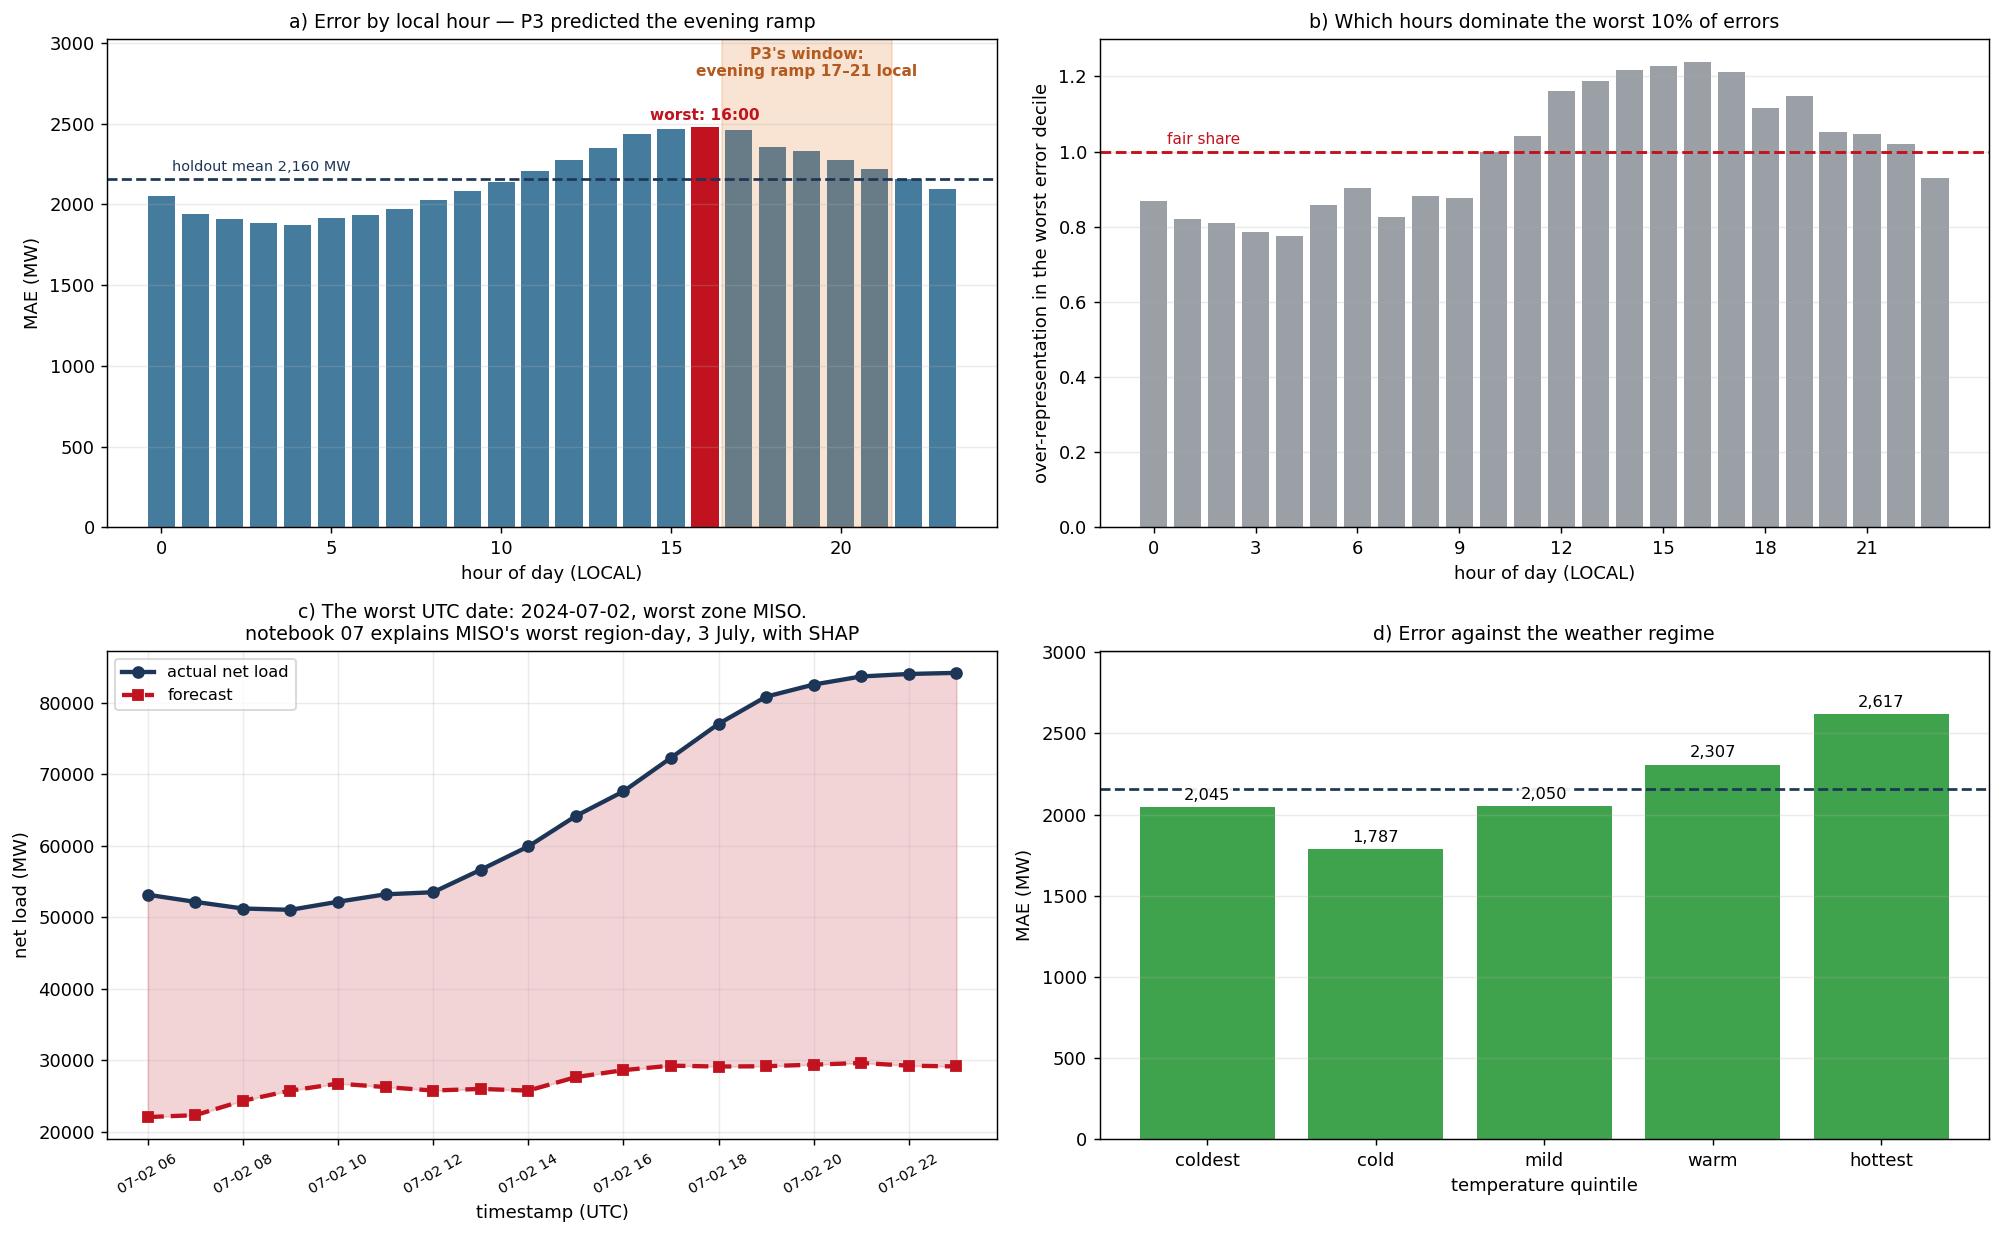

**Figure `04_missing_lag_flag.png`** — the abstention curve: coverage against MAE when rows with imputed lags are refused.

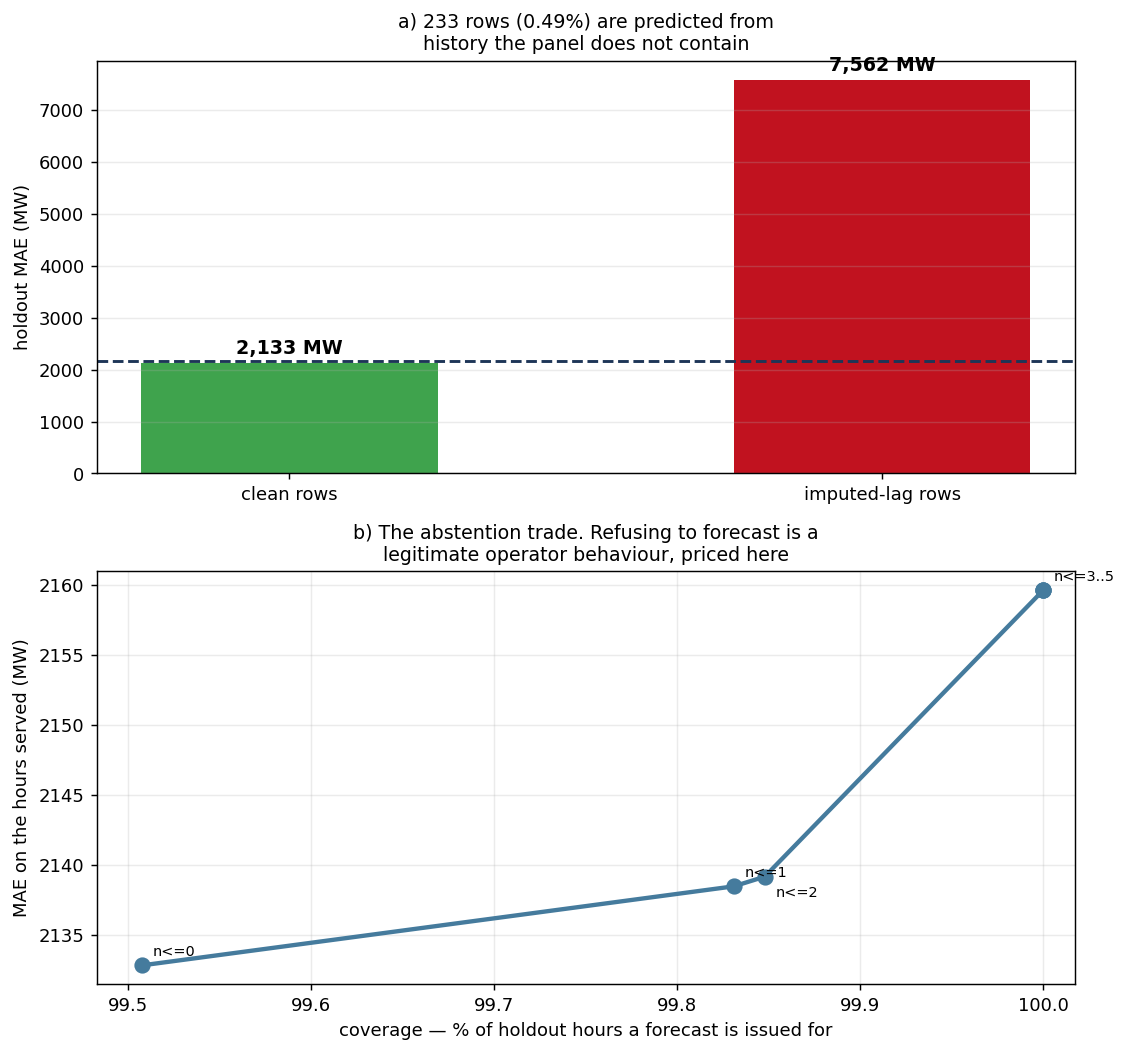

In [13]:
h24 = preds[preds.horizon == 24].copy()
h24["err"] = (h24.y_pred - h24.y_true).abs()

fig, axs = plt.subplots(3, 1, figsize=(10, 12))
# (a) the operational failure: a real week around the worst day
wz, wd = s4["failure_analysis"]["worst_day_zone"], pd.Timestamp(s4["failure_analysis"]["worst_day"])
w = h24[(h24.zone == wz) & (h24.timestamp >= wd - pd.Timedelta(days=3)) & (h24.timestamp < wd + pd.Timedelta(days=3))]
axs[0].plot(w.timestamp, w.y_true, color="#222", lw=1.6, label="actual net load")
axs[0].plot(w.timestamp, w.y_pred, color="#c00000", lw=1.3, ls="--", label="champion, h = 24")
gap0 = wd - pd.Timedelta(days=1) + pd.Timedelta(hours=6)
axs[0].axvspan(gap0, gap0 + pd.Timedelta(hours=24), color="#f4cccc", alpha=0.6, label="24-h demand outage (dropped by the cleaning contract)")
axs[0].axvspan(gap0 + pd.Timedelta(hours=24), gap0 + pd.Timedelta(hours=48), color="#fff2cc", alpha=0.8, label="lags 24-26 h read the gap (imputed)")
axs[0].set_title(f"(a) Operational failure: {wz} around {wd:%Y-%m-%d}\n(the worst UTC date averaged over all six regions: MAE {s4['failure_analysis']['worst_day_mae']:,.0f} MW)")
axs[0].set_ylabel("MW"); axs[0].legend(fontsize=8, loc="lower left")
# (b) the systematic failure: error by local hour
mh = pd.Series({int(k): v for k, v in s4["failure_analysis"]["mae_by_local_hour"].items()}).sort_index()
axs[1].bar(mh.index, mh.values, color=["#cc4125" if h_ == s4["failure_analysis"]["peak_error_local_hour"] else "#9fc5e8" for h_ in mh.index], edgecolor="#333")
axs[1].axhline(s4["holdout_mae"], color="#7f7f7f", ls="--", lw=1)
axs[1].text(0.2, s4["holdout_mae"] * 1.02, f"holdout mean {s4['holdout_mae']:,.0f} MW", fontsize=8, color="#555")
axs[1].axvspan(16.5, 21.5, color="#d9d9d9", alpha=0.5)
axs[1].set_ylim(0, mh.max() * 1.15)
axs[1].text(19, mh.max() * 1.12, "predicted worst\n(evening ramp 17-21)", ha="center", va="top", fontsize=8, color="#555")
axs[1].set_title(f"(b) Systematic failure: MAE by local hour peaks at {s4['failure_analysis']['peak_error_local_hour']}:00, the hour before the predicted 17-21 ramp")
axs[1].set_xlabel("local hour"); axs[1].set_ylabel("MAE, MW"); axs[1].set_xticks(range(0, 24, 2))
# (c) the representation failure: scaled error by zone
hz = pd.DataFrame(s4["holdout_by_zone"]).T.sort_values("scaled", ascending=False)
axs[2].bar(hz.index, hz.scaled, color=["#cc4125" if z == "SWPP" else "#9fc5e8" for z in hz.index], edgecolor="#333")
for i_, (z, v) in enumerate(hz.scaled.items()):
    axs[2].text(i_, v + 0.2, f"{v:.1f}%  ({hz.loc[z, 'mae']:,.0f} MW)", ha="center", fontsize=8.5)
axs[2].set_title("(c) Edge case: held-out MAE as a share of mean net load, by zone")
axs[2].set_ylabel("MAE / mean load, %"); axs[2].set_ylim(0, hz.scaled.max() * 1.25)
fig.tight_layout()
fig.savefig(cfg.FIGURES / "08_failure_cases.png", bbox_inches="tight")
plt.show()

flagged = s4["missing_lag_flag"]
print(f"rows predicted from imputed lags: {flagged['n_flagged']} ({flagged['share_flagged']:.2%}) "
      f"MAE {flagged['mae_flagged_rows']:,.0f} MW vs clean rows {flagged['mae_clean_rows']:,.0f} MW")
print("by zone:", flagged["by_zone"])
show("04_failure_analysis", "error by local hour, zone and temperature quintile, and the worst day.")
show("04_missing_lag_flag", "the abstention curve: coverage against MAE when rows with imputed lags are refused.")

**Figure: `08_failure_cases.png`.** (a) The MISO forecast tracks the actual until the lags read the dropped outage, then misses by up to 57,477 MW for 24 hours. (b) Error peaks at **16:00**, before the expected ramp window. (c) SWPP's error is **14.6%** of mean load against NYIS's **4.3%**.

In the operational case the inputs are wrong, not the model. The systematic case comes from a symmetric, hour-blind loss while the error concentrates in the afternoon, where solar falls and net load turns up.

**Proposed fixes (not implemented):** (1) use the `n_missing_lags` flag to abstain — refusing 0.49% of rows brings MAE to **2,133 MW** (`04_missing_lag_flag`); (2) an hour-aware loss or a solar-ramp feature; (3) a second weather point in the wind corridor and rolling-origin evaluation so every season is scored.

### 8.4h (continued) — How large the afternoon failure is

A rough estimate, not a measurement: assume solar-ramp features remove a third of the afternoon's excess error over the overnight hours, spread over the day. Six- to eight-hour afternoon windows are shown so the range is on record, and the estimate is compared with what the whole tuning search bought.

In [14]:
# WHAT: afternoon against overnight error, and the value of removing a third of the gap.
# WHY:  the remedy for the 16:00 failure is quoted as an estimate; this is its arithmetic.
_mh = pd.Series({int(k): v for k, v in s4["failure_analysis"]["mae_by_local_hour"].items()}).sort_index()
_rows = []
for (a0, a1), (o0, o1) in (((12, 17), (0, 5)), ((12, 18), (0, 6)), ((12, 19), (0, 7))):
    _aft, _ovn = float(_mh.loc[a0:a1].mean()), float(_mh.loc[o0:o1].mean())
    _n = a1 - a0 + 1
    _rows.append({"afternoon": f"{a0:02d}-{a1:02d}", "overnight": f"{o0:02d}-{o1:02d}",
                  "hours": _n, "afternoon_mae": _aft, "overnight_mae": _ovn,
                  "excess_mw_per_hour": _aft - _ovn,
                  "third_of_excess_on_headline_mw": (_aft - _ovn) / 3 * _n / 24})
aft_windows = pd.DataFrame(_rows)
display(aft_windows.round(1))
_hgb = s4["ladder"]["3  hist gradient boosting"]["cv_mae_mean"]
tuning_gain = float(_hgb - s4["cv_mae"])
print(f"a third of the afternoon excess is worth "
      f"{aft_windows.third_of_excess_on_headline_mw.min():,.0f} to "
      f"{aft_windows.third_of_excess_on_headline_mw.max():,.0f} MW on the headline; "
      f"the whole tuning search bought {tuning_gain:,.1f} MW of CV MAE "
      f"({_hgb:,.0f} -> {s4['cv_mae']:,.0f})")
R.save("nb08", {"afternoon_excess": {"windows": aft_windows.to_dict("records"),
                                     "tuning_gain_mw": tuning_gain}});

,afternoon,overnight,hours,afternoon_mae,overnight_mae,excess_mw_per_hour,third_of_excess_on_headline_mw
0,12-17,00-05,6,"2,410.200","1,929.200",481.000,40.100
1,12-18,00-06,7,"2,402.300","1,930.100",472.200,45.900
2,12-19,00-07,8,"2,393.200","1,935.400",457.800,50.900


a third of the afternoon excess is worth 40 to 51 MW on the headline; the whole tuning search bought 65.8 MW of CV MAE (2,173 -> 2,107)
[results read-only] nb08: 1 key(s) verified against the ledger, nothing written


### 8.5 — Unsupervised learning: the results in one table

The best configuration of k-means, Ward and DBSCAN on the PCA of within-day normalised net-load shapes (**13,069** zone-days × 24 hours), with silhouette, Calinski–Harabasz, Davies–Bouldin and ARI stability under 80% resampling. The chosen model is the reproducible one, not the tidiest.

algorithm,n_components,param,n_clusters,noise_fraction,silhouette,davies_bouldin,calinski_harabasz,ari_stability,seconds
kmeans,5,3.000000,3,0.0%,0.429,1.010,"9,273",0.996,1.2
dbscan,8,0.415000,4,6.9%,0.160,1.533,164,0.920,3.1
ward,8,3.000000,3,0.0%,0.384,1.063,"6,295",0.666,20.3


chosen: kmeans k=3 on 5 PCs (94.8% of shape variance) -> ARI 0.996, silhouette 0.429
k picked by each metric: {'ari_stability': 3, 'calinski_harabasz': 3, 'davies_bouldin': 3, 'silhouette': 3} | Ward dendrogram suggests k = 2


**Figure `05_cluster_metrics.png`** — the four metrics against k for each algorithm.

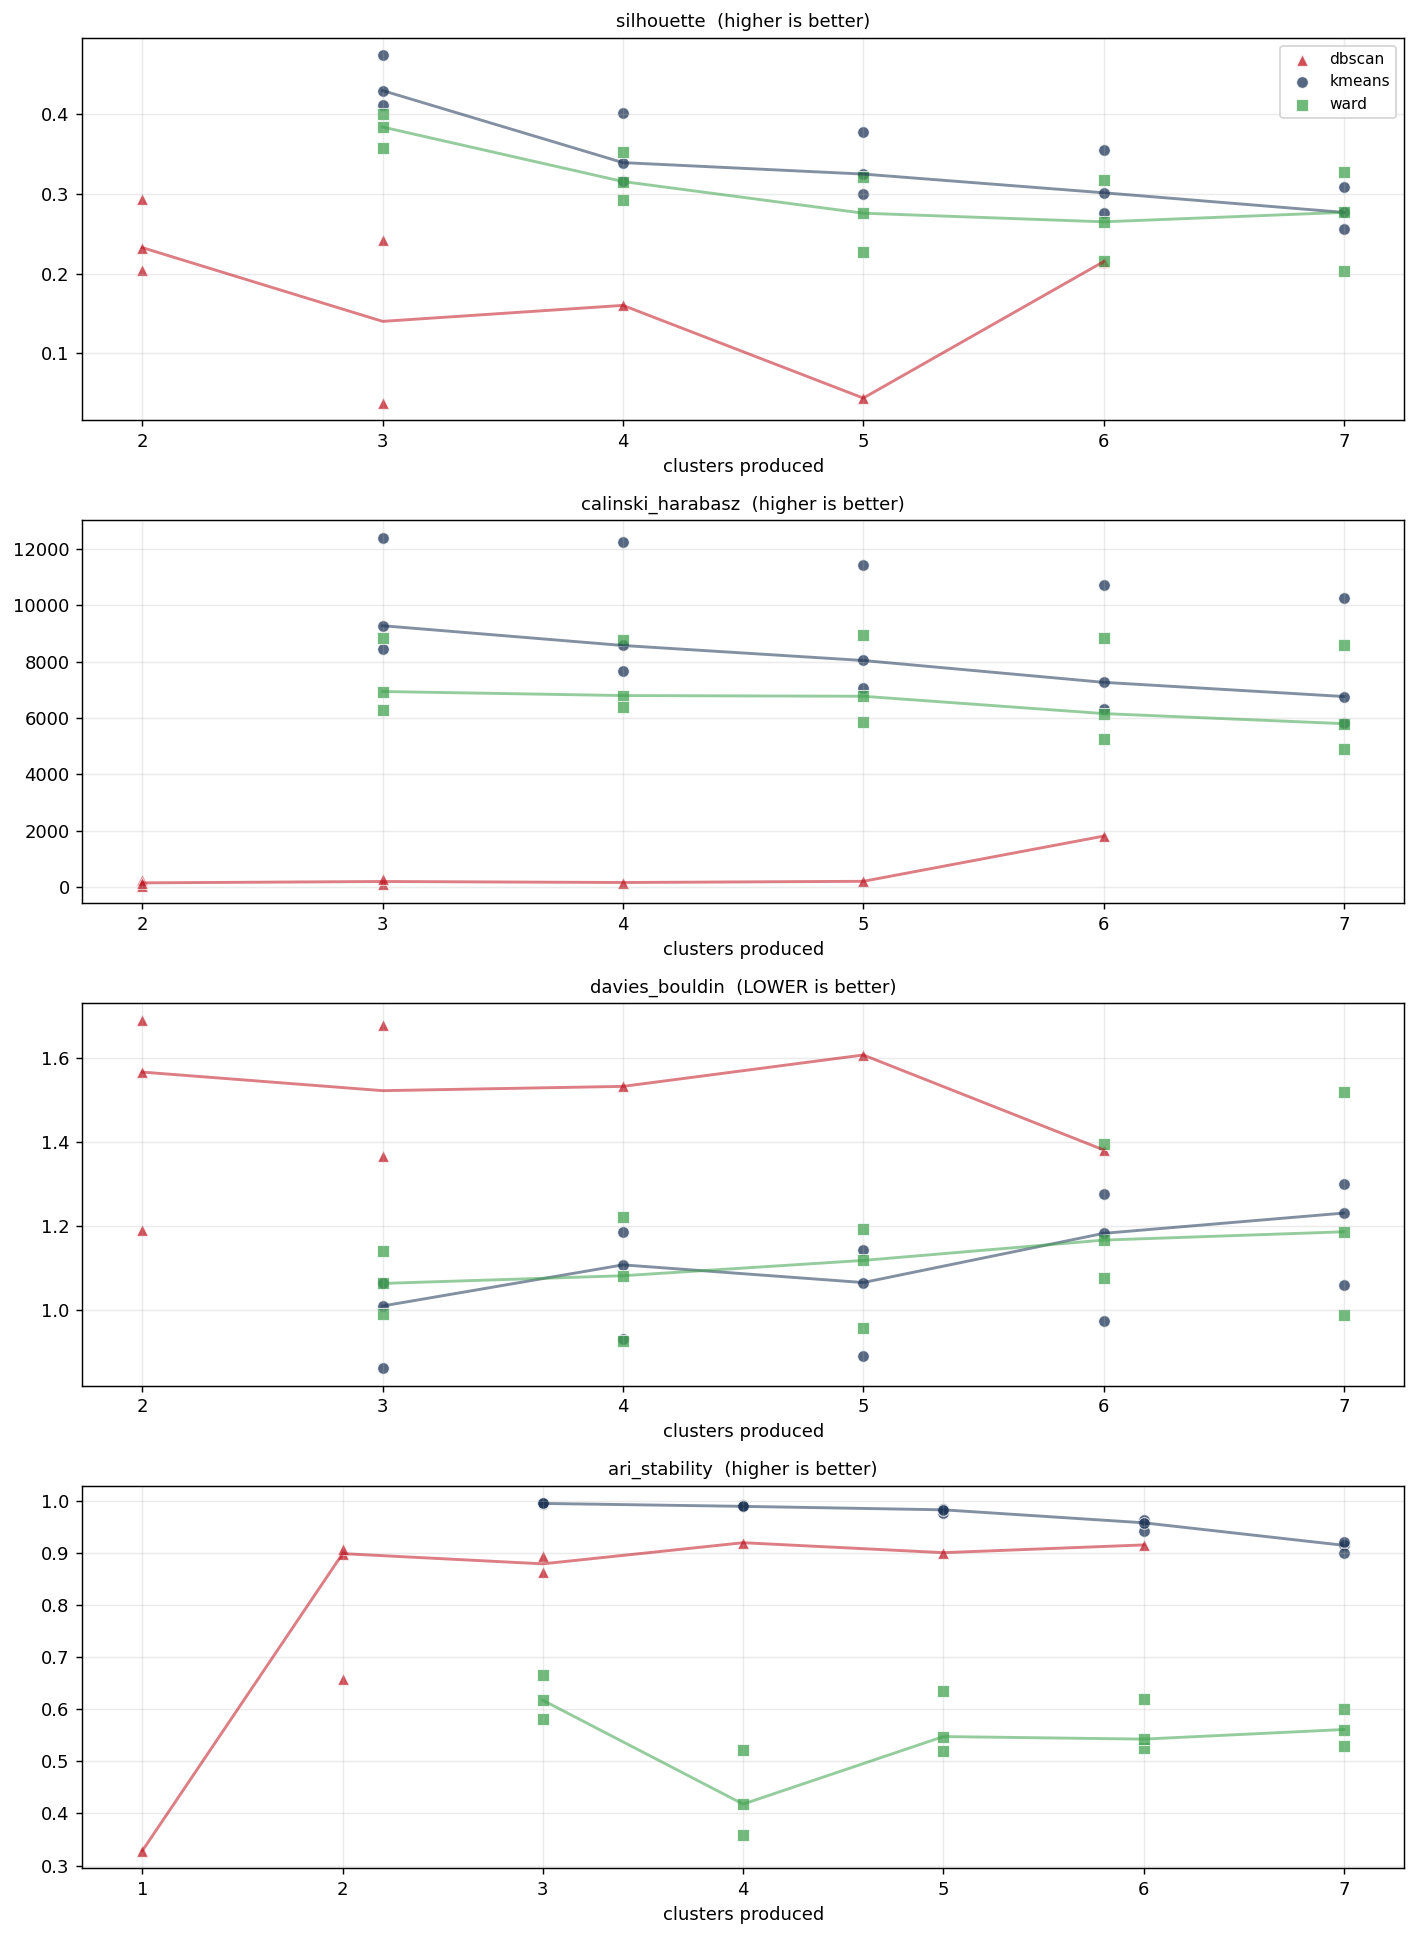

In [15]:
g = pd.DataFrame(s5["grid"])
best_rows = (g.sort_values("ari_stability", ascending=False)
              .groupby("algorithm", as_index=False).head(1)
              .sort_values("ari_stability", ascending=False))
display(best_rows[["algorithm", "n_components", "param", "n_clusters", "noise_fraction", "silhouette",
                   "davies_bouldin", "calinski_harabasz", "ari_stability", "seconds"]]
        .style.hide(axis="index").format({"silhouette": "{:.3f}", "davies_bouldin": "{:.3f}", "calinski_harabasz": "{:,.0f}",
                                          "ari_stability": "{:.3f}", "noise_fraction": "{:.1%}", "seconds": "{:.1f}"}))
print(f"chosen: {s5['chosen_algorithm']} k={s5['n_clusters']} on {s5['chosen_pcs']} PCs "
      f"({s5['pca_explained_variance_total']:.1%} of shape variance) -> ARI {s5['ari_stability']:.3f}, silhouette {s5['silhouette']:.3f}")
print("k picked by each metric:", s5["metric_picks_n_clusters"], "| Ward dendrogram suggests k =", s5["ward_suggested_k"])
show("05_cluster_metrics", "the four metrics against k for each algorithm.")

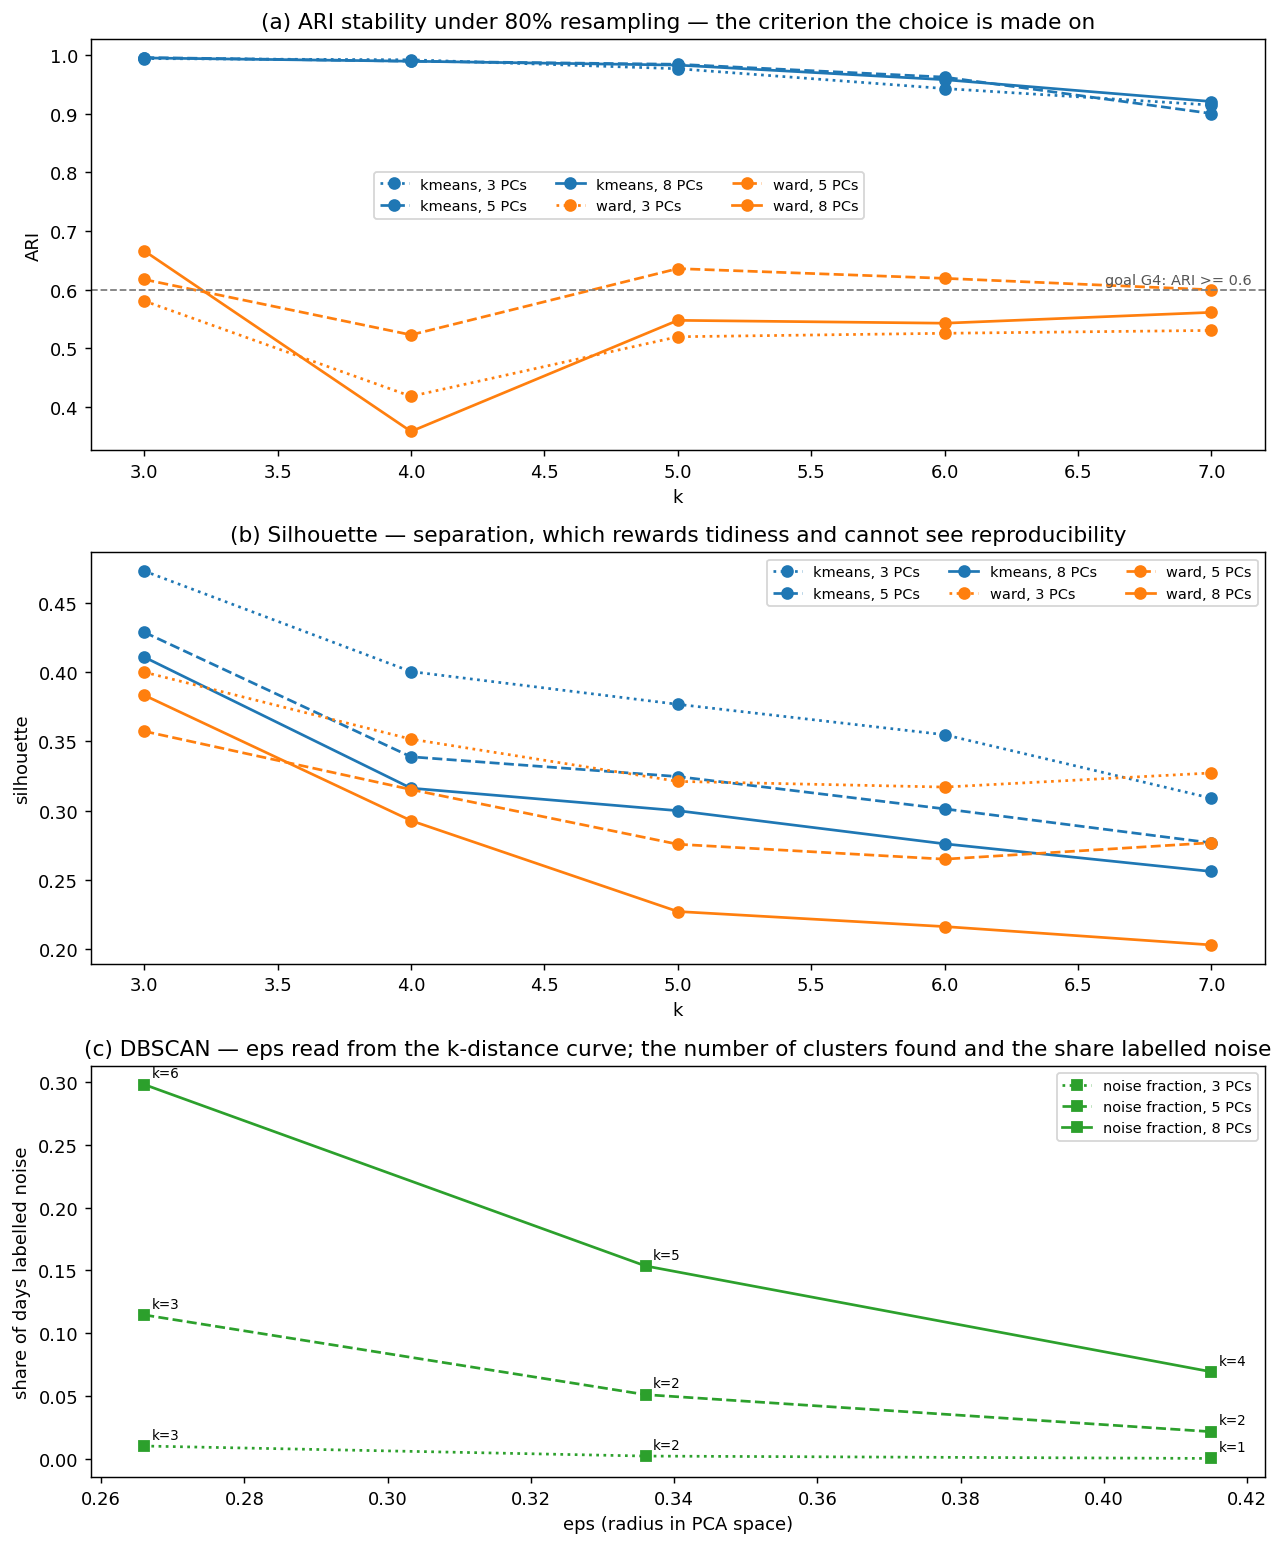

In [16]:
fig, axs = plt.subplots(3, 1, figsize=(10, 12))
styles = {3: ":", 5: "--", 8: "-"}
for algo, col in [("kmeans", "#1f77b4"), ("ward", "#ff7f0e")]:
    for pcs, ls in styles.items():
        sub = g[(g.algorithm == algo) & (g.n_components == pcs)].sort_values("n_clusters")
        axs[0].plot(sub.n_clusters, sub.ari_stability, ls=ls, marker="o", color=col, label=f"{algo}, {pcs} PCs")
        axs[1].plot(sub.n_clusters, sub.silhouette, ls=ls, marker="o", color=col, label=f"{algo}, {pcs} PCs")
axs[0].set_title("(a) ARI stability under 80% resampling — the criterion the choice is made on")
axs[0].set_xlabel("k"); axs[0].set_ylabel("ARI"); axs[0].axhline(0.6, color="#7f7f7f", ls="--", lw=1)
axs[0].legend(fontsize=8, ncol=3, loc="center", bbox_to_anchor=(0.45, 0.62))   # the empty middle, off the Ward lines
axs[0].text(6.6, 0.61, "goal G4: ARI >= 0.6", fontsize=8, color="#555")
axs[1].set_title("(b) Silhouette — separation, which rewards tidiness and cannot see reproducibility")
axs[1].set_xlabel("k"); axs[1].set_ylabel("silhouette"); axs[1].legend(fontsize=8, ncol=3)
db = g[g.algorithm == "dbscan"].sort_values(["n_components", "param"])
for pcs, ls in styles.items():
    sub = db[db.n_components == pcs]
    axs[2].plot(sub.param, sub.noise_fraction, ls=ls, marker="s", color="#2ca02c", label=f"noise fraction, {pcs} PCs")
    for _, row in sub.iterrows():
        axs[2].annotate(f"k={int(row.n_clusters)}", (row.param, row.noise_fraction), textcoords="offset points",
                        xytext=(4, 4), fontsize=7.5)
axs[2].set_title("(c) DBSCAN — eps read from the k-distance curve; the number of clusters found and the share labelled noise")
axs[2].set_xlabel("eps (radius in PCA space)"); axs[2].set_ylabel("share of days labelled noise"); axs[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(cfg.FIGURES / "08_unsupervised_summary.png", bbox_inches="tight")
plt.show()

**Figure: `08_unsupervised_summary.png` — sensitivity to k, to the number of components and to the algorithm.**

k-means is stable at every k (ARI **0.996** at k = 3 on 5 PCs, never below 0.90); Ward is much less so (**0.617** at k = 3 on 5 PCs). All four metrics pick **k = 3**. DBSCAN's best setting on 8 PCs labels **6.9%** of days as noise for 4 clusters; across its settings it finds 1 to 6 clusters, so its output depends on `eps` rather than on structure. At 5 PCs k-means also has the higher silhouette (0.429 vs 0.357). I ship k-means, k = 3, 5 PCs, and treat the regimes as hypotheses checked in 8.5b and 8.5c.

### 8.5 (continued) — Are the regimes an artefact of the representation?

The shipped pipeline refitted with three and eight components, and with two other normalisations (z-score per day, raw megawatts). `ari_vs_shipped` compares each partition with the shipped one (1 = identical); `same_regime_share` is the share of days that keep their regime; `ari_vs_region` shows how far a partition just sorts days by region; `picks` is the k each metric chooses.

In [17]:
# WHAT: the regimes under 3 / 5 / 8 components and under three normalisations.
# WHY:  the method rests on two representation choices that 8.5 does not vary.
# NOTE: the shipped partition is refitted first and must reproduce the saved labels.
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from src import features as P

_df = pd.read_parquet(cfg.PANEL)
_shapes = P.daily_shape_matrix(_df)
_lab = pd.read_parquet(cfg.DATA_PROC / "unsupervised" / "cluster_labels.parquet")
_key = pd.MultiIndex.from_arrays([_lab["zone"], pd.to_datetime(_lab["date"]).dt.date])
assert (_shapes.index == _key).all(), "row order differs from the saved labels"
_shipped, _zones = _lab["cluster"].to_numpy(), _lab["zone"].to_numpy()

# raw daily curves on the same rows and the same local clock as daily_shape_matrix
_d = _df[[cfg.TIME_COL, cfg.GROUP_COL, cfg.TARGET]].copy()
_loc = P.local_calendar_date(_d)
_hr = pd.Series(pd.NaT, index=_d.index, dtype="datetime64[ns]")
for _z, _tz in cfg.ZONE_TZ.items():
    _m = (_d[cfg.GROUP_COL] == _z).to_numpy()
    _hr[_m] = (pd.to_datetime(_d.loc[_m, cfg.TIME_COL]).dt.tz_localize("UTC")
               .dt.tz_convert(_tz).dt.tz_localize(None))
_d["date"], _d["hour"] = _loc.dt.date, _hr.dt.hour
_raw = (_d.pivot_table(index=[cfg.GROUP_COL, "date"], columns="hour", values=cfg.TARGET)
        .reindex(_shapes.index))
assert _raw.notna().all().all()
_X = {"min-max": _shapes.to_numpy(), "z-score": _raw.sub(_raw.mean(axis=1), axis=0)
      .div(_raw.std(axis=1), axis=0).to_numpy(), "raw MW": _raw.to_numpy()}


def _km(X, n, k=3):
    return np.asarray(P.make_clustering_pipeline(n_components=n, algorithm="kmeans", k=k)
                      .fit(X).named_steps["clust"].labels_)


def _same_share(a, b):
    ct = pd.crosstab(a, b).to_numpy()
    r_, c_ = linear_sum_assignment(-ct)
    return float(ct[r_, c_].sum() / ct.sum())


def _picks(X, n):
    rows = [dict(P.score_clustering(P.make_clustering_pipeline(n_components=n, algorithm="kmeans", k=k), X), k=k)
            for k in range(3, 8)]
    gk = pd.DataFrame(rows).set_index("k")
    return ({"silhouette": int(gk.silhouette.idxmax()), "calinski_harabasz": int(gk.calinski_harabasz.idxmax()),
             "davies_bouldin": int(gk.davies_bouldin.idxmin()), "ari_stability": int(gk.ari_stability.idxmax())},
            float(gk.loc[3, "ari_stability"]))


# the shipped representation is notebook 05's choice (most stable configuration), read, not assumed
_PCS = int(s5["chosen_pcs"])
assert adjusted_rand_score(_shipped, _km(_X["min-max"], _PCS)) > 0.999999, "shipped partition not reproduced"
_g = pd.DataFrame(s5["grid"])
sens = []
for _name, _n in (("min-max", 3), ("min-max", 5), ("min-max", 8), ("z-score", _PCS), ("raw MW", _PCS)):
    _lb = _km(_X[_name], _n)
    if _name == "min-max":
        _row = _g[(_g.algorithm == "kmeans") & (_g.n_components == _n)]
        _pk = {m: int(_row.loc[_row[m].idxmin() if m == "davies_bouldin" else _row[m].idxmax(), "n_clusters"])
               for m in ("silhouette", "calinski_harabasz", "davies_bouldin", "ari_stability")}
        _stab = float(_row[_row.param == 3.0].ari_stability.iloc[0])
    else:
        _pk, _stab = _picks(_X[_name], _n)
    sens.append({"normalisation": _name, "n_components": _n,
                 "variance_kept": float(PCA(n_components=_n, random_state=cfg.SEED).fit(_X[_name])
                                        .explained_variance_ratio_.sum()),
                 "picks": _pk, "stability_k3": _stab,
                 "ari_vs_shipped": float(adjusted_rand_score(_shipped, _lb)),
                 "same_regime_share": _same_share(_shipped, _lb),
                 "ari_vs_region": float(adjusted_rand_score(_zones, _lb)),
                 "largest_region_share_by_cluster": [
                     float(v) for v in (pd.crosstab(_lb, _zones).max(axis=1)
                                        / pd.crosstab(_lb, _zones).sum(axis=1))]})
display(pd.DataFrame(sens).drop(columns="largest_region_share_by_cluster").round(4))
print("raw MW clusters by zone (a partition by system size, not by shape):")
display(pd.crosstab(pd.Series(_km(_X["raw MW"], _PCS), name="cluster"), pd.Series(_zones, name="zone")))
R.save("nb08", {"regime_sensitivity": sens});

,normalisation,n_components,variance_kept,picks,stability_k3,ari_vs_shipped,same_regime_share,ari_vs_region
0,min-max,3,0.846,"{'silhouette': 3, 'calinski_harabasz': 3, 'dav...",0.994,0.975,0.991,0.169
1,min-max,5,0.948,"{'silhouette': 3, 'calinski_harabasz': 3, 'dav...",0.996,1.000,1.000,0.168
2,min-max,8,0.986,"{'silhouette': 3, 'calinski_harabasz': 3, 'dav...",0.995,0.999,1.000,0.168
3,z-score,5,0.961,"{'silhouette': 3, 'calinski_harabasz': 3, 'dav...",0.997,0.939,0.980,0.166
4,raw MW,5,0.999,"{'silhouette': 3, 'calinski_harabasz': 6, 'dav...",0.977,-0.034,0.392,0.260


raw MW clusters by zone (a partition by system size, not by shape):


zone,BPAT,CISO,ERCO,MISO,NYIS,SWPP
cluster,,,,,,
0,0,280,1731,114,64,782
1,0,0,178,2069,0,0
2,2176,1902,276,0,2117,1380


[results read-only] nb08: 1 key(s) verified against the ledger, nothing written


### 8.5b — The regimes, named from their shapes and checked against the weather

Each centroid is described by its minimum hour, midday belly and evening ramp, then compared with weather the clustering never saw. Cluster 2 is the duck (minimum at 13:00 local): its days are **12.4 points less cloudy** with **26.8 W/m² more** irradiance than the panel mean. Within regions this holds in only 2 of 6, because 77% of duck days are CISO's.

,name,n,share,argmin_hour,midday_belly,evening_ramp,d_temp,d_cloud_cover,d_ghi,d_wind_speed_100m
cluster,,,,,,,,,,
0,winter-shaped,2496,19.1%,23,0.635000,0.173000,-8.3 C,+8.9 pp,-51.8 W/m2,+1.0 km/h
1,conventional,7782,59.5%,4,0.693000,0.364000,+2.0 C,+1.5 pp,+7.6 W/m2,+1.8 km/h
2,DUCK,2791,21.4%,13,0.111000,0.841000,+2.0 C,-12.4 pp,+26.8 W/m2,-6.0 km/h


**Figure `05_centroids.png`** — the three centroids as normalised 24-hour profiles on local time.

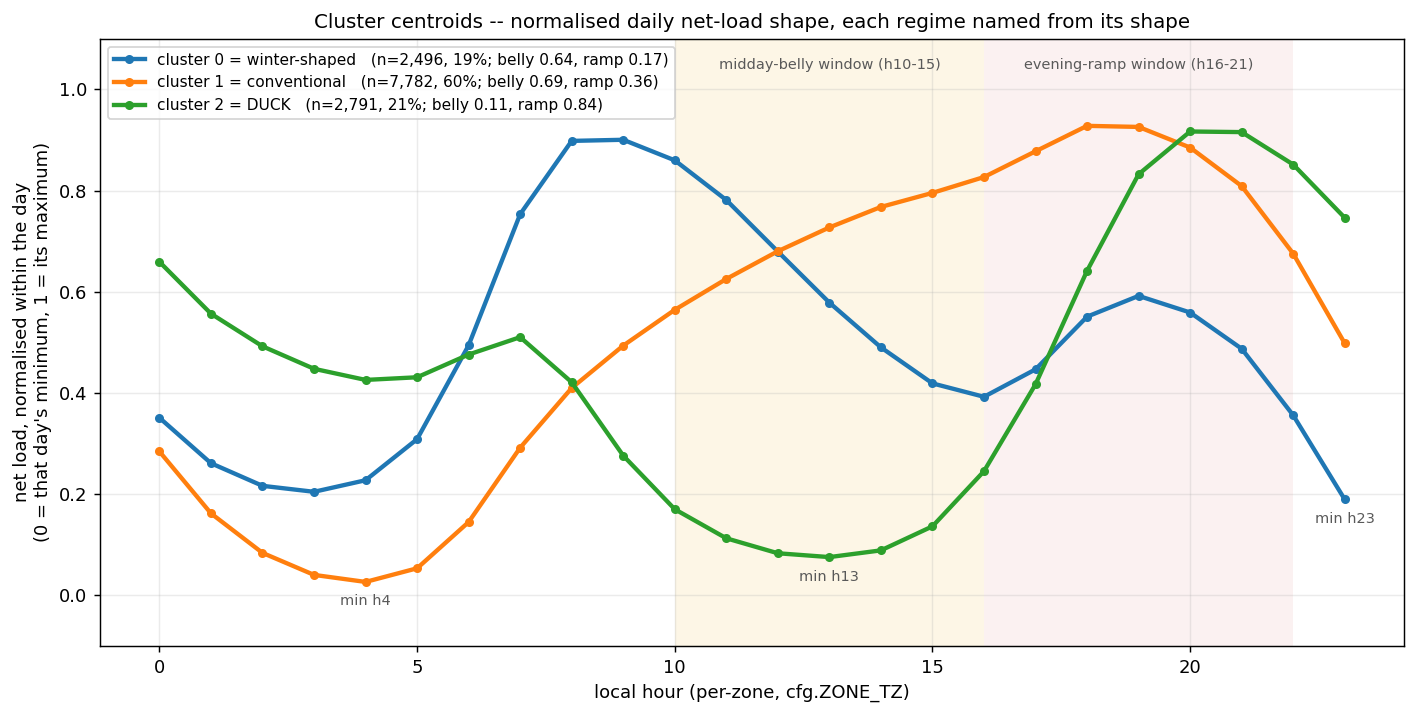

**Figure `05_regime_weather.png`** — mean weather per regime, for variables the clustering never saw.

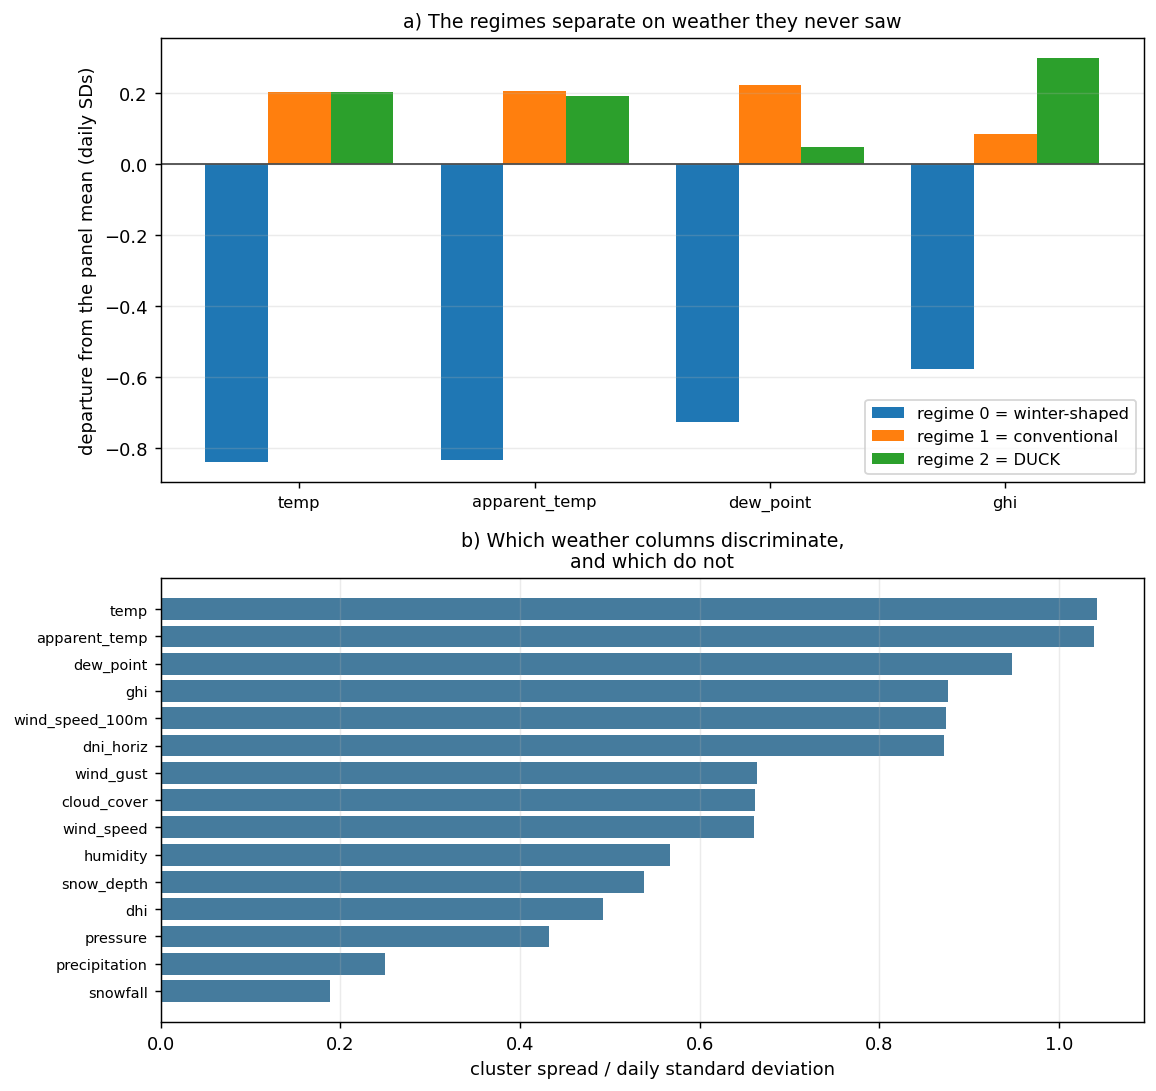

In [18]:
reg = pd.DataFrame(s5["centroid_summary"]).set_index("cluster")
reg["name"] = pd.Series({int(k): v for k, v in s5["regime_names"].items()})
reg["share"] = reg.n / reg.n.sum()
delta = pd.DataFrame(s5["regime_weather_signature"]["delta_from_panel_mean"]).T
delta.index = delta.index.astype(int)
reg = reg.join(delta[["temp", "cloud_cover", "ghi", "wind_speed_100m"]].add_prefix("d_"))
display(reg[["name", "n", "share", "argmin_hour", "midday_belly", "evening_ramp", "d_temp", "d_cloud_cover", "d_ghi", "d_wind_speed_100m"]]
        .style.format({"share": "{:.1%}", "d_temp": "{:+.1f} C", "d_cloud_cover": "{:+.1f} pp", "d_ghi": "{:+.1f} W/m2",
                       "d_wind_speed_100m": "{:+.1f} km/h"}))
show("05_centroids", "the three centroids as normalised 24-hour profiles on local time.")
show("05_regime_weather", "mean weather per regime, for variables the clustering never saw.")

### 8.5c — Downstream utility and an external surrogate

Two outside checks. First, the regime label as a forecasting feature: yesterday's label is worth 17 MW (p = 0.030), the label two days back 1.5 MW (p = 0.788), and the leaked same-day label (a control) 31 MW (p = 0.009) — a small real gain, a null, and a leak in the expected order. Second, a depth-3 tree predicting the regime from weather and calendar reaches balanced accuracy **0.627 ± 0.085** against chance 0.333.

,model,added_features,cv_mae_mean,cv_mae_sd,n_dev
0 baseline (no cluster feature),hist_gradient_boosting,[],"2,173.2",85.5,"268,186"
"1 cluster_prev (admissible, batch day-ahead)",hist_gradient_boosting,['cluster_prev'],"2,155.8",87.6,"268,186"
1b cluster_prev2 (admissible at every origin),hist_gradient_boosting,['cluster_prev2'],"2,171.7",76.5,"268,186"
2 cluster_same (LEAK),hist_gradient_boosting,['cluster_same'],"2,142.6",74.2,"268,186"


{'depth': 3, 'features': ['temp', 'cloud_cover', 'humidity', 'wind_speed', 'month', 'dayofweek', 'is_weekend'], 'cv_balanced_mean': 0.626929815704508, 'cv_balanced_sd': 0.08492306070273964, 'chance_baseline': 0.3333333333333333, 'majority_baseline': 0.5954548932588568, 'metric_to_read': 'balanced accuracy against chance'}


**Figure `05_downstream_utility.png`** — CV MAE with and without the regime feature, admissible and leaked.

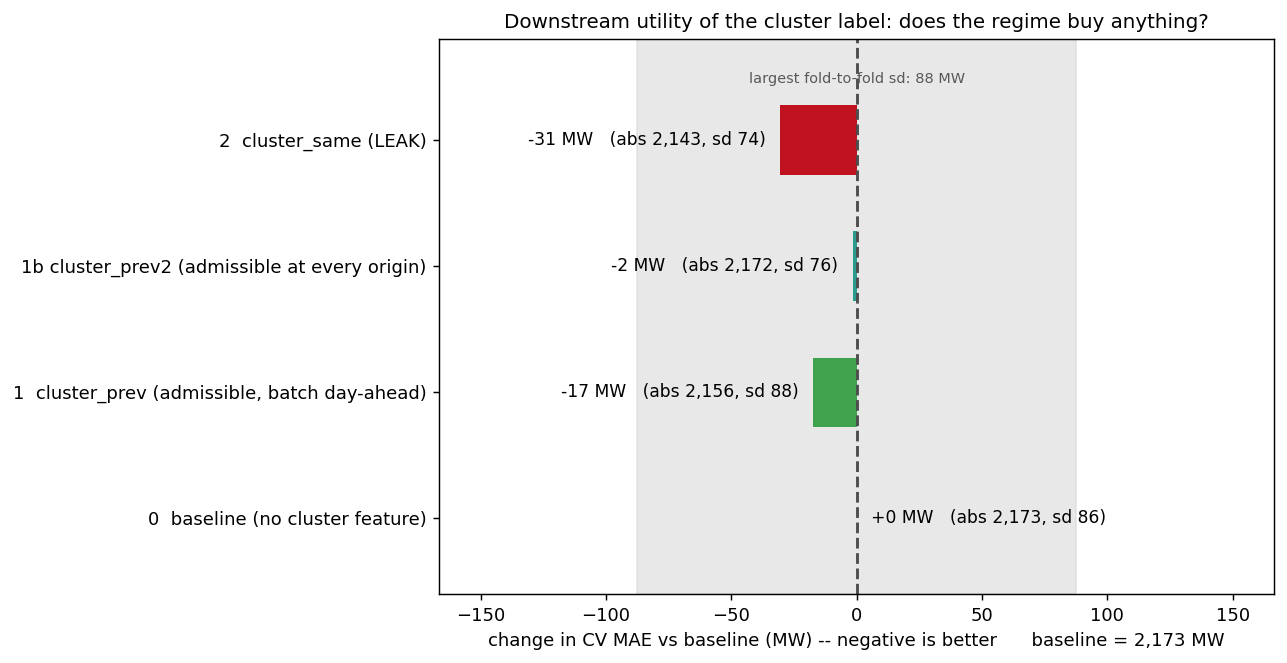

**Figure `07_cluster_tree.png`** — the depth-3 surrogate that turns the regimes into rules on weather and calendar.

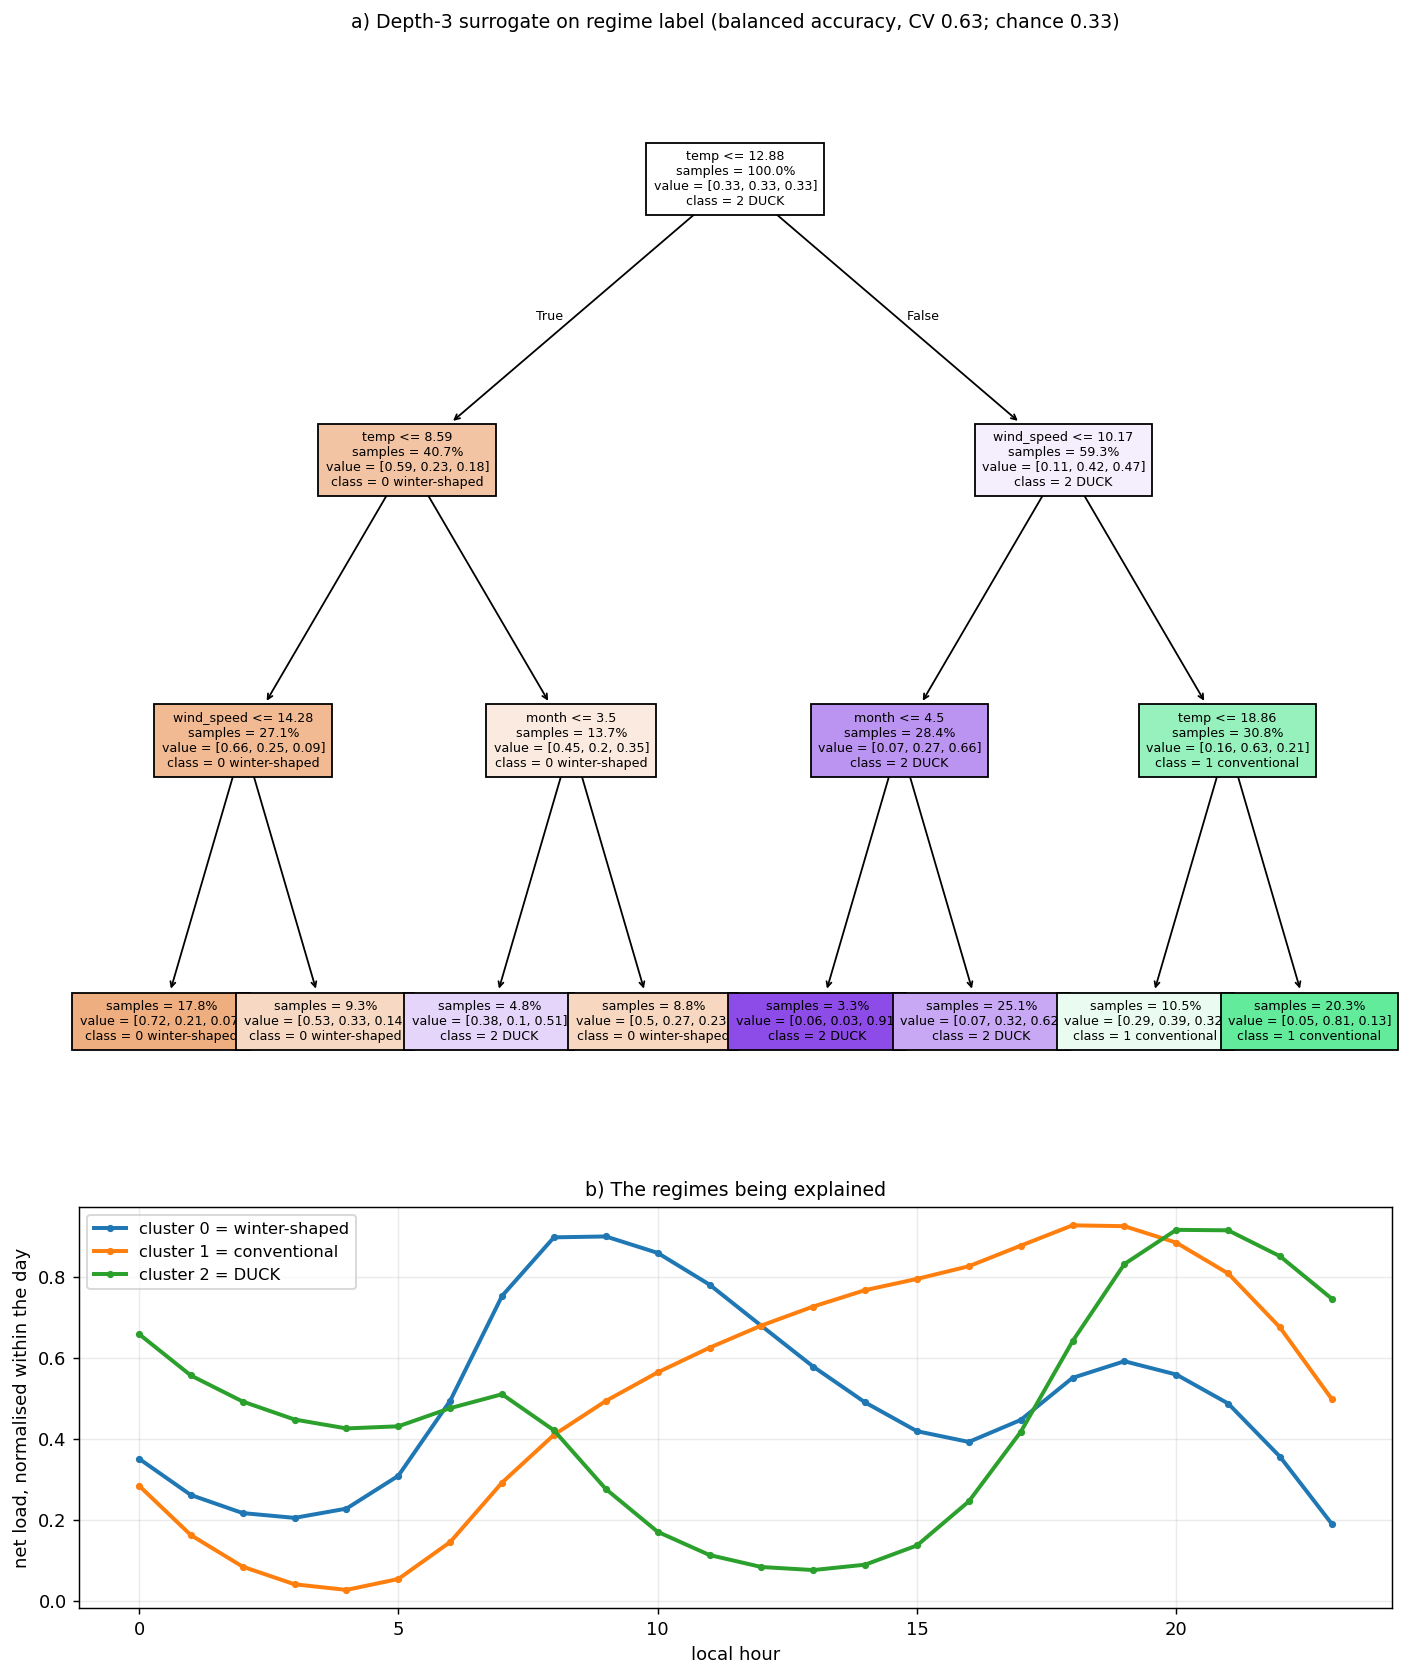

In [19]:
dsr = pd.DataFrame(s5["downstream"]).T[["model", "added_features", "cv_mae_mean", "cv_mae_sd", "n_dev"]]
display(dsr.style.format({"cv_mae_mean": "{:,.1f}", "cv_mae_sd": "{:,.1f}", "n_dev": "{:,}"}))
print({k: s7["surrogate"][k] for k in ["depth", "features", "cv_balanced_mean", "cv_balanced_sd", "chance_baseline",
                                        "majority_baseline", "metric_to_read"]})
show("05_downstream_utility", "CV MAE with and without the regime feature, admissible and leaked.")
show("07_cluster_tree", "the depth-3 surrogate that turns the regimes into rules on weather and calendar.")

### 8.6 — Uncertainty: coverage against width, method by method

Every interval method from notebook 06, scored on the holdout by coverage of the nominal 90% band, mean width and Winkler score (which penalises both width and misses), plus per-zone coverage. The raw quantile model covers only **80.4%**; split conformal reaches **88.6%** but is 48% wider and worse on Winkler (15,751 vs 12,125); the shipped CQR with per-zone (Mondrian) conditioning reaches **88.7%** at 8,709 MW with Winkler **11,545**. One variant scores slightly better (11,410); CQR was chosen by rule for its finite-sample guarantee.

,coverage,coverage_error_pts,mean_width,winkler
"per-level shifts, Mondrian by zone",0.889,-1.1,"8,667","11,410"
"CQR additive, Mondrian by zone",0.887,-1.3,"8,709","11,545"
"CQR scaled, Mondrian by zone",0.889,-1.1,"8,858","11,628"
CQR scaled,0.888,-1.2,"8,676","11,671"
per-level shifts,0.889,-1.1,"8,212","11,948"
CQR additive,0.884,-1.6,"8,210","12,121"
raw quantile GBM (full dev),0.804,-9.6,"7,135","12,125"
raw quantile GBM (fit block),0.783,-11.7,"6,972","12,805"
split conformal,0.886,-1.4,"10,594","15,751"


,pooled CQR,Mondrian CQR (shipped),median after (Mondrian)
BPAT,0.995,0.917,0.502
CISO,0.898,0.867,0.609
ERCO,0.800,0.875,0.524
MISO,0.816,0.881,0.516
NYIS,0.959,0.889,0.558
SWPP,0.838,0.891,0.522


zone coverage spread: pooled 19.6 pts -> Mondrian 5.0 pts; crossings 10.0% -> 0.0%; calibrated median 0.538 (target 0.500)


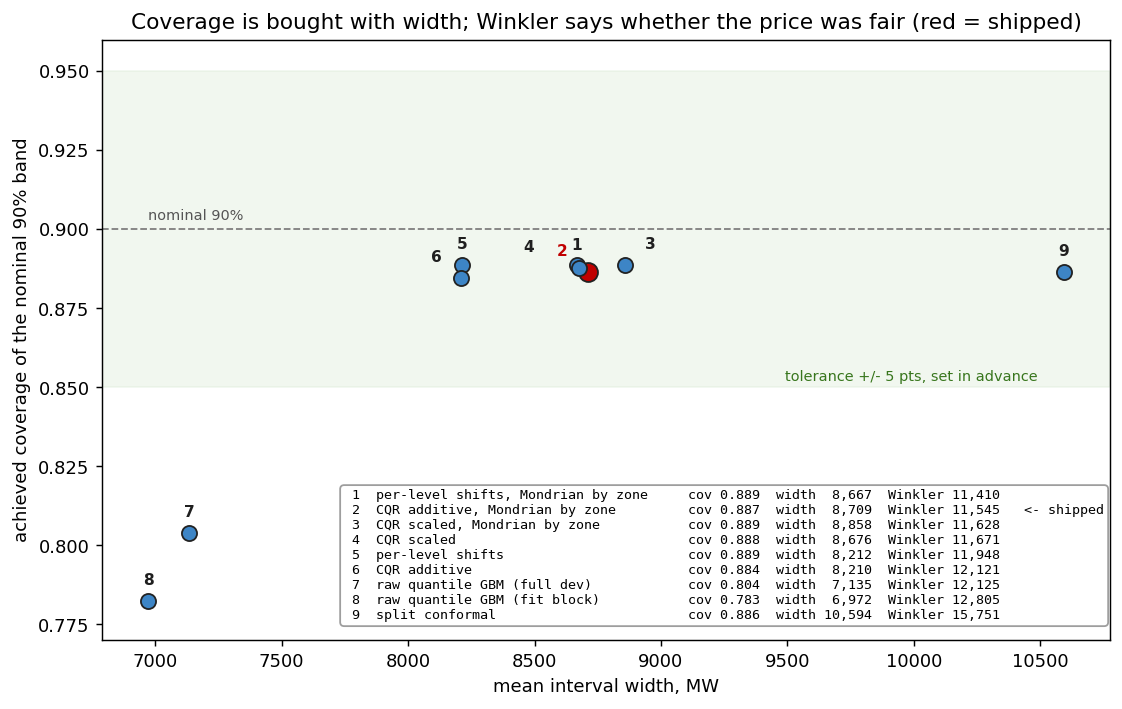

**Figure `06_calibration.png`** — nominal against empirical quantile levels, method by method.

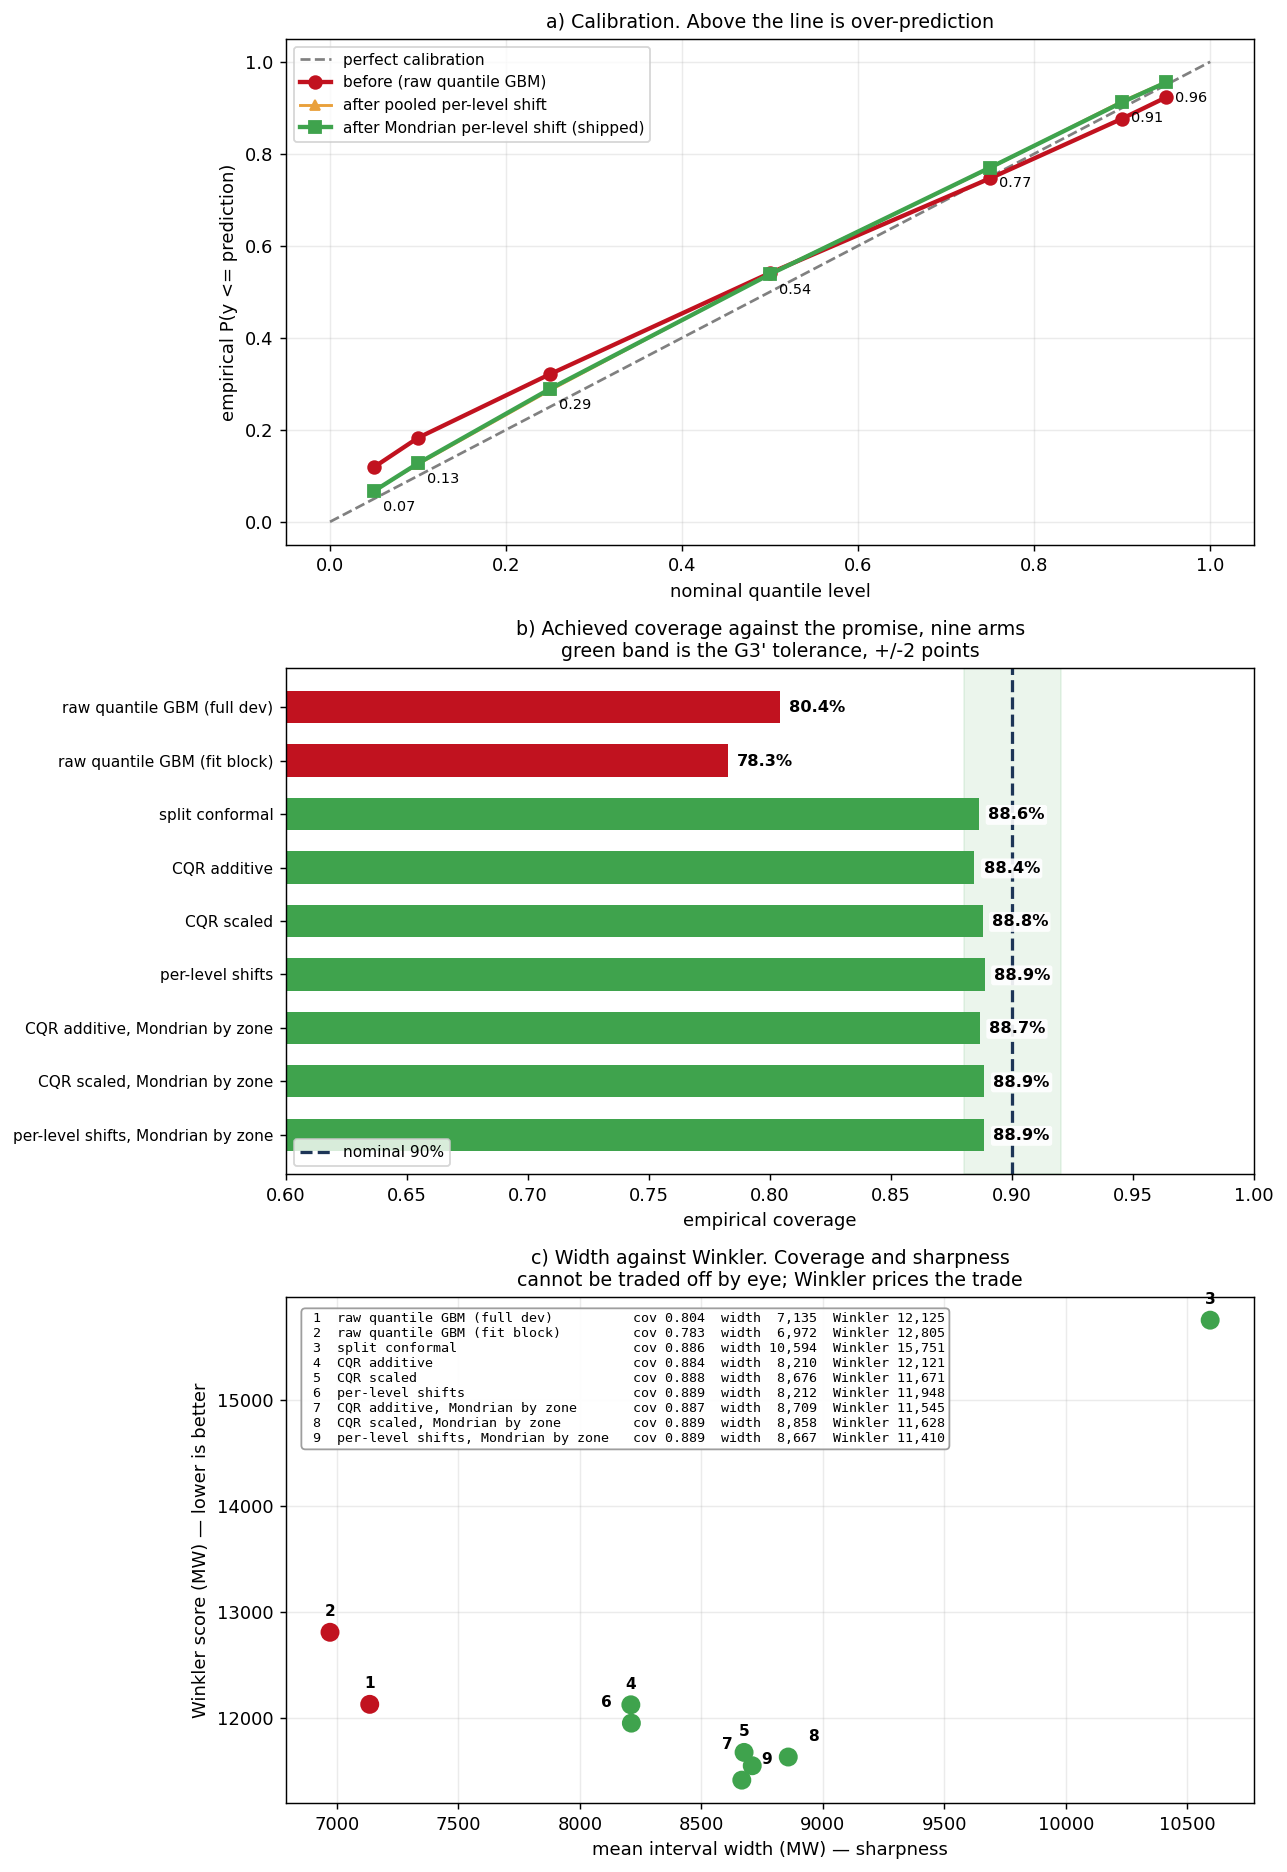

**Figure `06_mondrian_by_zone.png`** — per-zone coverage, pooled against Mondrian.

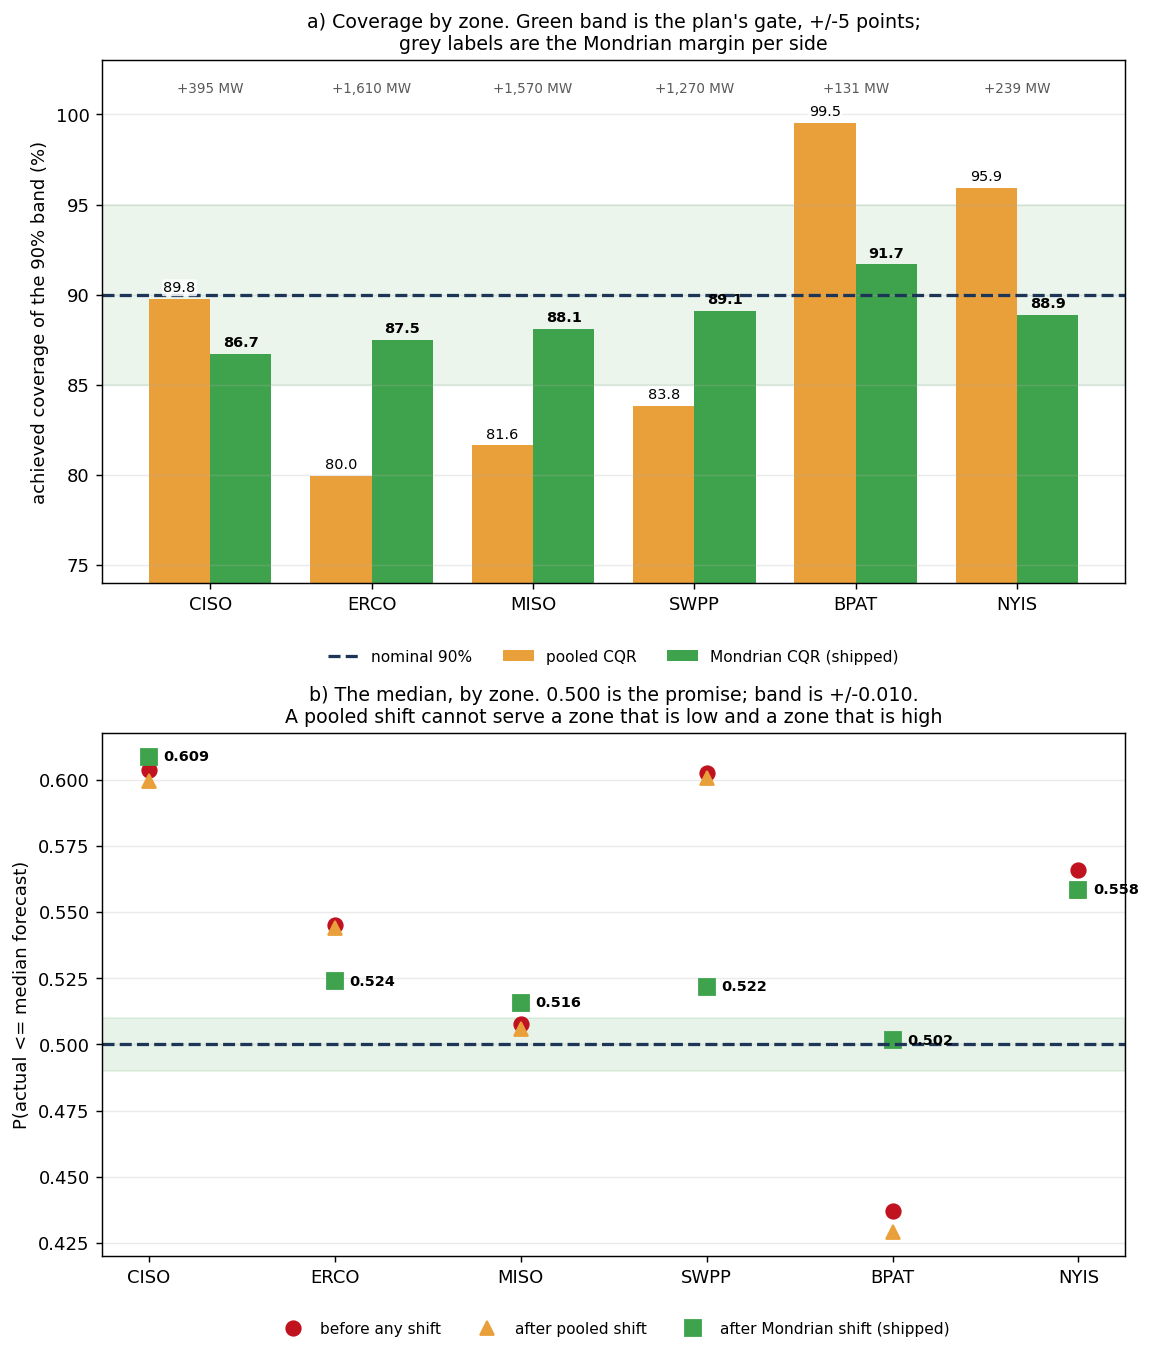

In [20]:
icd = pd.DataFrame(s6["interval_comparison"]).T.sort_values("winkler")
display(icd.style.format({"coverage": "{:.3f}", "coverage_error_pts": "{:+.1f}", "mean_width": "{:,.0f}", "winkler": "{:,.0f}"}))
zc = pd.DataFrame({"pooled CQR": {z["group"]: z["coverage"] for z in s6["coverage_by_zone_pooled"]},
                   "Mondrian CQR (shipped)": {z["group"]: z["coverage"] for z in s6["coverage_by_zone"]},
                   "median after (Mondrian)": s6["median_by_zone"]["Mondrian shift"]})
display(zc.style.format("{:.3f}"))
print(f"zone coverage spread: pooled {s6['zone_coverage_spread_pts_pooled']:.1f} pts -> Mondrian {s6['zone_coverage_spread_pts']:.1f} pts; "
      f"crossings {s6['cross_rate']:.1%} -> {s6['cross_rate_after']:.1%}; calibrated median {s6['median_after']:.3f} (target 0.500)")

fig, ax = plt.subplots(figsize=(10, 6))
legend_lines = []
# Numbers of points within 200 MW / 0.005 of an earlier one are spread sideways, so
# none prints over its neighbour (points 1, 2 and 4 sit within 60 MW of each other).
_placed, _dxs = [], [0, -14, 14, -28, 28]
for k_, (name, row) in enumerate(icd.iterrows(), 1):
    shipped = name == s6["primary_method"]
    ax.scatter(row.mean_width, row.coverage, s=110 if shipped else 70, color="#c00000" if shipped else "#3d85c6",
               edgecolor="#222", zorder=3)
    _near = sum(1 for p in _placed if abs(p[0] - row.mean_width) < 200 and abs(p[1] - row.coverage) < 0.005)
    ax.annotate(str(k_), (row.mean_width, row.coverage), textcoords="offset points",
                xytext=(_dxs[min(_near, 4)], 9), ha="center", fontsize=8.5,
                weight="bold", color="#c00000" if shipped else "#1f1f1f")
    _placed.append((row.mean_width, row.coverage))
    legend_lines.append(f"{k_:>2}  {name:<38s} cov {row.coverage:.3f}  width {row.mean_width:>6,.0f}  Winkler {row.winkler:>6,.0f}"
                        + ("   <- shipped" if shipped else ""))
ax.axhline(0.90, color="#7f7f7f", ls="--", lw=1); ax.text(icd.mean_width.min(), 0.903, "nominal 90%", fontsize=8, color="#555")
ax.axhspan(0.85, 0.95, color="#d9ead3", alpha=0.35); ax.text(icd.mean_width.max() * 0.99, 0.852, "tolerance +/- 5 pts, set in advance", ha="right", fontsize=8, color="#38761d")
ax.text(0.24, 0.03, "\n".join(legend_lines), transform=ax.transAxes, ha="left", va="bottom", fontsize=7.4,
        family="monospace", bbox=dict(boxstyle="round", fc="white", ec="#999", alpha=0.95))
ax.set_xlabel("mean interval width, MW"); ax.set_ylabel("achieved coverage of the nominal 90% band")
ax.set_ylim(0.77, 0.96)
ax.set_title("Coverage is bought with width; Winkler says whether the price was fair (red = shipped)")
fig.savefig(cfg.FIGURES / "08_coverage_vs_width.png", bbox_inches="tight")
plt.show()
show("06_calibration", "nominal against empirical quantile levels, method by method.")
show("06_mondrian_by_zone", "per-zone coverage, pooled against Mondrian.")

**Figure: `08_coverage_vs_width.png`.** The raw model sits below the ±5-point band; every calibrated method lands at 88–89%, so the choice is made on width and Winkler. Pooled coverage hid a spread from BPAT **99.5%** to ERCO **80.0%**; conditioning on zone cuts it from **19.6** to **5.0** points. It cannot fix drift in time: CISO's calibrated median sits at **0.609** because its bias reversed sign between calibration and holdout, and four other zones also stay above 0.510, so the pooled median (**0.538**) misses its 0.500 target. I report per-zone coverage and the median miss, with a rolling per-zone calibration window as the fix.

### 8.6b — What the improvement is worth

The upward reserve an operator would not have to hold, in MW and dollars, at every horizon, with the price × coverage surface that goal G5 requires beside any dollar figure. Upward reserve is sized from the upper tail of the **signed** error (the EIA composite over-forecasts, so most of its |error| tail is on the down side), summed over per-zone quantiles; a `fixed_origin` row re-scores the model from one day-ahead issue time; at h=1 the benchmark is t−1 persistence. The wrong quantity is printed beside the right one.

The price is a proxy: spinning reserve is a contingency product, so every dollar figure is an upper bound. Read the day-ahead block of the surface and check whether the sign holds across the row — it does not.

guard passed: the rebuilt benchmark reproduces notebook 04's per-horizon MAEs to 0.01 MW on all 4 horizons



--- MAE and skill by horizon, and the fixed-origin re-score ---


,rows,mae_model,mae_v1,mae_v2,mae_naive168,skill_vs_v1,skill_vs_v2,skill_vs_naive
horizon,,,,,,,,
1,46123,546.000,"3,059.200","2,485.900","4,259.800",0.822,0.780,0.872
24,46123,"2,139.700","3,059.200","2,485.900","4,259.800",0.301,0.139,0.498
48,46034,"2,371.500","3,058.300","2,530.900","4,258.600",0.225,0.063,0.443
72,46033,"2,458.300","3,059.000","2,551.500","4,263.800",0.196,0.036,0.423
fixed_origin,46123,"2,296.900","3,059.200","2,485.900","4,259.800",0.249,0.076,0.461


at h=1 the information-matched benchmark is t-1 persistence: model 546.0 MW against 1,211.9 MW, skill +54.9% -- not the +78.0% against a day-ahead composite

--- upward reserve headroom, signed, against the same quantity sized from |error| ---


,reserve_benchmark,pooled_p95_up_model,sum_zone_p95_up_model,sum_zone_p95_up_bench,up_saved_MW,down_saved_MW,abs_saved_MW
horizon,,,,,,,
1,persist1,"1,322.000","6,981.000","17,017.000","10,036.000","8,485.000","11,074.000"
24,v2,"4,828.000","23,730.000","26,402.000","2,672.000","3,745.000","4,620.000"
48,v2,"5,584.000","27,036.000","26,918.000",-118.000,"1,326.000","1,618.000"
72,v2,"5,887.000","28,439.000","27,131.000","-1,307.000",417.000,494.000
fixed_origin,v2,"5,219.000","25,504.000","26,402.000",898.000,"1,387.000","1,722.000"


THE CORRECTION at h=24: 4,620 MW sized from |error| becomes 2,672 MW sized from the tail upward reserve actually covers (-42%), and at 48 h and 72 h the saving turns NEGATIVE.
fixed-origin, the like-for-like day-ahead comparison: 898 MW

--- G5: the price x coverage surface, $M/year ---


price_scenario         ramp_proxy  spin_mean  spin_median
horizon      coverage                                    
24           0.900          7.200     26.900       -8.500
             0.950          9.700     40.600       -2.400
             0.975         10.500     45.800        1.000
             0.990          9.000     37.200       -3.000
fixed_origin 0.900          2.900     -3.200      -30.000
             0.950          3.300     -2.400      -31.600
             0.975          0.900    -17.200      -40.400
             0.990         -4.100    -48.400      -59.000
48           0.900         -1.000    -29.500      -48.300
             0.950         -0.400    -27.500      -49.200
             0.975         -0.100    -24.200      -45.800
             0.990         -1.600    -33.000      -50.400
72           0.900         -3.400    -45.400      -58.500
             0.950         -4.700    -55.400      -66.900
             0.975         -5.000    -57.700      -69.200
             0.990         -7.400    -70.200      -73.200

at p95 the day-ahead figure spans -31.6 to +40.6 $M/yr: the sign is not robust to the issuance convention or to the price instrument, which is what G5 exists to expose.

--- per zone, upward headroom saved (MW, p95 of signed error) ---


horizon,1,24,fixed_origin,48,72
zone,,,,,
BPAT,179.000,-179.000,-207.000,-238.000,-267.000
CISO,"3,777.000","3,118.000","2,856.000","2,711.000","2,549.000"
ERCO,"2,050.000",333.000,-109.000,-188.000,-297.000
MISO,"1,979.000","-1,060.000","-1,828.000","-2,360.000","-2,667.000"
NYIS,654.000,-14.000,-113.000,-186.000,-348.000
SWPP,"1,397.000",474.000,299.000,144.000,-276.000


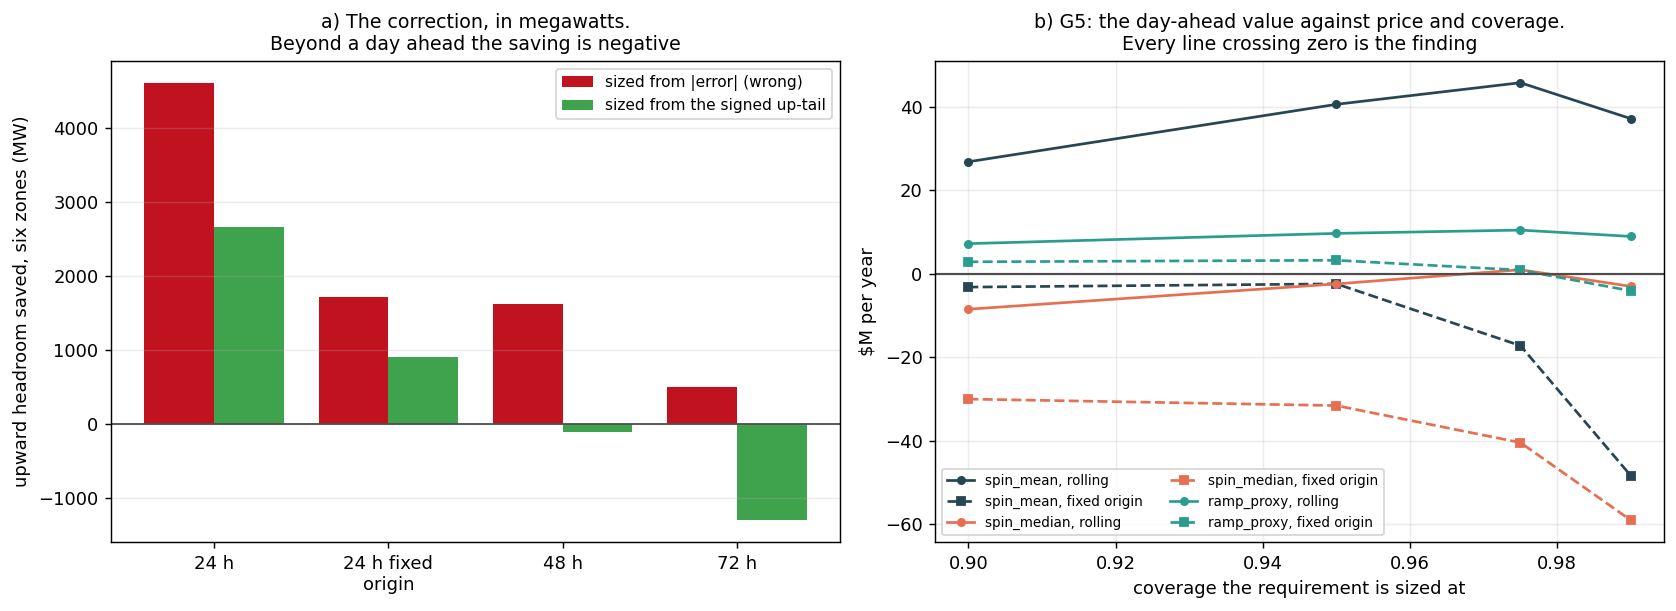

[results read-only] nb08: 7 key(s) verified against the ledger, nothing written


In [21]:
# WHAT: the reserve valuation, in MW and in dollars, with its sensitivity surface.
# WHY:  G5. And because the first version of this table was wrong in four ways that the
#       output cannot reveal on its own, so the wrong quantity is computed next to the
#       right one.
# NOTE: every number here comes from `src.reserve`, which `scripts/horizon_reserve.py`
#       also calls to write reports/HORIZON_RESULTS.md. One implementation, so the
#       notebook and the report cannot disagree. The guard below refuses to continue if
#       the rebuilt benchmark does not reproduce notebook 04's own per-horizon MAEs.

from src import reserve as RS

panel = pd.read_parquet(cfg.PANEL)
prices = pd.read_parquet(cfg.DATA_PROC / "ancillary_prices.parquet")

frames, guard = RS.build_scored_frames(panel, s4["cut"], preds)
RS.check_against_ledger(guard, s4["per_horizon_skill"])
print(f"guard passed: the rebuilt benchmark reproduces notebook 04's per-horizon MAEs "
      f"to 0.01 MW on all {len(RS.HORIZONS)} horizons")

res = RS.horizon_table(frames, prices).set_index("horizon")
byzone = RS.zone_table(frames, prices)
surface = RS.sensitivity_surface(frames, prices)

print("\n--- MAE and skill by horizon, and the fixed-origin re-score ---")
display(res[["rows", "mae_model", "mae_v1", "mae_v2", "mae_naive168",
             "skill_vs_v1", "skill_vs_v2", "skill_vs_naive"]].round(
    {"mae_model": 1, "mae_v1": 1, "mae_v2": 1, "mae_naive168": 1,
     "skill_vs_v1": 4, "skill_vs_v2": 4, "skill_vs_naive": 4}))
print(f"at h=1 the information-matched benchmark is t-1 persistence: model "
      f"{res.loc['1', 'mae_model']:,.1f} MW against {res.loc['1', 'mae_persist1']:,.1f} MW, "
      f"skill {res.loc['1', 'skill_vs_persist1']:+.1%} -- not the "
      f"{res.loc['1', 'skill_vs_v2']:+.1%} against a day-ahead composite")

print("\n--- upward reserve headroom, signed, against the same quantity sized from |error| ---")
display(res[["reserve_benchmark", "pooled_p95_up_model", "sum_zone_p95_up_model",
             "sum_zone_p95_up_bench", "up_saved_MW", "down_saved_MW",
             "abs_saved_MW"]].round(0))
_signed, _abs = res.loc["24", "up_saved_MW"], res.loc["24", "abs_saved_MW"]
print(f"THE CORRECTION at h=24: {_abs:,.0f} MW sized from |error| becomes "
      f"{_signed:,.0f} MW sized from the tail upward reserve actually covers "
      f"({_signed / _abs - 1:+.0%}), and at 48 h and 72 h the saving turns NEGATIVE.")
print(f"fixed-origin, the like-for-like day-ahead comparison: "
      f"{res.loc[RS.FIXED_ORIGIN, 'up_saved_MW']:,.0f} MW")

print("\n--- G5: the price x coverage surface, $M/year ---")
piv = (surface.pivot_table(index=["horizon", "coverage"], columns="price_scenario",
                           values="usd_per_year") / 1e6)
display(piv.loc[["24", RS.FIXED_ORIGIN, "48", "72"]].round(1))
_day = piv.loc[[("24", 0.95), (RS.FIXED_ORIGIN, 0.95)]].to_numpy()
print(f"at p95 the day-ahead figure spans {_day.min():+,.1f} to {_day.max():+,.1f} $M/yr: "
      f"the sign is not robust to the issuance convention or to the price instrument, "
      f"which is what G5 exists to expose.")

print("\n--- per zone, upward headroom saved (MW, p95 of signed error) ---")
display(byzone.pivot_table(index="zone", columns="horizon", values="up_saved")
        [["1", "24", RS.FIXED_ORIGIN, "48", "72"]].round(0))

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))
ax = axes[0]
keys = ["24", RS.FIXED_ORIGIN, "48", "72"]
xs = np.arange(len(keys))
ax.bar(xs - 0.2, [res.loc[k, "abs_saved_MW"] for k in keys], 0.4,
       label="sized from |error| (wrong)", color="#c1121f")
ax.bar(xs + 0.2, [res.loc[k, "up_saved_MW"] for k in keys], 0.4,
       label="sized from the signed up-tail", color="#3fa34d")
ax.axhline(0, color="0.3", lw=1)
ax.set_xticks(xs); ax.set_xticklabels(["24 h", "24 h fixed\norigin", "48 h", "72 h"])
ax.set_ylabel("upward headroom saved, six zones (MW)")
ax.set_title("a) The correction, in megawatts.\nBeyond a day ahead the saving is negative",
             fontsize=10.5)
ax.legend(fontsize=8.5); ax.grid(alpha=0.25, axis="y")

ax = axes[1]
for scen, colour in (("spin_mean", "#264653"), ("spin_median", "#e76f51"),
                     ("ramp_proxy", "#2a9d8f")):
    for k, style in (("24", "-o"), (RS.FIXED_ORIGIN, "--s")):
        d = surface[(surface.horizon == k) & (surface.price_scenario == scen)]
        ax.plot(d["coverage"], d["usd_per_year"] / 1e6, style, color=colour, ms=4,
                label=f"{scen}, {'rolling' if k == '24' else 'fixed origin'}")
ax.axhline(0, color="0.3", lw=1.2)
ax.set_xlabel("coverage the requirement is sized at")
ax.set_ylabel("$M per year")
ax.set_title("b) G5: the day-ahead value against price and coverage.\n"
             "Every line crossing zero is the finding", fontsize=10.5)
ax.legend(fontsize=7.5, ncol=2); ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(cfg.FIGURES / "08_reserve_valuation.png", bbox_inches="tight")
plt.show()

R.save("nb08", {
    "reserve_by_horizon": res.reset_index().replace({np.nan: None}).to_dict("records"),
    "reserve_by_zone": byzone.replace({np.nan: None}).to_dict("records"),
    "reserve_sensitivity_surface": surface.replace({np.nan: None}).to_dict("records"),
    "reserve_correction_mw": {
        "h24_sized_from_abs_error": float(_abs),
        "h24_sized_from_signed_up_tail": float(_signed),
        "h24_fixed_origin_signed": float(res.loc[RS.FIXED_ORIGIN, "up_saved_MW"]),
        "h24_downward_saving_not_priced": float(res.loc["24", "down_saved_MW"])},
    "reserve_value_day_ahead_usd_m_p95_range": [float(_day.min()), float(_day.max())],
    "reserve_price_is_a_proxy": ("spinning reserve is a contingency product sized from "
                                 "the largest single credible outage, not from forecast "
                                 "error; every dollar figure is an upper bound"),
    "g5_sensitivity_surface_reported": True,
});


**Figure: `08_reserve_valuation.png`.** (a) Headroom saved, sized from |error| (red) and from the signed tail (green), at four horizons. (b) The G5 surface at day-ahead.

At h=24 the saving falls from **4,620 MW** to **2,672 MW** once the tail is signed (a 42% cut), and at 48 and 72 hours it is **negative**. From a single issue time it is **898 MW**. At p95 the day-ahead value spans **−$32 M to +$41 M a year** across price scenarios and scoring conventions. The gain is concentrated in CISO (3,118 MW, more than the six-zone total), while MISO is a 1,060 MW loss. This is the weakest claim in the project: the honest result is a range that spans zero. It is the headroom a party with **only public data** would stop carrying, not a gap to operators, who have their own forecasts.

### 8.6c — The conditional band against a flat quantile, at equal risk

The reserve requirement from notebook 06's calibrated conditional band, compared with a flat per-zone p95 on all 47,299 day-ahead holdout rows. To compare fairly, each zone's band is scaled (by bisection) until its shortfall rate is exactly 5%, the same as a p95 rule. The totals answer "is it cheaper?"; the by-regime and by-hour tables answer "is it better?".

--- flat p95 against the conditional band, 47,299 day-ahead zone-hours, both held to a 5% shortfall rate ---


,flat_p95_MW,conditional_mean_MW,conditional_min_MW,conditional_max_MW,scale,shortfall_flat,shortfall_conditional
zone,,,,,,,
BPAT,"1,036.000",991.000,0.000,"12,968.000",1.001,0.050,0.050
CISO,"2,482.000","2,784.000",98.000,"8,643.000",0.922,0.050,0.050
ERCO,"7,319.000","7,810.000",589.000,"20,912.000",0.939,0.050,0.050
MISO,"6,672.000","6,677.000",0.000,"15,859.000",0.926,0.050,0.050
NYIS,"1,330.000","1,350.000",0.000,"15,143.000",0.911,0.050,0.050
SWPP,"5,181.000","5,289.000","1,236.000","10,591.000",0.827,0.050,0.050


six zones: flat 24,021 MW held every hour, conditional 24,901 MW on average -> +880 MW
   -> A NULL, and slightly the wrong way. Conditioning does not shrink the requirement; it moves it. So 8.6b is not understating the case by using a flat quantile.

--- but a flat rule is right on average and right nowhere in particular ---


,rows,shortfall_flat,shortfall_conditional,mean_req_flat,mean_req_conditional
regime,,,,,
DUCK,14434,0.044,0.044,"4,126.000","4,516.000"
conventional,25063,0.053,0.055,"4,140.000","4,132.000"
unlabelled,407,0.192,0.174,"4,222.000","5,315.000"
winter-shaped,7395,0.045,0.039,"3,283.000","3,427.000"


--- shortfall by regime and time of day: evening ramp, solar belly, overnight ---


,regime,hours,rows,shortfall_flat,shortfall_conditional
0,DUCK,16-20,3010,0.058,0.041
1,DUCK,12-14,1803,0.018,0.007
2,DUCK,00-05,3608,0.048,0.061
3,conventional,16-20,5222,0.083,0.069
4,conventional,12-14,3132,0.053,0.061
5,conventional,00-05,6266,0.030,0.043
6,unlabelled,16-20,71,0.211,0.211
7,unlabelled,12-14,57,0.175,0.140
8,unlabelled,00-05,109,0.202,0.165
9,winter-shaped,16-20,1549,0.026,0.020


across 16:00-20:00 local a flat p95 is short up to 8.3% of the time (conventional days) against its nominal 5%, while the conditional band, held to the same 5% shortfall rate overall, is short 6.9% there
   the 71 unlabelled evening hours are short 21.1% under either rule (21.1% conditional) -- a data gap, not a regime, and the argument for abstention
   -> the value of the uncertainty arm is RISK ALLOCATION, not a dollar saving, and the evening ramp is the hour it buys


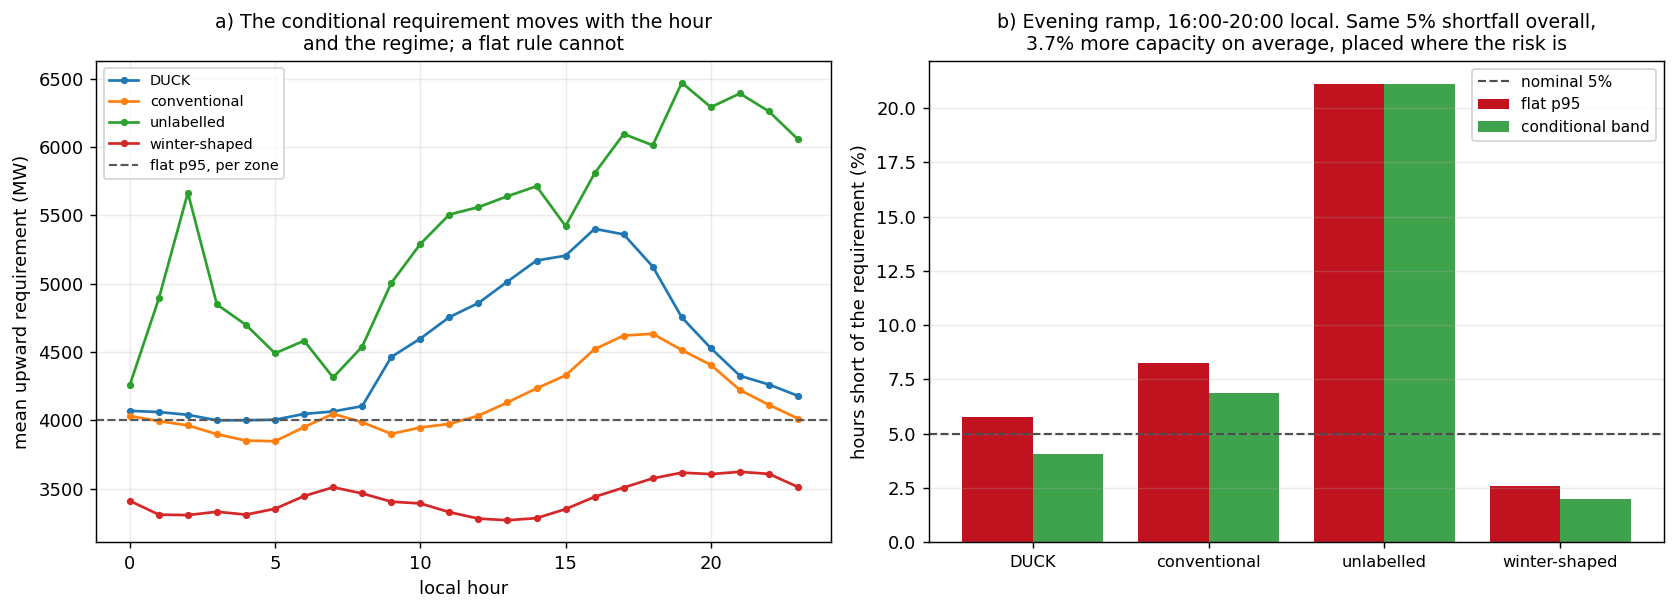

[results read-only] nb08: 5 key(s) verified against the ledger, nothing written


In [22]:
# WHAT: flat p95 against the calibrated conditional band, at an equal 5% shortfall rate,
#       and where each of them is actually short.
# WHY:  the proposal promised reserve from the conditional distribution; 8.6b uses a flat
#       quantile. Unless the two are compared the uncertainty arm has no downstream claim.
# NOTE: same module as 8.6b, and the same one `scripts/conditional_reserve.py` calls.

quantiles = pd.read_parquet(cfg.DATA_PROC / "holdout_quantiles.parquet")
labels_df = pd.read_parquet(cfg.DATA_PROC / "unsupervised" / "cluster_labels.parquet")

hourly = RS.hourly_with_band(preds, quantiles, labels_df, s5["regime_names"])
cmp_zone = RS.equal_risk_comparison(hourly)
by_regime, by_cell = RS.risk_concentration(hourly, cmp_zone)

print(f"--- flat p95 against the conditional band, {len(hourly):,} day-ahead zone-hours, "
      f"both held to a {RS.TARGET_SHORTFALL:.0%} shortfall rate ---")
display(cmp_zone[["flat_p95_MW", "conditional_mean_MW", "conditional_min_MW",
                  "conditional_max_MW", "scale", "shortfall_flat",
                  "shortfall_conditional"]].round(
    {"flat_p95_MW": 0, "conditional_mean_MW": 0, "conditional_min_MW": 0,
     "conditional_max_MW": 0, "scale": 3, "shortfall_flat": 4,
     "shortfall_conditional": 4}))
_flat, _cond = cmp_zone["flat_p95_MW"].sum(), cmp_zone["conditional_mean_MW"].sum()
print(f"six zones: flat {_flat:,.0f} MW held every hour, conditional {_cond:,.0f} MW on "
      f"average -> {_cond - _flat:+,.0f} MW")
print("   -> " + ("A NULL, and slightly the wrong way. Conditioning does not shrink the "
                  "requirement; it moves it. So 8.6b is not understating the case by "
                  "using a flat quantile." if _cond >= _flat else
                  "the conditional band is cheaper at equal risk, and 8.6b understates "
                  "the value of the uncertainty arm."))

print("\n--- but a flat rule is right on average and right nowhere in particular ---")
display(by_regime.round({"rows": 0, "shortfall_flat": 4, "shortfall_conditional": 4,
                         "mean_req_flat": 0, "mean_req_conditional": 0}))

# `window_shortfall` raises on an empty window rather than returning a silent zero, so
# thin regimes (the 363 unlabelled hours) are skipped explicitly instead of taking the
# notebook down on a future run that happens to have none in some hour.
_rows = []
for rg in sorted(by_cell["regime"].unique()):
    for lo, hi in ((16, 20), (12, 14), (0, 5)):
        try:
            _rows.append(RS.window_shortfall(by_cell, rg, lo, hi))
        except ValueError:
            print(f"   (no {rg} hours in {lo:02d}-{hi:02d} local; skipped)")
windows = pd.DataFrame(_rows)
print("--- shortfall by regime and time of day: evening ramp, solar belly, overnight ---")
display(windows.round({"shortfall_flat": 4, "shortfall_conditional": 4}))
# The headline excludes `unlabelled`: those 363 hours are short far more often than any
# regime, but they are hours the clustering gave no shape to, so quoting them as the
# worst regime would attribute a data gap to the duck curve. They get their own line.
_ev = windows[windows.hours == "16-20"]
_ev_named = _ev[_ev.regime != "unlabelled"]
_worst = _ev_named.loc[_ev_named["shortfall_flat"].idxmax()]
print(f"across 16:00-20:00 local a flat p95 is short up to "
      f"{_worst['shortfall_flat']:.1%} of the time ({_worst['regime']} days) against its "
      f"nominal {RS.TARGET_SHORTFALL:.0%}, while the conditional band, held to the same "
      f"{RS.TARGET_SHORTFALL:.0%} shortfall rate overall, is short {_worst['shortfall_conditional']:.1%} there")
if (_ev.regime == "unlabelled").any():
    _u = _ev[_ev.regime == "unlabelled"].iloc[0]
    print(f"   the {_u['rows']:,} unlabelled evening hours are short "
          f"{_u['shortfall_flat']:.1%} under either rule ({_u['shortfall_conditional']:.1%} "
          f"conditional) -- a data gap, not a regime, and the argument for abstention")
print("   -> the value of the uncertainty arm is RISK ALLOCATION, not a dollar saving, "
      "and the evening ramp is the hour it buys")

fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.8))
ax = axes[0]
piv = by_cell.pivot_table(index="local_hour", columns="regime",
                          values="mean_req_conditional")
for rg in piv.columns:
    ax.plot(piv.index, piv[rg], "-o", ms=3, label=rg)
ax.axhline(cmp_zone["flat_p95_MW"].mean(), color="0.35", ls="--", lw=1.2,
           label="flat p95, per zone")
ax.set_xlabel("local hour"); ax.set_ylabel("mean upward requirement (MW)")
ax.set_title("a) The conditional requirement moves with the hour\nand the regime; "
             "a flat rule cannot", fontsize=10.5)
ax.legend(fontsize=8); ax.grid(alpha=0.25)

ax = axes[1]
xs = np.arange(len(_ev))
ax.bar(xs - 0.2, _ev["shortfall_flat"] * 100, 0.4, label="flat p95", color="#c1121f")
ax.bar(xs + 0.2, _ev["shortfall_conditional"] * 100, 0.4, label="conditional band",
       color="#3fa34d")
ax.axhline(RS.TARGET_SHORTFALL * 100, color="0.3", ls="--", lw=1.2,
           label="nominal 5%")
ax.set_xticks(xs); ax.set_xticklabels(_ev["regime"], fontsize=9)
ax.set_ylabel("hours short of the requirement (%)")
_extra = _cond / _flat - 1
ax.set_title(f"b) Evening ramp, 16:00-20:00 local. Same {RS.TARGET_SHORTFALL:.0%} shortfall overall,\n"
             f"{_extra:.1%} more capacity on average, placed where the risk is",
             fontsize=10.5)
ax.legend(fontsize=8.5); ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.savefig(cfg.FIGURES / "08_conditional_reserve.png", bbox_inches="tight")
plt.show()

R.save("nb08", {
    "conditional_reserve_by_zone": cmp_zone.reset_index().replace(
        {np.nan: None}).to_dict("records"),
    "conditional_reserve_by_regime": by_regime.reset_index().replace(
        {np.nan: None}).to_dict("records"),
    "conditional_reserve_windows": windows.replace({np.nan: None}).to_dict("records"),
    "conditional_vs_flat_mw": {"flat_p95_six_zones": float(_flat),
                               "conditional_at_equal_risk": float(_cond),
                               "difference": float(_cond - _flat),
                               "conditioning_is_cheaper": bool(_cond < _flat),
                               "conditional_over_flat": float(_cond / _flat - 1)},
    "conditional_reserve_verdict": (f"a null on average and a real gain in the distribution: "
                                    f"{_cond / _flat - 1:.1%} more capacity at the same "
                                    f"{RS.TARGET_SHORTFALL:.0%} shortfall rate, placed where the "
                                    f"risk is, which is the evening ramp"),
});


**Figure: `08_conditional_reserve.png`.** (a) Mean upward requirement by local hour and regime against the flat p95; (b) shortfall rate over the evening ramp (16:00–20:00).

At equal risk the conditional band holds **24,901 MW** against the flat rule's **24,021 MW** — **880 MW more**, not less, so 8.6b's flat quantile does not understate the model's value. But the flat rule's misses cluster: over the evening ramp it is short **8.3%** of the time on conventional days and **5.8%** on duck days, against **6.9%** and **4.1%** for the conditional band. It pays with more misses overnight and at conventional middays. So the uncertainty arm buys not less capacity but, for 3.7% more, capacity in the right hours — the evening ramp on a high-solar day. I report it as a risk-allocation result, not a saving.

### 8.7 — Explainability: do two attribution methods agree?

The top ten features by permutation importance and by mean |SHAP|, and family shares by horizon. They agree closely (Spearman **0.948** on rank): both put `net_load_lag24` first, then `demand_lag24`. SHAP ranks `wind_speed_100m` and `apparent_temp` higher than permutation: they move individual predictions more than accuracy depends on them.

,permutation_mw,mean_abs_shap_mw,perm_rank,shap_rank
net_load_lag24,"8,983","8,858",1,1
demand_lag24,"3,598","4,791",2,2
zone_is_MISO,798,685,3,7
wind_lag24,547,722,4,5
net_load_lag168,532,985,5,4
wind_speed_100m,522,"1,004",6,3
net_load_lag48,353,711,7,6
net_load_roll24_mean,330,-,8,-
solar_lag24,194,405,9,10
apparent_temp,187,513,10,8


,calendar,exogenous,lag,rolling,weather,zone
horizon,,,,,,
1,2.6%,1.7%,93.9%,0.8%,0.9%,0.2%
24,2.1%,23.4%,59.3%,2.0%,7.4%,5.8%
48,3.2%,34.0%,42.9%,1.9%,9.0%,9.0%
72,3.8%,33.1%,39.9%,2.1%,10.3%,10.8%


PDP vs ALE on temperature: {'ale_range_mw': 1460.2854752661842, 'feature': 'temp', 'max_gap_mw': 121.7309728133825, 'pdp_range_mw': 1415.6601241912126}


**Figure `07_shap.png`** — global SHAP, the beeswarm, and the ten largest contributions to the single worst hour.

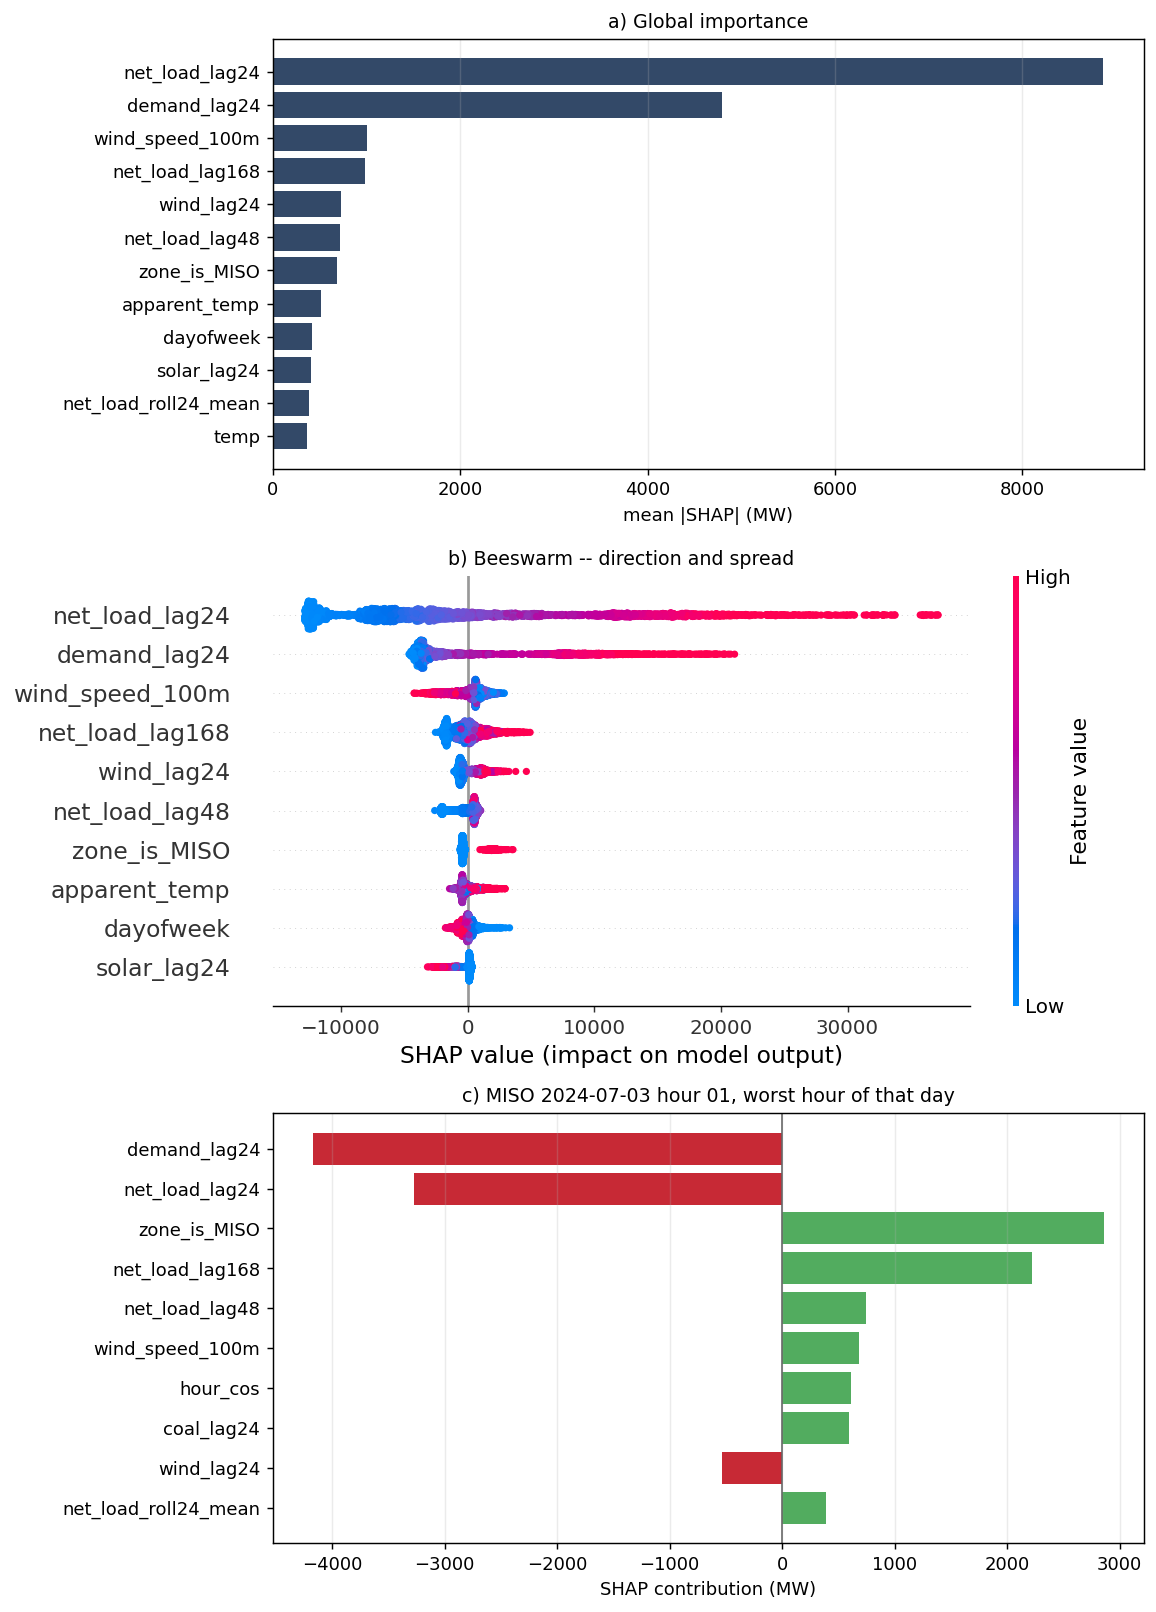

**Figure `07_permutation.png`** — permutation importance, single and grouped by family.

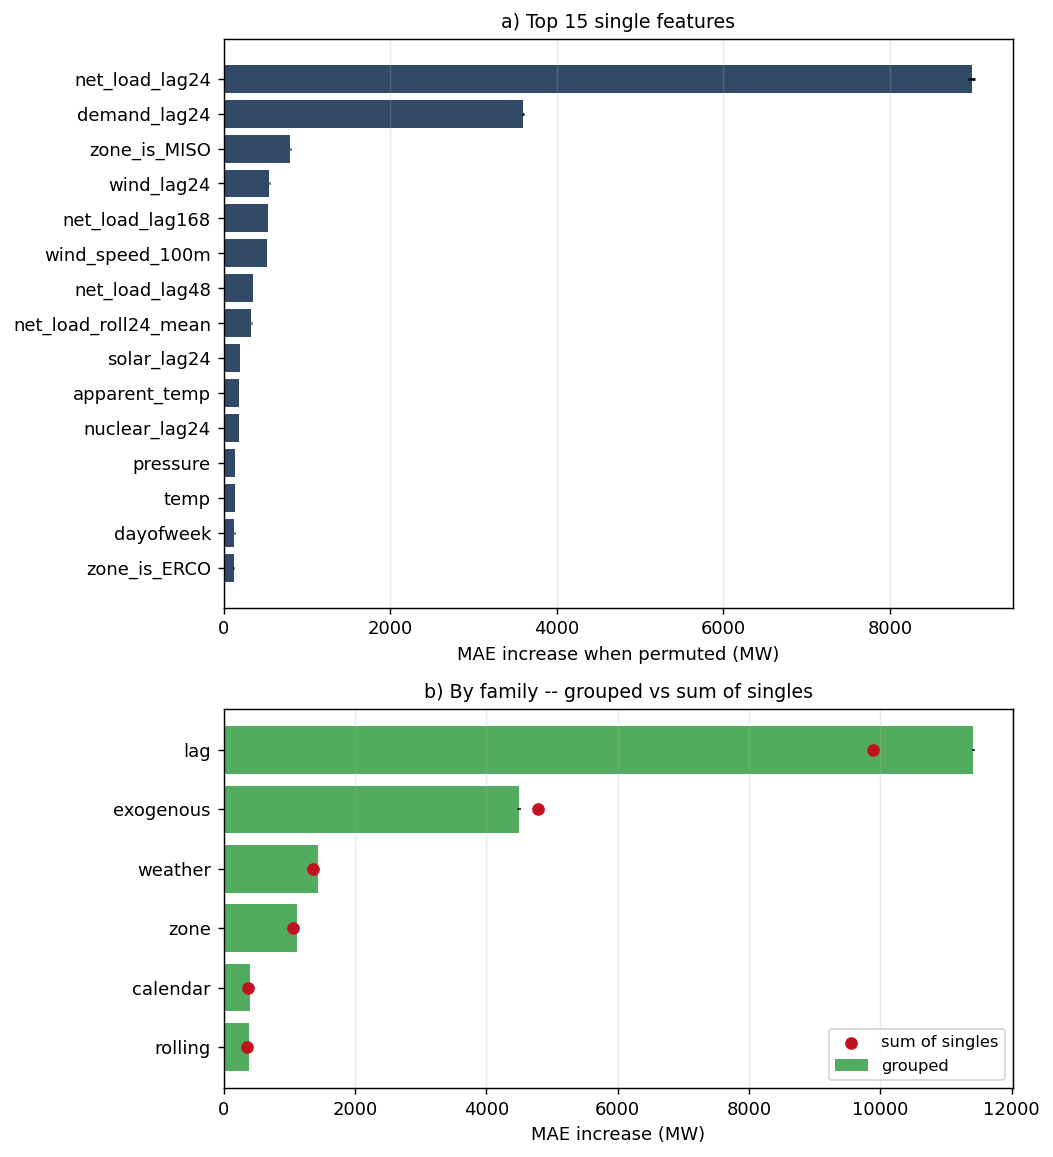

In [23]:
top = pd.DataFrame({"permutation_mw": pd.Series(s7["permutation_top10"]), "mean_abs_shap_mw": pd.Series(s7["shap_top10"])})
top["perm_rank"] = top.permutation_mw.rank(ascending=False).astype("Int64")
top["shap_rank"] = top.mean_abs_shap_mw.rank(ascending=False).astype("Int64")
display(top.sort_values("permutation_mw", ascending=False).style.format({"permutation_mw": "{:,.0f}", "mean_abs_shap_mw": "{:,.0f}"}, na_rep="-"))
sh = pd.DataFrame(s7["importance_by_horizon"]["share"]).T
sh.index.name = "horizon"
display(sh.style.format("{:.1%}"))
print("PDP vs ALE on temperature:", s7["pdp_vs_ale"])
show("07_shap", "global SHAP, the beeswarm, and the ten largest contributions to the single worst hour.")
show("07_permutation", "permutation importance, single and grouped by family.")

### 8.8 — Trade-offs, quantified

| Trade-off | One side | Other side | Ledger key |
|---|---|---|---|
| **Accuracy vs compute** | random forest: 2,237 MW in **249.7 s** per CV | HGB: 2,173 MW in **14.5 s** | `nb04.ladder` |
| **Accuracy vs interpretability** | ridge: coefficients unreadable (infinite VIF on **12** columns) | boosting 525 MW better in CV, explained post hoc | `nb02.vif_infinite`, `nb07` |
| **Horizon vs accuracy** | h = 1: **547 MW** | h = 24 / 48 / 72: 2,160 / 2,390 / 2,471 MW | `nb04.horizon_sweep` |
| **Features vs accuracy** | `select__k = 8`: 2,898 MW | `select__k = all`: 2,107 MW | `nb04.hyperparam_sensitivity` |
| **Training rows vs accuracy** | 10% (22,800 rows): 3,857 MW | 100% (227,962 rows): 2,102 MW; last step 3.7 MW | `nb04.learning_curve` |
| **Coverage vs width** | raw quantiles: 80.4% at 7,135 MW | CQR-Mondrian: 88.7% at 8,709 MW | `nb06.interval_comparison` |
| **Precision vs recall** | threshold 0.5: F1 0.628 | threshold 0.26 (dev block): F1 0.674; PR-AUC 0.772 | `nb04.classification` |
| **Leak-proof vs optimistic CV** | windows ending at the origin: 2,173 MW | windows ending at the target: 1,875 MW (298 MW of optimism) | `nb04.rolling_leak` |
| **Separation vs stability** | Ward k = 3: silhouette 0.357, ARI 0.617 | k-means k = 3: 0.429, ARI **0.996** — k-means wins both | `nb05.grid` |

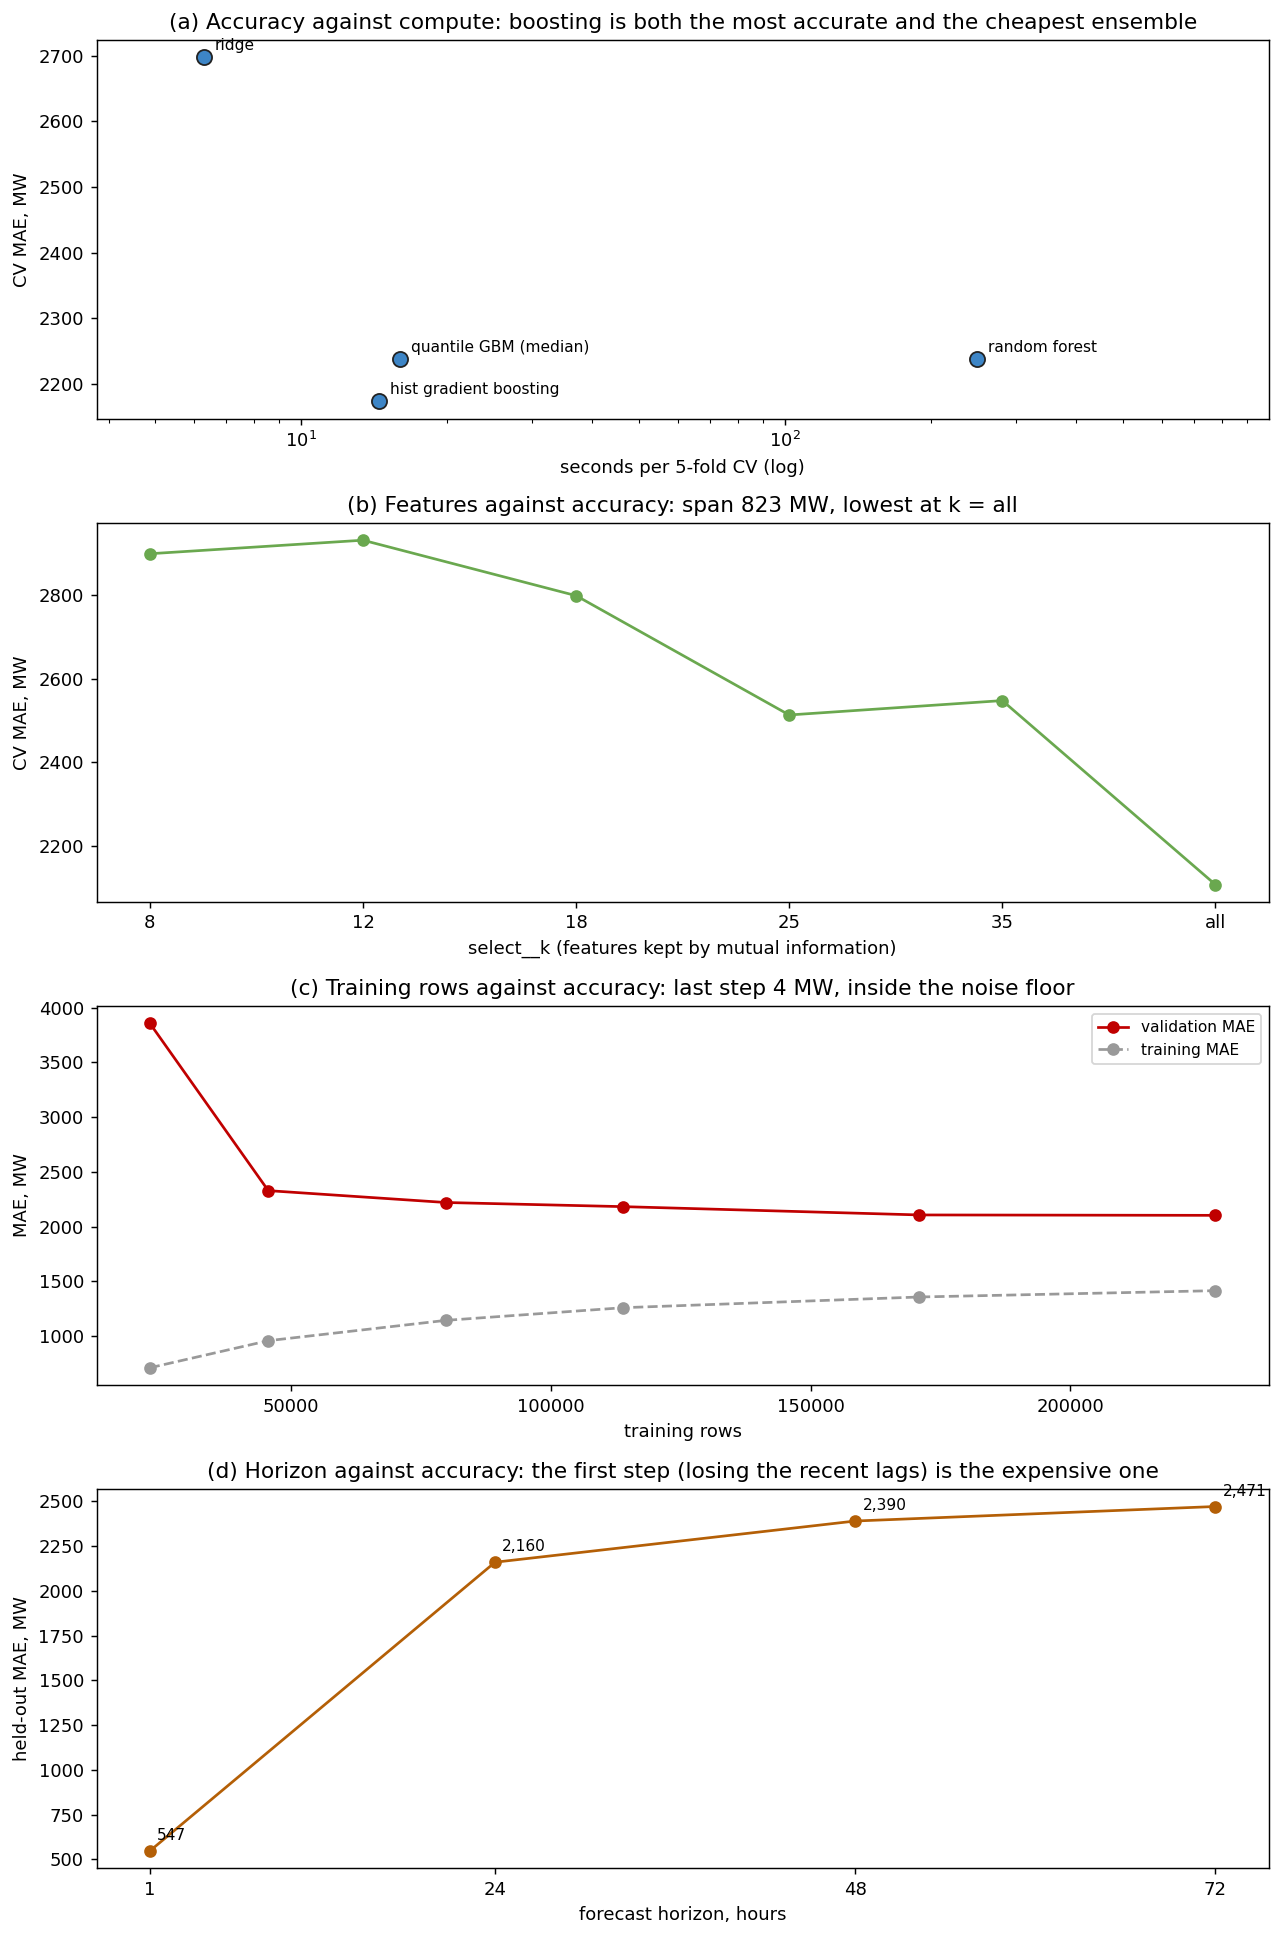

In [24]:
fig, axs = plt.subplots(4, 1, figsize=(10, 15))
# (a) accuracy vs compute
lad = fam.dropna(subset=["fit_seconds"]).dropna(subset=["cv_mae_mean"])
axs[0].scatter(lad.fit_seconds.clip(lower=1), lad.cv_mae_mean, s=70, color="#3d85c6", edgecolor="#222", zorder=3)
for _, row in lad.iterrows():
    axs[0].annotate(row.family, (max(row.fit_seconds, 1), row.cv_mae_mean), textcoords="offset points", xytext=(6, 4), fontsize=8.5)
axs[0].set_xscale("log"); axs[0].set_xlabel("seconds per 5-fold CV (log)"); axs[0].set_ylabel("CV MAE, MW")
axs[0].set_xlim(lad.fit_seconds.clip(lower=1).min() * 0.6, lad.fit_seconds.max() * 4)
axs[0].set_title("(a) Accuracy against compute: boosting is both the most accurate and the cheapest ensemble")
# (b) features vs accuracy
ka = s4["hyperparam_sensitivity"]["axes"]["select__k"]
axs[1].plot(range(len(ka["values"])), ka["mae"], marker="o", color="#6aa84f")
axs[1].set_xticks(range(len(ka["values"]))); axs[1].set_xticklabels(ka["values"]); axs[1].set_xlabel("select__k (features kept by mutual information)")
axs[1].set_ylabel("CV MAE, MW"); axs[1].set_title(f"(b) Features against accuracy: span {ka['range_mw']:,.0f} MW, "
                 f"lowest at k = {ka['values'][int(np.argmin(ka['mae']))]}")
# (c) training rows vs accuracy
lcr = pd.DataFrame(s4["learning_curve"]["rows"])
axs[2].plot(lcr.n_rows, lcr.valid_mae, marker="o", color="#c00000", label="validation MAE")
axs[2].plot(lcr.n_rows, lcr.train_mae, marker="o", color="#999", ls="--", label="training MAE")
axs[2].set_xlabel("training rows"); axs[2].set_ylabel("MAE, MW"); axs[2].legend(fontsize=8.5)
axs[2].set_title(f"(c) Training rows against accuracy: last step {s4['learning_curve']['last_step_mw']:.0f} MW, inside the noise floor")
# (d) horizon vs accuracy
hs = pd.Series({int(k): v for k, v in s4["horizon_sweep"]["by_horizon_scale0"].items()}).sort_index()
axs[3].plot(hs.index, hs.values, marker="o", color="#b45f06")
for h_, v in hs.items():
    axs[3].annotate(f"{v:,.0f}", (h_, v), textcoords="offset points", xytext=(4, 6), fontsize=8.5)
axs[3].set_xticks(hs.index); axs[3].set_xlabel("forecast horizon, hours"); axs[3].set_ylabel("held-out MAE, MW")
axs[3].set_title("(d) Horizon against accuracy: the first step (losing the recent lags) is the expensive one")
fig.tight_layout()
fig.savefig(cfg.FIGURES / "08_tradeoffs.png", bbox_inches="tight")
plt.show()

**Figure: `08_tradeoffs.png` — four trade-offs as curves.** (a) HGB is 17× cheaper than the random forest *and* 64 MW better, so there is no accuracy–compute frontier. (b) Error is lowest with all features (2,107 vs 2,898 MW at k = 8), though not monotonically. (c) Validation error flattens; training error rises, so the model is not memorising. (d) 84% of the degradation from h = 1 to h = 72 happens in the first step. The real trade-offs are representational and operational, not model choice; neither more features nor more years is the next improvement, a better representation of the afternoon and the wind corridor is (8.4h).

### 8.9 — Options considered, and why each choice was made

| Decision | Options | Chosen | Reason |
|---|---|---|---|
| Target | demand minus renewables; net load directly | **net load directly** | realised wind and solar are unknown at the origin; subtracting forecasts loses the error covariance |
| Cross-validation | k-fold; `TimeSeriesSplit`; panel-aware split | **`PanelTimeSeriesSplit`**, 191-h gap at h = 24 | row-based splits count rows, not hours, on a panel |
| Lags | `shift(L)`; timestamp lookup | **timestamp lookup** | after an outage, 24 rows is not 24 hours |
| Feature selection | mutual-information trim; keep all | **keep all** | no subset matched all features (2,898 → 2,107 MW from 8 to all) |
| Model families | linear; bagging; boosting; quantile boosting; sequence models | **the first four**, HGB champion | sequence models unlikely to beat tuned boosting on six zones, and harder to explain |
| Search | full grid; random; two-stage | **two-stage** (40 + 9) | the full grid would be 72,000 cells; the grid stage bought 4.1 MW |
| Metric | RMSE; MAPE; MAE | **MAE**, p95 beside it | MAPE explodes near zero net load; MAE is in the unit reserve is bought in |
| Reserve quantile | pooled \|error\|; per-zone \|error\|; per-zone signed | **per-zone signed, summed** | upward reserve covers under-forecasts only; 2,672 MW vs 4,620 MW from \|error\| |
| Clustering representation | raw MW; normalised shapes; PCA of shapes | **PCA of shapes** (5 PCs, 94.8%) | raw profiles just separate big and small zones |
| Clustering algorithm | k-means, Ward, DBSCAN; k = 3…7 | **k-means, k = 3** | all four metrics pick k = 3; most stable (ARI 0.996) |
| Interval method | raw; split conformal; CQR; per-level shifts | **CQR, Mondrian by zone** | Winkler 11,545; finite-sample guarantee |
| Causal claim | assert; DiD; matching; withhold | **withhold** | three designs give 582 MW/pp, 2,084 MW and 7,180 MW; the treatment is solar *output*, not capacity |

### 8.10 — Summary of findings

**Supervised.** Hourly net load in six US balancing authorities can be forecast a day ahead from public data with a held-out MAE of **2,139.7 MW** on the **46,123** common hours (**2,159.6 MW** on all 47,299): **49.8%** better than seasonal naive, **30.1%** better than EIA's published day-ahead composite, and **13.9%** better than the weather-driven composite. From a single day-ahead issue time the error is **2,296.9 MW** and the skills are **+24.9%** and **+7.6%**. Errors are largest at 16:00 local, in the wind-heavy zone, and where data has gaps.

**Unsupervised.** Daily shapes fall into **3** regimes — conventional (59.5%), the duck (21.4%) and a cold winter-shaped day (19.1%) — from k-means on 5 PCs, stable under resampling (ARI **0.996**). It is a **stable partition of a continuum**. The winter regime is colder than its own zone's mean in all five zones that can be tested; the duck's sunny signature is mostly geography (**77% of duck days are CISO's**). As a feature, yesterday's label is worth **17.4 MW**, under 1% (p = 0.030).

**Uncertainty and valuation.** Per-zone CQR brings every zone inside ±5 points (**88.7%** pooled), but the median drifts. The day-ahead reserve saving is **2,672 MW**, worth **−$32 M to +$41 M a year** at p95 — a range that spans zero.

| Goal | Target | Measured | Result |
|---|---|---|---|
| G1 beat seasonal naive | skill ≥ 25% | **49.8%** | pass |
| **G2 beat the EIA day-ahead composite** | skill > 0 | **30.1%** | **pass** |
| G2′ beat the weather-driven composite | skill > 0 | **13.9%** | pass |
| G3 calibrated 90% intervals | within ±5 pts | **88.7%**, every zone inside ±5; **CISO at h=1 80.8%**; median 0.538 | per-zone pass; per-cell **fail**; median **fail** |
| G4 stable regimes | ARI ≥ 0.6 | **0.996** | pass |
| **G5 no cost without its surface** | price × coverage surface | 3 prices × 4 coverage levels × 5 horizons (8.6b) | **pass** |

Not delivered: a **cost-optimal quantile** (no price here measures the cost of being short) and a **per-regime interval-width optimisation** (per-regime coverage is in `nb06.coverage_by_regime`).

### 8.11 — What was learned, what surprised, and what to do with more time

**Part A.** Most of the difficulty was in measurement, not models: a rolling window ending at t − 1 instead of at the origin flattered every horizon above h = 1 by up to 28%, and same-hour fuel columns reconstructed the target until notebook 02 removed them. With more time: rolling-origin evaluation, a second weather point per zone, an hour-aware loss, the `n_missing_lags` abstention rule, and a rolling calibration window.

**Part B.** Every internal metric agreed on k = 3, and the regime label buys the forecaster little (17 MW for yesterday's label). With more time: per-zone clustering and sequences of regimes instead of independent days.

### 8.12 — Ethical considerations

**Data.** EIA-930 (public domain) and Open-Meteo (CC-BY-4.0) are aggregate and non-personal, so privacy is not the concern.

**Deploying Part A.** Errors are asymmetric: an under-forecast on the evening ramp is a reliability risk, an over-forecast wastes money, and the error is largest in the afternoon. It should ship with its interval and an abstention rule. One weather point at a load-centre city makes the model less accurate for the rural wind corridor, which becomes a fairness issue if the forecast drives where reserve costs fall. The median already drifts, and the model has never been scored on a winter storm.

**Deploying Part B.** Regime labels are descriptive. Reading "duck days are sunnier" as "solar causes the duck" is wrong here: 77% of duck days are CISO's, and in four of the other five zones duck days are dimmer than usual. Any operational use should state the surrogate tree's balanced accuracy, and the regimes should be re-fitted as the fleet grows.

### 8.13 — Statement of work

Alan Mossinger, Eric Londo and Eran Abeysekera wrote the code and ran the analysis together; Erik Lang mentored the project.

| Name | Focus |
|---|---|
| **Eran Abeysekera** | Data acquisition and cleaning, the feature pipeline and its leakage audits, the causal analysis. |
| **Eric Londo** | Supervised modelling, tuning and evaluation. |
| **Alan Mossinger** | Unsupervised modelling, uncertainty calibration and explainability. |
| **Erik Lang** | Mentor. |

The team wrote the report and prepared the GitHub structure together.

### 8.14 — References

- U.S. Energy Information Administration. *Hourly Electric Grid Monitor (EIA-930)* and the EIA Open Data API v2. https://www.eia.gov/electricity/gridmonitor/ · https://www.eia.gov/opendata/ (public domain).
- Open-Meteo. *Historical Weather API (ERA5 reanalysis, ECMWF)* and *Previous Runs API*. https://open-meteo.com/ (CC-BY-4.0). Hersbach, H. et al. (2020). The ERA5 global reanalysis. *Quarterly Journal of the Royal Meteorological Society*, 146(730), 1999–2049.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Romano, Y., Patterson, E., & Candès, E. (2019). Conformalized Quantile Regression. *Advances in Neural Information Processing Systems*, 32.
- Chernozhukov, V., Fernández-Val, I., & Galichon, A. (2010). Quantile and probability curves without crossing. *Econometrica*, 78(3), 1093–1125.
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263.
- Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate. *Journal of the Royal Statistical Society B*, 57(1), 289–300.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems*, 30.
- Apley, D. W., & Zhu, J. (2020). Visualizing the effects of predictor variables in black box supervised learning models. *Journal of the Royal Statistical Society B*, 82(4), 1059–1086.
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Ke, G. et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems*, 30 (the histogram-based boosting design scikit-learn's estimator follows).
- Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65.
- Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification*, 2(1), 193–218.
- Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *KDD-96*, 226–231.
- Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association*, 58(301), 236–244.
- Rosenbaum, P. R. (2002). *Observational Studies* (2nd ed.). Springer. (Sensitivity analysis for matched designs.)
- Pearl, J. (2009). *Causality: Models, Reasoning, and Inference* (2nd ed.). Cambridge University Press. (Back-door adjustment and colliders.)
- Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association*, 102(477), 359–378. (The interval score used as the Winkler score.)
- Denholm, P., O'Connell, M., Brinkman, G., & Jorgenson, J. (2015). *Overgeneration from Solar Energy in California: A Field Guide to the Duck Chart*. NREL/TP-6A20-65023.

### 8.15 — Write the conclusions block to the ledger

Save the two summary tables and the trade-off list under `nb08`.

In [25]:
R.save("nb08", {
    "supervised_families": fam.replace({np.nan: None}).to_dict("records"),
    "unsupervised_best_by_algorithm": best_rows.replace({np.nan: None}).to_dict("records"),
    "importance_ablation_vs_permutation": imp.replace({np.nan: None}).to_dict("index"),
    "interval_methods": icd.replace({np.nan: None}).to_dict("index"),
    "failure_categories": ["operational: lags read from an imputed 24-h demand outage",
                           f"systematic: MAE peaks at local hour {s4['failure_analysis']['peak_error_local_hour']}",
                           "edge case: wind-corridor zone (SWPP) and the season absent from the holdout"],
    "figures": ["08_pipeline_overview", "08_supervised_summary", "08_ablation_vs_permutation",
                "08_failure_cases", "08_unsupervised_summary", "08_coverage_vs_width",
                "08_reserve_valuation", "08_conditional_reserve", "08_tradeoffs"],
})
print(R.summary())

[results read-only] nb08: 6 key(s) verified against the ledger, nothing written
nb00     2026-09-29T07:25:25+00:00  [artefact, disk_mb, duck_curve, end, forecast_weather, hours_in_window, panel_hash, price_markets_obtained, price_rows, price_status_by_zone, price_window, raw_columns, raw_rows, rows_per_zone, source, start, temp_coverage, weather, weather_by_year, zones]
nb01     2026-09-30T07:10:35+00:00  [chosen_lags, duplicate_rows_dropped, era5, fuel_mix, horizons, implausible_values_nulled, interp_limit_hours, lags_by_horizon, max_identity_residual, max_renewable_share, negative_generation_clipped, negative_net_load_hours, outlier_decision, outlier_extreme_ramp_rows, outlier_max_abs_ramp_mw, outlier_rule_flag_rates, outlier_shape, pacf_by_zone, pacf_mean_abs, pacf_segment_hours, pacf_zones_significant, predictions, rows_clean, rows_dropped, rows_raw, stationarity, target_association]
nb02     2026-09-29T07:34:33+00:00  [cv_mae_folds, cv_mae_mean, encoding_chosen, encoding_mae_folds

### 8.16 — Derived numbers used in the report

Ratios, differences and per-region figures (median 2024 day, generation mix, h=24 skill by region) that are not a single ledger value, computed here with `src/evaluation.py` and saved as `nb08.report_numbers`.

In [26]:
# WHAT: every number the final report quotes that is not a single ledger value -- the region
#       chapter, the ratios and differences it states in words, the hourly shape of the
#       conditional reserve requirement -- computed here from the ledger and the dataset,
#       printed, and written to the ledger as `nb08.report_numbers`.
# WHY:  rule 1 of the report: every number in it can be found and reproduced from the
#       notebooks and the data. Before this section some came only from a script
#       (scripts/region_chapter.py), some only from a figure, and some from a division the
#       reader had to do. The region numbers use the very functions the script uses
#       (src/evaluation.py), so the report, the script's CSV and this ledger block cannot differ.
from src.evaluation import duck_shape, per_zone_skill

_L = R.load()
_n0, _n4, _n6, _n7, _n8 = (_L[k] for k in ("nb00", "nb04", "nb06", "nb07", "nb08"))
rn = {}

# ------------------------------------------------------------------ the six regions (report §3, §7.9)
_panel = pd.read_parquet(cfg.PANEL)
_panel[cfg.TIME_COL] = pd.to_datetime(_panel[cfg.TIME_COL])
_shape, _profiles = duck_shape(_panel, _L)
_skill = per_zone_skill(_panel, _L)
_region = _shape.join(_skill)
_raw = pd.read_parquet(cfg.PANEL_RAW)
_FUELS = ["coal", "gas", "nuclear", "oil", "hydro", "wind", "solar", "other"]
_mix = _raw.groupby(cfg.GROUP_COL)[_FUELS].mean().fillna(0).clip(lower=0)   # notebook 00's pie rule
_region["mean_generation_2019_2024"] = _mix.sum(axis=1)
_region["wind_solar_pct_gen_2019_2024"] = 100 * (_mix["wind"] + _mix["solar"]) / _mix.sum(axis=1)
_region["mean_net_load_holdout"] = pd.Series({z: v["mean_load"] for z, v in _n4["holdout_by_zone"].items()})
_cols = ["mean_net_load_holdout", "mean_generation_2019_2024", "wind_solar_pct_gen_2019_2024",
         "trough_hour_local", "trough_index", "steepest_rise_3h_mw", "rise_end_hour",
         "midday_solar_share_of_demand", "wind_pct_gen_2024", "hydro_pct_gen_2024",
         "n_scored", "model_mae", "naive_mae", "df_composite_mae", "composite_v2_mae",
         "skill_vs_naive", "skill_vs_df_composite", "skill_vs_v2"]
print("--- the six regions: holdout size, 2019-2024 mix, the median 2024 day (local time),")
print("    and h=24 skill on the rows every benchmark can score ---")
display(_region[_cols].round(3))
rn["regions"] = {z: {c: (float(v) if not isinstance(v, str) else v) for c, v in r.items()}
                 for z, r in _region[_cols].iterrows()}
_net = _region["mean_net_load_holdout"]
_vre = _region["wind_solar_pct_gen_2019_2024"]
rn["size_ratio_largest_to_smallest"] = float(_net.max() / _net.min())
rn["vre_share_ratio_largest_to_smallest"] = float(_vre.max() / _vre.min())
_ciso = _profiles["CISO"]
_wedge = (_ciso["demand"] - _ciso["net_load"]) / _ciso["demand"]
rn["ciso_2024_wind_solar_share_of_demand_by_local_hour"] = {int(h): float(v) for h, v in _wedge.items()}
print(f"size: largest over smallest mean net load {rn['size_ratio_largest_to_smallest']:.1f}x "
      f"({_net.idxmax()} / {_net.idxmin()}); wind+solar share: largest over smallest "
      f"{rn['vre_share_ratio_largest_to_smallest']:.1f}x ({_vre.idxmax()} / {_vre.idxmin()})")
print("CISO median 2024 day, share of demand met by wind + solar, local 10:00-15:00: "
      + ", ".join(f"{h}h {100 * _wedge[h]:.1f}%" for h in range(10, 16)))
for _k, _lo, _hi in (("skill_vs_naive", None, None), ("skill_vs_df_composite", None, None),
                     ("skill_vs_v2", None, None)):
    _s = _region[_k]
    print(f"{_k:22s} from {100 * _s.min():+.1f}% ({_s.idxmin()}) to {100 * _s.max():+.1f}% ({_s.idxmax()}); "
          f"positive in {int((_s > 0).sum())} of 6")

# ------------------------------------------------------------------ duck-curve growth (report exec summary)
_p95 = _n0["duck_curve"]["evening_ramp_3h_p95_mw"]
_med = _n0["duck_curve"]["evening_ramp_3h_median_mw"]
rn["ciso_evening_ramp_growth_2019_2024"] = {"median": _med["2024"] / _med["2019"] - 1,
                                            "p95": _p95["2024"] / _p95["2019"] - 1}
print(f"\nCISO steepest evening 3-hour rise, 2019 -> 2024: median day "
      f"{100 * rn['ciso_evening_ramp_growth_2019_2024']['median']:+.1f}%, "
      f"p95 day {100 * rn['ciso_evening_ramp_growth_2019_2024']['p95']:+.1f}%")

# ------------------------------------------------------------------ the model ladder and its costs (§7.3)
_lad = _n4["ladder"]
_cv = {k: v["cv_mae_mean"] for k, v in _lad.items()}
_sec = {k: v.get("seconds") for k, v in _lad.items()}
rn["ladder"] = {
    "ridge_minus_forest_cv_mw": _cv["1  ridge"] - _cv["2  random forest"],
    "ridge_minus_boosting_cv_mw": _cv["1  ridge"] - _cv["3  hist gradient boosting"],
    "forest_minus_boosting_cv_mw": _cv["2  random forest"] - _cv["3  hist gradient boosting"],
    "quantile_gbm_minus_boosting_cv_mw": _cv["4  quantile GBM (median)"] - _cv["3  hist gradient boosting"],
    "forest_over_boosting_fit_time": (_sec["2  random forest"] / _sec["3  hist gradient boosting"])
    if _sec["2  random forest"] and _sec["3  hist gradient boosting"] else None,
}
print("\nladder (CV MAE differences, MW): " + ", ".join(f"{k} {v:,.1f}" for k, v in rn["ladder"].items()
                                                        if v is not None and "time" not in k))
if rn["ladder"]["forest_over_boosting_fit_time"]:
    print(f"   fit time, forest over boosting (seconds recorded in the ledger by the run that wrote it): "
          f"{rn['ladder']['forest_over_boosting_fit_time']:.1f}x")

# ------------------------------------------------------------------ inputs against settings (§7.7, §12.1)
_ax = {k: v["range_mw"] for k, v in _n4["hyperparam_sensitivity"]["axes"].items()}
_floor = _n4["hyperparam_sensitivity"]["fold_noise_floor_mw"]
_abl = {f: v["delta_mw"] for f, v in _n4["ablation"]["families"].items()}
_tune = _n8["afternoon_excess"]["tuning_gain_mw"]
_pos = {f: max(v, 0.0) for f, v in _abl.items()}
rn["inputs_vs_settings"] = {
    "features_kept_range_over_noise_floor": _ax["select__k"] / _floor,
    "features_kept_range_over_iterations_range": _ax["select__k"] / _ax["model__max_iter"],
    "features_kept_range_over_depth_range": _ax["select__k"] / _ax["model__max_depth"],
    "weather_ablation_over_iterations_range": _abl["weather"] / _ax["model__max_iter"],
    "weather_ablation_over_calendar_ablation": _abl["weather"] / _abl["calendar"],
    "weather_ablation_over_tuning_gain": _abl["weather"] / _tune,
    "ablation_share_of_positive_cost": {f: v / sum(_pos.values()) for f, v in _pos.items()},
}
print("\ninputs against settings: " + ", ".join(
    f"{k} {v:.2f}x" for k, v in rn["inputs_vs_settings"].items() if not isinstance(v, dict)))
print("   share of the positive ablation cost: " + ", ".join(
    f"{f} {100 * v:.1f}%" for f, v in rn["inputs_vs_settings"]["ablation_share_of_positive_cost"].items()))

# ------------------------------------------------------------------ Table 7: all-row pairs vs common-row MAEs
_common = {"tuned HGB": _n4["holdout_mae_common_rows"], "seasonal naive": _n4["baselines"]["naive168_mae"],
           "EIA DF composite": _n4["baselines"]["df_composite_mae"]}
_gaps = {}
for _p in _n4["model_comparison"]["pairs"]:
    if _p["a"] in _common and _p["b"] in _common:
        _gaps[f"{_p['a']} vs {_p['b']}"] = abs((_common[_p["a"]] - _common[_p["b"]]) - _p["diff_mw"])
rn["table7_paired_vs_common_row_gap_mw"] = _gaps
print("\npaired difference (on each pair's own rows) against the difference of the common-row MAEs, MW: "
      + ", ".join(f"{k} {v:.1f}" for k, v in _gaps.items()))

# ------------------------------------------------------------------ the public demand forecast, in percent
_cut = cfg.HOLDOUT_CUT
_hold_demand = float(_panel.loc[_panel[cfg.TIME_COL] > _cut, "demand"].mean())
rn["eia_demand_forecast_mae_pct_of_mean_demand"] = _n4["baselines"]["df_on_demand_mae"] / _hold_demand
print(f"\nEIA day-ahead demand forecast: MAE {_n4['baselines']['df_on_demand_mae']:,.0f} MW against a mean "
      f"holdout demand of {_hold_demand:,.0f} MW = {100 * rn['eia_demand_forecast_mae_pct_of_mean_demand']:.1f}%")

# ------------------------------------------------------------------ uncertainty (§9)
_ic = _n6["interval_comparison"]
_best = min(_ic, key=lambda k: _ic[k]["winkler"])
_ship = "CQR additive, Mondrian by zone"
_wz = {d["group"]: d["mean_width"] for d in _n6["coverage_by_zone"]}
rn["uncertainty"] = {
    "shipped_method": _ship, "best_winkler_method": _best,
    "shipped_winkler_over_best": _ic[_ship]["winkler"] / _ic[_best]["winkler"] - 1,
    "band_width_widest_over_narrowest_zone": max(_wz.values()) / min(_wz.values()),
}
print(f"\nshipped band Winkler {_ic[_ship]['winkler']:,.0f} against the best ({_best}) "
      f"{_ic[_best]['winkler']:,.0f}: {100 * rn['uncertainty']['shipped_winkler_over_best']:+.1f}%")
print(f"band width, widest zone over narrowest: {rn['uncertainty']['band_width_widest_over_narrowest_zone']:.1f}x "
      f"({max(_wz, key=_wz.get)} {max(_wz.values()):,.0f} MW / {min(_wz, key=_wz.get)} {min(_wz.values()):,.0f} MW)")

# ------------------------------------------------------------------ failures (§11)
_hz = _n4["holdout_by_zone"]
rn["failures"] = {
    "worst_day_mae_over_holdout_mae": _n7["worst_day"]["mae_mw"] / _n4["holdout_mae"],
    "swpp_over_nyis_scaled_error": _hz["SWPP"]["scaled"] / _hz["NYIS"]["scaled"],
}
print(f"\nworst day ({_n7['worst_day']['zone']} {_n7['worst_day']['date']}) MAE over the holdout MAE: "
      f"{rn['failures']['worst_day_mae_over_holdout_mae']:.2f}x; SWPP over NYIS scaled error: "
      f"{rn['failures']['swpp_over_nyis_scaled_error']:.2f}x")

# ------------------------------------------------------------------ the conditional requirement by hour (§9.4)
_duck = by_cell[by_cell["regime"] == "DUCK"].groupby("local_hour")["mean_req_conditional"].mean()
rn["duck_conditional_requirement_by_local_hour_mw"] = {int(h): float(v) for h, v in _duck.items()}
print("\nconditional upward requirement on duck days, mean MW by local hour:")
print("   " + "  ".join(f"{int(h):02d}h {v:,.0f}" for h, v in _duck.items()))

# ------------------------------------------------------------------ small differences the report states (§7.3, §8)
_sweep = {r["alpha"]: r["holdout_mae"] for r in _n4["linear"]["ridge_sweep"]}
_mid = [_sweep[a] for a in (0.01, 1.0, 100.0)]
rn["ridge_sweep_holdout_range_mw"] = max(_mid) - min(_mid)
_pcs = int(_L["nb05"]["chosen_pcs"])       # the shipped representation
_g8 = {r["algorithm"]: r for r in _L["nb05"]["grid"] if r["n_components"] == _pcs and r["param"] == 3}
rn["clustering"] = {"ward_minus_kmeans_silhouette": _g8["ward"]["silhouette"] - _g8["kmeans"]["silhouette"],
                    "kmeans_minus_ward_stability": _g8["kmeans"]["ari_stability"] - _g8["ward"]["ari_stability"]}
print(f"\nridge holdout MAE across alpha 0.01 / 1 / 100: range {rn['ridge_sweep_holdout_range_mw']:.2f} MW; "
      f"k = 3 on {_pcs} PCs: Ward's silhouette exceeds k-means' by {rn['clustering']['ward_minus_kmeans_silhouette']:.3f}, "
      f"k-means' stability exceeds Ward's by {rn['clustering']['kmeans_minus_ward_stability']:.3f}")

# ------------------------------------------------------------------ the worst hour, in UTC and on the region's clock (§11)
_h24 = preds[preds["horizon"] == 24]
_w = _h24.loc[(_h24["y_true"] - _h24["y_pred"]).abs().idxmax()]
_utc = pd.Timestamp(_w["timestamp"]).tz_localize("UTC")
_loc = _utc.tz_convert(cfg.ZONE_TZ[_w["zone"]])
rn["worst_hour"] = {"zone": str(_w["zone"]), "utc": _utc.strftime("%Y-%m-%d %H:%M"),
                    "local": _loc.strftime("%Y-%m-%d %H:%M %Z"), "local_hour": int(_loc.hour),
                    "local_day": int(_loc.day), "miss_mw": float(_w["y_true"] - _w["y_pred"])}
print(f"worst hour of the holdout at h=24: {rn['worst_hour']['zone']} {rn['worst_hour']['utc']} UTC = "
      f"{rn['worst_hour']['local']} local, forecast short by {rn['worst_hour']['miss_mw']:,.0f} MW")

R.save("nb08", {"report_numbers": rn});

--- the six regions: holdout size, 2019-2024 mix, the median 2024 day (local time),
    and h=24 skill on the rows every benchmark can score ---


,mean_net_load_holdout,mean_generation_2019_2024,wind_solar_pct_gen_2019_2024,trough_hour_local,trough_index,steepest_rise_3h_mw,rise_end_hour,midday_solar_share_of_demand,wind_pct_gen_2024,hydro_pct_gen_2024,n_scored,model_mae,naive_mae,df_composite_mae,composite_v2_mae,skill_vs_naive,skill_vs_df_composite,skill_vs_v2
zone,,,,,,,,,,,,,,,,,,
CISO,"17,973.219","19,233.983",30.621,14,55.802,"11,767.500",19,53.338,10.522,11.938,7655,"1,454.440","2,749.260","2,091.671","2,121.499",0.471,0.305,0.314
ERCO,"34,645.710","47,386.495",28.771,11,84.105,"7,683.000",19,26.868,24.086,0.091,7728,"3,777.032","7,402.021","5,167.222","4,289.862",0.490,0.269,0.120
MISO,"60,151.216","71,426.623",14.051,4,86.615,"6,457.000",8,6.168,15.448,1.688,7656,"3,379.459","7,525.282","5,304.803","3,980.724",0.551,0.363,0.151
SWPP,"20,014.030","31,861.536",34.610,4,69.821,"4,614.000",11,0.992,37.622,3.083,7656,"2,938.484","5,291.401","4,321.817","3,236.741",0.445,0.320,0.092
BPAT,"5,765.118","10,084.209",7.690,3,84.837,"1,029.500",8,1.080,8.507,70.413,7713,586.307,909.817,720.347,656.581,0.356,0.186,0.107
NYIS,"16,406.584","14,489.498",3.706,4,83.478,"2,504.500",8,0.000,4.631,20.588,7715,709.748,"1,695.765",764.764,641.081,0.581,0.072,-0.107


size: largest over smallest mean net load 10.4x (MISO / BPAT); wind+solar share: largest over smallest 9.3x (SWPP / NYIS)
CISO median 2024 day, share of demand met by wind + solar, local 10:00-15:00: 10h 45.2%, 11h 53.6%, 12h 57.1%, 13h 58.8%, 14h 59.8%, 15h 59.1%
skill_vs_naive         from +35.6% (BPAT) to +58.1% (NYIS); positive in 6 of 6
skill_vs_df_composite  from +7.2% (NYIS) to +36.3% (MISO); positive in 6 of 6
skill_vs_v2            from -10.7% (NYIS) to +31.4% (CISO); positive in 5 of 6

CISO steepest evening 3-hour rise, 2019 -> 2024: median day +45.1%, p95 day +34.0%

ladder (CV MAE differences, MW): ridge_minus_forest_cv_mw 460.8, ridge_minus_boosting_cv_mw 524.8, forest_minus_boosting_cv_mw 64.0, quantile_gbm_minus_boosting_cv_mw 64.1
   fit time, forest over boosting (seconds recorded in the ledger by the run that wrote it): 17.2x

inputs against settings: features_kept_range_over_noise_floor 16.25x, features_kept_range_over_iterations_range 3.48x, features_kept_range_ove